# repair2 데이터 분석

- 원본 데이터: 같은 폴더의 `repair2.csv`
- 목표: 수리 요청의 처리 구조를 이해하고 중단·반복·병목 후보를 검증해 개선안을 제안합니다.
- 진행: 전처리 → 기본 분석 → 시작·종료 후보 → 날짜 검증 및 복원 → 실제 흐름·분기 → 도달률·중단 후보 → 소요 시간·병목 → 담당자·수리 속성 → 개선안

## 목차

| 단계 | 주제 | 단계별 기록 |
| --- | --- | --- |
| 1~6 | 원본 탐색·전처리 | 기존 처리 기록 |
| 7 | 기본 분석 | 핵심 발견 / 다음에 확인할 것 |
| 8 | 프로세스 시작·종료 후보 파악 | 업무 구성에 따른 후보 / 판단 근거 |
| 9 | 날짜 검증 및 복원 | 날짜 처리 기준 / 사용 가능 범위 |
| 10 | 프로세스 흐름 및 분기 분석 | 실제 경로 / 연결 검증 / 프로세스 맵 |
| 11 | 단계별 도달률 및 중단 후보 분석 | 경로별 진입 대상 / 도달률 / 종료·중단 구분 |
| 12 | 소요 시간 및 병목 분석 | 처리·대기 시간 / 병목 근거 |
| 13 | 담당자별 업무 분석 | 업무 배분 / 동일 업무 내 시간 차이 |
| 14 | 수리 속성과 소요 시간의 관계 분석 | 속성별 차이 / 관련 요인 후보 |
| 15 | 분석 결과 종합 및 개선 방안 | 문제 → 근거 → 개선안 → 검증 지표 |

**진행 기준:** 업무 구성으로 후보를 파악한 뒤 날짜를 검증합니다. 검증한 시각으로 실제 경로를 확인하고, 경로별 도달률과 소요 시간을 분석합니다. 이후 담당자·요청 특성과의 관계를 살펴보고 개선안으로 연결합니다.

**PPT 권장 흐름:** 문제와 데이터 → 전처리·날짜 처리 기준 → 실제 경로·분기 → 도달률·중단 후보 → 소요 시간·병목 → 담당자·수리 속성 → 개선안·검증 지표 → 한계.


발표 자료 구성은 [최종 PPT 구성](최종_PPT_구성.md) 문서를 참고합니다.


----

## 1. 데이터 불러오기 및 결측값 확인

원본 데이터를 불러오고 행·열 수, 칼럼별 자료형과 결측값 확인
원본을 유지하기 위해 DataFrame을 복사한 뒤 작업

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv('repair2.csv', encoding='utf-8-sig')

df = raw.copy(deep=True) #원본을 유지하기 위해 copy()를 사용하여 DataFrame을 복사합니다.

df.head()

,caseID,taskID,originator,eventtype,contact,RepairType,objectKey,RepairInternally,EstimatedRepairTime,RepairCode,RepairOK,date,time
0,419,InformClientSurvey,System,complete,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-06,11:51
1,561,ArrangeSurvey,Monica,complete,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-07,13:48
2,902,ReadyInformClient,System,complete,NaN,NaN,NaN,NaN,NaN,NaN,True,2020-01-08,16:20
3,18,Survey,Edd,start,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-09,6:55
4,852,Survey,Edd,complete,NaN,NaN,NaN,True,240.0,1.0,NaN,2020-01-10,11:33


In [2]:
print(df.info())
print("===="*20)

print(f"Shape of the DataFrame: {df.shape}")
print("===="*20)

# 각 컬럼의 결측값 확인
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13262 entries, 0 to 13261
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   caseID               13262 non-null  int64  
 1   taskID               13260 non-null  object 
 2   originator           13260 non-null  object 
 3   eventtype            13257 non-null  object 
 4   contact              1000 non-null   object 
 5   RepairType           927 non-null    object 
 6   objectKey            927 non-null    float64
 7   RepairInternally     927 non-null    object 
 8   EstimatedRepairTime  927 non-null    float64
 9   RepairCode           927 non-null    float64
 10  RepairOK             1854 non-null   object 
 11  date                 13249 non-null  object 
 12  time                 13249 non-null  object 
dtypes: float64(3), int64(1), object(9)
memory usage: 1.3+ MB
None
Shape of the DataFrame: (13262, 13)


caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
dtype: int64

**분석 결과 기록**

- date와 time 칼럼의 type 수정 필요
- 원본을 유지하기 위해 copy()를 사용하여 DataFrame을 복사


## 2. 데이터 타입 변환

EstimatedRepairTime의 숫자형 확인 및 RepairInternally·RepairOK의 boolean 변환
변환 전후 자료형과 결측값 수를 비교하고 기존 값이 유지되는지 확인

In [3]:
df['EstimatedRepairTime'] = pd.to_numeric(
    df['EstimatedRepairTime'], errors='coerce')
print("===="*20)

# 실제 어떤 값이 있는지 확인
print(df['RepairInternally'].value_counts(dropna=False))
print(df['RepairOK'].value_counts(dropna=False))
print("===="*20)

# # 문자 'TRUE'/'FALSE'를 boolean 타입으로 변환
df['RepairInternally'] = df['RepairInternally'].astype('boolean')
df['RepairOK'] = df['RepairOK'].astype('boolean')

# print(df.dtypes)
df.isna().sum()

RepairInternally
NaN      12335
True       868
False       59
Name: count, dtype: int64
RepairOK
NaN     11408
True     1854
Name: count, dtype: int64


caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
dtype: int64

**분석 결과 기록**

- 다수의 결측치를 가진 칼럼이 존재
- 결측치가 필요에 의한 결측치인지 무의미한 결측치인지 확인 필요


## 3. datetime 변환

date와 time을 결합해 timestamp 생성
원본 칼럼은 유지하고 원본 시각 누락과 형식 변환 실패를 구분

In [4]:
# 날짜와 시간을 합쳐 datetime으로 변환
df['timestamp'] = pd.to_datetime( df['date'] + ' ' + df['time'], format='%Y-%m-%d %H:%M', errors='coerce')

# 결측값 확인
missing_source = df['date'].isna() | df['time'].isna()
# 결측값이 있는 경우와 형식 변환에 실패한 경우를 확인
parse_failure = ~missing_source & df['timestamp'].isna()

print('원본 시각 누락:', missing_source.sum())
print('type 변환 실패:', parse_failure.sum())

# 결측값이 있는 행 출력
print(df.loc[df['timestamp'].isna(), ['caseID', 'date', 'time']])

원본 시각 누락: 13
type 변환 실패: 0
       caseID date time
860       992  NaN  NaN
1078      113  NaN  NaN
3135      129  NaN  NaN
4526      100  NaN  NaN
5771      119  NaN  NaN
6225      123  NaN  NaN
6612      180  NaN  NaN
8144      146  NaN  NaN
9715      116  NaN  NaN
10235     154  NaN  NaN
10369     101  NaN  NaN
10406     106  NaN  NaN
10526     154  NaN  NaN


**분석 결과 기록**

- 전체 13,262행 중 날짜·시간 결측값이 13행에서 확인됨. 총 12개 케이스에 해당함
- 결측값은 start 4건, complete 8건, eventtype 미기록 1건으로 구성됨
- 원본 결측값 외에 datetime 형식 변환에 실패한 데이터는 없음
- 현재 단계에서는 결측값을 삭제하거나 대체하지 않고 유지함
- 시간 정보가 없더라도 업무 수행 기록은 프로세스 흐름 분석에 활용할 수 있기 때문임
- 소요 시간 분석 시 결측값이 계산 결과에 미치는 영향을 확인한 후 제외 여부를 결정할 예정임
- 결측값이 발생한 업무와 케이스의 특성 확인
- 업무별 start,complete 이벤트의 정상적인 연결 여부 확인
- 결측값 및 날짜 이상값이 소요 시간과 병목 분석에 미치는 영향 검토


## 4. 변환 결과 점검

1. 데이터 타입을 변환하는 과정에서 기존 값이 의도치 않게 결측값으로 바뀌지 않았는지 검증
2. 연도 분포를 확인하고 날짜 이상값의 추가 검토 필요 여부 확인

In [5]:
print('처음 불러왔을 때의 결측값')
print(raw.isna().sum())
print("===="*20)

print('타입 변환 후의 결측값')
print(df.isna().sum())
print("===="*20)

print('변환된 날짜의 연도 분포')
df['timestamp'].dt.year.value_counts(dropna=False)

처음 불러왔을 때의 결측값
caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
dtype: int64
타입 변환 후의 결측값
caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
timestamp                 13
dtype: int64
변환된 날짜의 연도 분포


timestamp
1970.0    12383
2021.0      365
2020.0      361
2022.0      134
NaN          13
1905.0        6
Name: count, dtype: int64

**분석 결과 기록**

- 데이터 타입 변환 전후 결측값 개수를 비교한 결과 `date`와 `time`의 결측값은 각각 13건이며 생성된 `timestamp`의 결측값도 13건으로 확인됨
- 연도별 분포에서 1970년 데이터가 12,383건(약 93.4%)으로 대부분을 차지함
- 1905년 데이터도 6건 확인되어 날짜의 정합성 검토가 필요함
- 날짜 변환 후 결측값이 추가로 발생했는지 확인하고 원본 결측값과 비교함
- 1970년과 1905년 데이터는 오류 여부가 확인되지 않았으므로 현재 단계에서는 수정하거나 제거하지 않음
- 1970년과 1905년 날짜가 기록된 원인 확인
- 날짜 이상값이 케이스별 소요 시간 계산에 미치는 영향 검토


## 5. 결측값 검토 및 처리 기준

1. 결측값의 발생 현황을 바탕으로 분석 목적에 따른 처리 기준을 결정한다.
2. 현재는 원본 데이터를 유지하고 실제 분석 시 필요한 경우 처리 여부를 재검토한다.

In [6]:
# 시간 정보가 없는 이벤트 수 확인
print('timestamp 결측:', df['timestamp'].isna().sum())

timestamp 결측: 13


**분석 결과 기록**

- 전체 13,262행 중 `timestamp`가 존재하는 데이터는 13,249행(약 99.9%)이며 결측 데이터는 13행(약 0.1%)으로 확인됨.
- `contact`, `RepairOK`, `RepairInternally`, `EstimatedRepairTime` 등 시간 외 칼럼의 결측값은 현재 단계에서 삭제하거나 대체하지 않고 유지함.
- 값과 기록 여부가 업무 특성이나 소요 시간과 관련될 가능성이 있어, 결측을 일괄 제거하거나 0·False로 채우지 않음.
- `timestamp` 유무에 따라 `time_ready`와 `time_hold`로 데이터를 분리함.
- 시간 정보가 없는 13행은 소요 시간 계산에 활용하기 어려우므로 별도로 보류함.
- 원본 데이터는 삭제하지 않고 유지하며 시간 분석에 사용할 데이터는 추가 검증 후 확정하기로 함.
- `time_ready`에 포함된 데이터의 시간 순서 및 정합성 검증
- `time_hold`에 포함된 13행이 소요 시간 분석에 미치는 영향 확인
- 주요 칼럼이 특정 업무 이벤트에만 기록되는지, 케이스 전체에서 누락된 것인지 구분
- 날짜와 시작·완료 연결을 검증한 뒤 값·기록 여부에 따른 작업시간 및 케이스 소요 시간 차이 비교
- 수리 종류와 프로세스 경로 차이를 함께 확인하고, 관찰된 차이만으로 원인이라고 단정하지 않음


----

## 7. 기본 분석 — EDA 이전 작업

**A. 전체와 기록 단위 이해 → B. 케이스별 업무 구성 → C. 요청 속성 정리**

    - 시간 데이터가 불완전하더라도 진행할 수 있는 집계부터 시작.
    - 전체 빈도는 `df`로 확인하고 이벤트 수와 케이스 수를 구분

### A. 전체와 기록 단위 이해


#### 7-1. 전체 규모
데이터에 요청·이벤트·업무·담당자가 각각 얼마나 있는가?

In [7]:
# 전체 데이터 규모 확인
print('전체 이벤트 수:', len(df))
print('전체 수리 요청 수:', df['caseID'].nunique())
print('전체 업무 종류 수:', df['taskID'].nunique())
print('전체 담당자 수:', df['originator'].nunique())

전체 이벤트 수: 13262
전체 수리 요청 수: 1000
전체 업무 종류 수: 13
전체 담당자 수: 16


**분석 결과 기록**
- 전체 1,000건의 수리 요청에서 13,262개의 이벤트가 발생했으며 요청당 평균 약 13.26개의 이벤트가 기록됨.
- 하나의 수리 요청이 여러 업무 이벤트로 구성되는 데이터 구조임을 확인함.

#### 7-2. 업무별 이벤트 빈도
어떤 업무가 많이 기록됐으며 이벤트 수를 업무 수행 횟수로 볼 수 있는가?

In [8]:
# 업무별 이벤트 발생 횟수
task_counts = df['taskID'].value_counts(dropna=False)

print(task_counts.to_string())

taskID
ArrangeSurvey             1854
Survey                    1854
MakeTicket                1854
InternRepair              1094
FirstContact               999
ReadyInformClient          927
RepairReady                927
TicketReady                927
SendTicketToFinAdmin       927
InformClientSurvey         926
ImmediateRepair            766
ExternRepair               132
InformClientWrongPlace      73
NaN                          2


**분석 결과 기록**
  - `ArrangeSurvey`, `Survey`, `MakeTicket`은 각각 1,854건으로 동일한 이벤트 수가 확인됨
  - `ReadyInformClient`, `RepairReady`, `TicketReady` 등 일부 업무에서도 927건으로 동일한 이벤트 수가 나타남
  - 업무별 이벤트 수에 일정한 패턴이 존재하며 일부 업무가 공통적으로 수행되거나 연결되어 있을 가능성이 있음

#### 7-3. 시작·완료 기록 구조
각 업무는 `start`와 `complete` 중 무엇을 기록하는가?

In [9]:
# 전체 이벤트 유형별 발생 횟수
# 결측치를 하나의 그룹으로 측정
print(df['eventtype'].value_counts(dropna=False).to_string())

# 업무별 시작·완료 이벤트 분포
print(pd.crosstab(
    df['taskID'],
    df['eventtype'],
    dropna=False
).to_string())

eventtype
complete    9416
start       3841
NaN            5
eventtype               complete  start  NaN
taskID                                      
ArrangeSurvey                927    926    1
ExternRepair                   0    132    0
FirstContact                 999      0    0
ImmediateRepair              383    382    1
InformClientSurvey           925      0    1
InformClientWrongPlace        73      0    0
InternRepair                 547    547    0
MakeTicket                   927    927    0
ReadyInformClient            927      0    0
RepairReady                  927      0    0
SendTicketToFinAdmin         927      0    0
Survey                       926    927    1
TicketReady                  926      0    1
NaN                            2      0    0


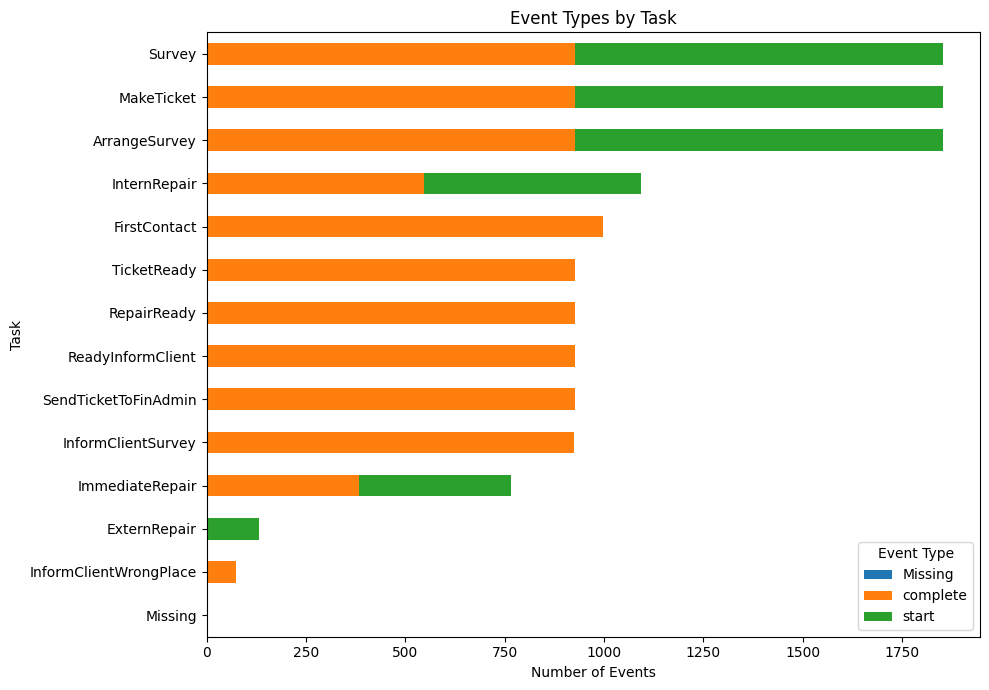

In [10]:
# 업무별 이벤트 유형 집계
event_counts = pd.crosstab(
    df['taskID'].fillna('Missing'),
    df['eventtype'].fillna('Missing')
)

# 이벤트 수가 많은 업무부터 정렬
event_counts = event_counts.loc[
    event_counts.sum(axis=1).sort_values().index
]

# 시각화
event_counts.plot.barh(stacked=True, figsize=(10, 7))

plt.xlabel('Number of Events')
plt.ylabel('Task')
plt.title('Event Types by Task')
plt.legend(title='Event Type')
plt.tight_layout()
plt.show()

**분석 결과 기록**
- 업무에 따라 시작과 완료가 모두 기록되거나 한쪽 이벤트만 기록되는 차이가 확인됨
- ExternRepair는 시작 이벤트만 132건 기록되어 있으며 완료 이벤트는 확인되지 않음
- eventtype 결측값이 5건 존재함.

### B. 케이스별 업무 구성


#### 7-4. 케이스별 이벤트 수
요청마다 기록 수는 얼마나 다르고 그 차이는 어떤 의미인가?

In [11]:
# 케이스별 이벤트 수 집계
case_counts = df['caseID'].value_counts()

# 이벤트 수의 분포 확인
print('최소:', case_counts.min())
print('평균:', case_counts.mean())
print('중앙값:', case_counts.median())
print('최대:', case_counts.max())
print('===='*20)

# 이벤트 수가 많은 상위 10개 케이스
print(case_counts.sort_values(ascending=False).head(10))

최소: 2
평균: 13.262
중앙값: 14.0
최대: 18
caseID
512    18
865    18
456    17
775    17
613    17
41     17
653    17
776    17
425    16
904    16
Name: count, dtype: int64


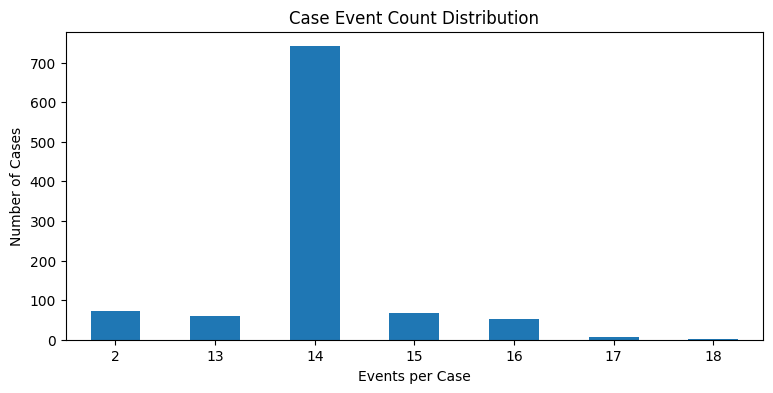

In [12]:

# 케이스별 이벤트 수
case_counts = df['caseID'].value_counts()

# 이벤트 수별 케이스 분포
event_dist = case_counts.value_counts().sort_index()

event_dist.plot.bar(figsize=(9, 4))
plt.xlabel('Events per Case')
plt.ylabel('Number of Cases')
plt.title('Case Event Count Distribution')
plt.xticks(rotation=0)  # X축 숫자를 가로로 표시
plt.show()

**분석 결과 기록**

- 케이스별 이벤트 수의 평균은 13.26건이지만 중앙값과 최빈값은 모두 14건으로 나타남
- 전체 케이스의 74.1%가 14개 이벤트에 집중되어 있으며 이벤트 수가 2개인 케이스가 평균에 영향을 미치므로 일반적인 이벤트 수를 설명하는 지표로 중앙값을 선택함
- 단 이벤트 수가 2개이거나 17~18개인 케이스가 반드시 통계적 이상치인 것은 아님. 따라서 실제 업무 구성의 차이인지 확인 필요

#### 7-5. 케이스별 업무 종류 수
이벤트가 많은 케이스는 실제로 업무 종류도 많은가?


In [13]:
# 케이스별 업무 종류 수
case_task_kinds = df.groupby('caseID')['taskID'].nunique()

# 업무 종류 수의 분포
print(case_task_kinds.value_counts().sort_index())

taskID
2      73
9       1
10    836
11     85
12      5
Name: count, dtype: int64


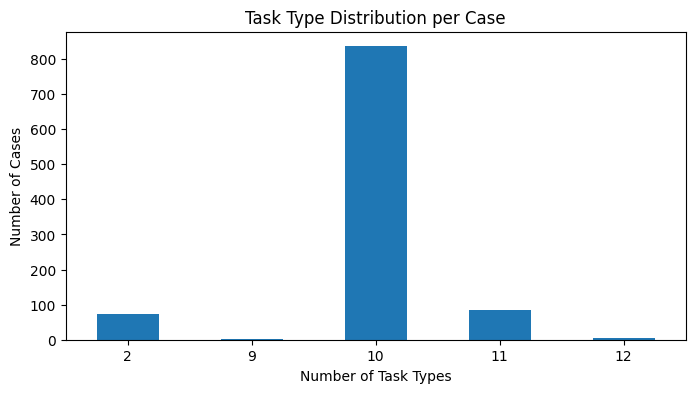

In [14]:
# 케이스별 업무 종류 수
case_task_kinds = df.groupby('caseID')['taskID'].nunique()

# 업무 종류 수별 케이스 분포
task_dist = case_task_kinds.value_counts().sort_index()

# 시각화
task_dist.plot.bar(figsize=(8, 4))

plt.xlabel('Number of Task Types')
plt.ylabel('Number of Cases')
plt.title('Task Type Distribution per Case')
plt.xticks(rotation=0)
plt.show()

**분석 결과 기록**

- 앞선 분석에서는 케이스별 이벤트 수를 확인했으나 하나의 업무에서 start와 complete가 각각 기록될 수 있어 이벤트 수와 실제 업무 종류 수가 다르다는 점을 확인함
- 이에 케이스별 중복되지 않는 taskID의 개수를 집계하여 업무 종류 수의 분포를 분석함
- 분석 결과 전체 1,000개 케이스 중 836건(83.6%)이 10종류의 업무를 포함하며 가장 일반적인 구성 규모로 나타남
- 다만 업무 종류 수가 같더라도 실제 업무 조합은 다를 수 있으므로 다음 분석에서 케이스별 업무 구성을 비교할 예정임


#### 7-6. 업무 조합과 대표 사례
같은 종류 수를 가진 케이스도 업무 조합이 다른가?

In [15]:
# 케이스별 중복·결측을 제외한 업무 조합 생성
case_patterns = df.groupby('caseID')['taskID'].agg(lambda x: tuple(sorted(x.dropna().unique()))
)
# 전체 업무 조합의 종류 수 확인 (중복 제거)
print('전체 업무 조합 수:', case_patterns.nunique())
print('====='*20)

# 서로 다른 10가지 업무 조합과 각 조합에 해당하는 케이스 수를 출력
print('\n' + case_patterns.value_counts().to_string())

전체 업무 조합 수: 10

taskID
(ArrangeSurvey, FirstContact, InformClientSurvey, InternRepair, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                                   454
(ArrangeSurvey, FirstContact, ImmediateRepair, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                                322
(FirstContact, InformClientWrongPlace)                                                                                                                                                    73
(ArrangeSurvey, ExternRepair, FirstContact, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                                    59
(ArrangeSurvey, ExternRepair, FirstContact, ImmediateRepair, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                   37
(ArrangeSurvey, ExternRepair, Fi

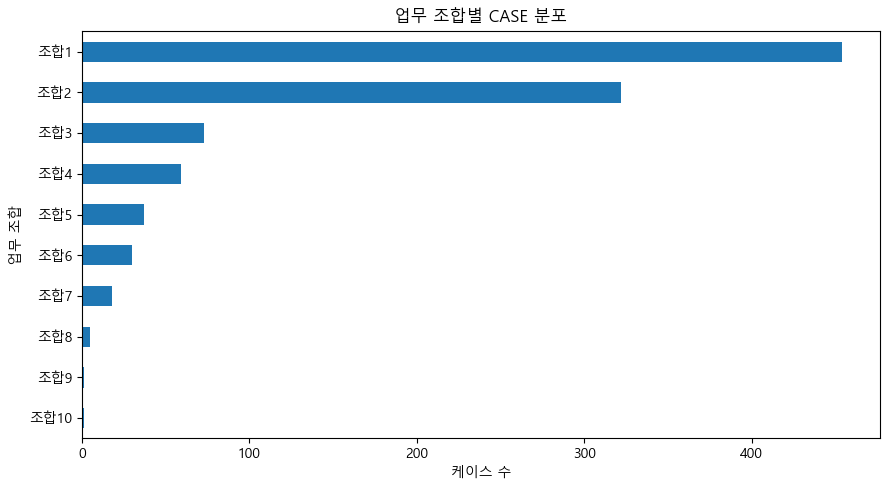

                                                                                                                                                                         task_pattern  case_count pattern_id
                               (ArrangeSurvey, FirstContact, InformClientSurvey, InternRepair, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)         454        조합1
                            (ArrangeSurvey, FirstContact, ImmediateRepair, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)         322        조합2
                                                                                                                                               (FirstContact, InformClientWrongPlace)          73        조합3
                               (ArrangeSurvey, ExternRepair, FirstContact, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady

In [16]:
# 한글 폰트 설정
from matplotlib import font_manager
font_names = {font.name for font in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = (
    'Malgun Gothic' if 'Malgun Gothic' in font_names else 'NanumGothic'
    if 'NanumGothic' in font_names else 'DejaVu Sans'
)
plt.rcParams['axes.unicode_minus'] = False

# 업무 조합별 케이스 수
pattern_counts = case_patterns.value_counts()

# 업무 조합에 번호 부여
pattern_df = pattern_counts.reset_index()
pattern_df.columns = ['task_pattern', 'case_count']
pattern_df['pattern_id'] = [
    f'조합{i+1}' for i in range(len(pattern_df))
]

# 시각화
pattern_df.plot.barh(
    x='pattern_id',
    y='case_count',
    figsize=(9, 5),
    legend=False
)

plt.gca().invert_yaxis()
plt.xlabel('케이스 수')
plt.ylabel('업무 조합')
plt.title('업무 조합별 CASE 분포')
plt.tight_layout()
plt.show()

# 조합별 실제 업무 구성 확인
print(pattern_df.to_string(index=False))

**분석 결과 기록**
- 전체 1,000개 케이스에서 총 10가지 업무 조합이 확인됨
- InternRepair를 포함한 조합이 454건(45.4%)으로 가장 많았으며 ImmediateRepair를 포함한 조합이 322건(32.2%)으로 그다음으로 많았음
- FirstContact와 InformClientWrongPlace만 포함된 케이스도 73건(7.3%) 확인되어 별도의 처리 경로가 존재할 가능성이 있음
- 다만 업무 조합은 업무의 포함 여부만 나타내므로 실제 수행 순서와 반복 여부는 확인할 수 없음


### C. 요청 속성 정리


#### 7-7. 접수 채널
어떤 채널로 접수됐으며 접수 채널별로 값이 일관되는가?


In [17]:
# 케이스별 접수 채널 추출
case_contact = df.groupby('caseID')['contact'].first()

# 접수 채널별 케이스 수
print(case_contact.value_counts(dropna=False))

# 접수 채널의 결측 및 중복 기록 확인
print('채널 미기록 케이스:', case_contact.isna().sum())
print('복수 채널 기록 케이스:',
      (df.groupby('caseID')['contact'].nunique() > 1).sum())

contact
Phone       270
Web         265
Personal    240
Letter      225
Name: count, dtype: int64
채널 미기록 케이스: 0


복수 채널 기록 케이스: 0


**분석 결과 기록**

- Phone(27.0%)과 Web(26.5%)의 접수 비중이 가장 높았으나 Personal(24.0%)과 Letter(22.5%)를 포함한 전체 채널의 요청 비중은 비교적 고르게 분포함
- 접수 채널이 누락되거나 하나의 케이스에 복수 채널이 기록된 사례는 확인되지 않음.

#### 7-8. 수리 속성
- 수리 방식·내부 수리 여부 등의 요청별 분포는 어떠한가?
- `RepairType`, `RepairInternally`, `RepairCode`, `EstimatedRepairTime`과 같이 결측치가 많았던 칼럼들을 기준으로 확인

In [18]:
# 수리 속성 컬럼 정의
repair_cols = ['RepairType', 'RepairInternally', 'RepairCode']

# 각 컬럼에서 첫 번째 결측이 아닌 값 출력
case_repair = df.groupby('caseID')[repair_cols].first()

# 수리 속성별 요청 수 확인
for col in repair_cols:
    print(f'\n=== {col} ===')
    print(case_repair[col].value_counts(dropna=False))

print("===="*20)

# 케이스 내 서로 다른 속성값 존재 여부 확인
for col in repair_cols:
    conflicts = (df.groupby('caseID')[col].nunique() > 1).sum()
    print(f'{col} 값 충돌 케이스: {conflicts}')


=== RepairType ===
RepairType
P       439
E       370
B       118
None     73
Name: count, dtype: int64

=== RepairInternally ===
RepairInternally
True     868
<NA>      73
False     59
Name: count, dtype: Int64

=== RepairCode ===
RepairCode
1.0    550
2.0    224
3.0     94
NaN     73
4.0     59
Name: count, dtype: int64
RepairType 값 충돌 케이스: 0
RepairInternally 값 충돌 케이스: 0
RepairCode 값 충돌 케이스: 0


**분석 결과 기록**

- 이벤트 단위에서 약 93%였던 수리 속성 컬럼의 결측률이 케이스 단위에서는 7.3%로 확인됨
- RepairType은 P(43.9%)와 E(37.0%)가 대부분을 차지했으며 RepairInternally는 내부 수리(True)가 86.8%로 가장 높게 나타남
- RepairCode는 1번 유형이 55.0%로 가장 많았으며 세 컬럼 모두 동일 케이스 내 값 충돌은 확인되지 않음
- 세 컬럼에서 공통적으로 73개 케이스의 정보가 누락됨.


----

## 8. 프로세스 시작·종료 후보 파악

**분석 목적:** 시간 정보를 사용하기 전에 업무 구성만으로 시작과 종료에 해당할 가능성이 있는 업무를 확인한다.

**앞 단계와의 연결·다음 작업:** 7단계에서 확인한 업무 조합을 바탕으로 시작·종료 후보를 정리한다. 실제 순서를 확인하려면 날짜를 믿을 수 있어야 하므로, 다음에는 날짜 검증을 진행한다.

**산출물:** 시작·종료 업무 후보와 업무 구성에 따른 종료 유형 후보

> **주의:** 아직 시간순으로 확인하지 않았으므로 실제 첫 번째·마지막 업무라고 확정하지 않는다. 업무 이름만으로 정상 완료를 확정하지 않는다.


#### 8-1. 시작 업무 후보 확인

**확인할 내용**

- FirstContact 등 접수 관련 업무의 케이스별 기록 여부 확인
- 최초 접수 업무 기록 없이 남아 있는 케이스가 있는지 확인

In [19]:
from IPython.display import display

# 케이스별 업무 존재 여부
case_tasks = pd.crosstab(df['caseID'], df['taskID']).gt(0)

# 시작 및 종료 관련 업무별 케이스 수
check_tasks = [
    'FirstContact',
    'MakeTicket',
    'InformClientWrongPlace',
    'RepairReady',
    'TicketReady',
    'ReadyInformClient'
]

task_summary = case_tasks[check_tasks].sum().to_frame('케이스 수')
display(task_summary)

# FirstContact 미기록 케이스
missing_contact = case_tasks.index[~case_tasks['FirstContact']]
display(pd.DataFrame({'FirstContact 미기록 caseID': missing_contact}))

# 종료 경로 조합
end_paths = pd.crosstab(
    case_tasks['InformClientWrongPlace'],
    case_tasks['TicketReady']
)

display(end_paths)

,케이스 수
taskID,
FirstContact,999
MakeTicket,927
InformClientWrongPlace,73
RepairReady,927
TicketReady,927
ReadyInformClient,927


,FirstContact 미기록 caseID
0,245


TicketReady,False,True
InformClientWrongPlace,,
False,0,927
True,73,0


**분석 결과 기록**

- 전체 1,000개 케이스 중 999개에서 FirstContact가 기록되었으며 1개 케이스(caseID 245)에서는 기록되지 않음
- TicketReady는 927개 케이스(92.7%)에서 확인되었고 InformClientWrongPlace는 73개 케이스(7.3%)에서 확인됨
- 두 업무가 동일한 케이스에서 함께 나타나거나 모두 누락된 사례는 없어 서로 다른 두 가지 처리 경로가 존재할 것으로 예상


#### 8-2. 종료 업무 후보 확인

- TicketReady, ReadyInformClient, InformClientWrongPlace 등 종료 관련 업무 확인
- 가설: 정상적인 프로세스 외에 별도의 프로세스가 존재할 것이다.

In [20]:
# 케이스별 프로세스 유형 분류
case_paths = case_tasks['InformClientWrongPlace'].map({
    True: '예외 처리 경로',
    False: '일반 프로세스'
}).rename('프로세스 유형')

# 프로세스 유형별 업무 구성 비교
path_tasks = case_tasks.groupby(case_paths).sum().T
display(path_tasks)

# 프로세스 유형별 수리 속성 기록 여부 비교
repair_missing = case_repair['RepairType'].isna()

display(pd.crosstab(
    case_paths,
    repair_missing
).rename(columns={False: '기록', True: '미기록'}))

프로세스 유형,예외 처리 경로,일반 프로세스
taskID,,
ArrangeSurvey,0,927
ExternRepair,0,132
FirstContact,73,926
ImmediateRepair,0,383
InformClientSurvey,0,926
InformClientWrongPlace,73,0
InternRepair,0,508
MakeTicket,0,927
ReadyInformClient,0,927


RepairType,기록,미기록
프로세스 유형,,
예외 처리 경로,0,73
일반 프로세스,927,0


**분석 결과 기록**

- 전체 1,000개 케이스는 일반 프로세스 927건(92.7%)과 예외 처리 경로 73건(7.3%)으로 구분됨
- 예외 처리 경로는 FirstContact와 InformClientWrongPlace만 기록되었으며 일반 프로세스의 수리 관련 업무는 나타나지 않음
- RepairType이 미기록된 73개 케이스는 모두 예외 처리 경로에 해당
- 일반 프로세스에서는 InternRepair 508건, ImmediateRepair 383건, ExternRepair 132건이 확인되었으며 한 케이스에 여러 수리 업무가 포함될 가능성이 있음

----

## 9. 날짜 검증 및 복원
시간순 업무 분석과 처리 시간 계산에 사용할 날짜의 신뢰성을 확보


#### 9-1. 날짜 이상 패턴 확인
- 1905년, 1970년, 2020~2022년 데이터 분포 확인
- 이상 날짜가 특정 이벤트나 케이스에 집중되는지 확인

In [21]:
import matplotlib.pyplot as plt

# 연도별 이벤트 분포
year_counts = (
    df['timestamp'].dt.year
    .value_counts(dropna=False)
    .sort_index()
)

display(year_counts.to_frame('이벤트 수'))

# 여러 연도가 기록된 케이스 확인
# 임시 칼럼을 추가하여 복사본 생성
case_years = df.assign(
    year=df['timestamp'].dt.year
).groupby('caseID')['year'].nunique()

print('여러 연도가 기록된 케이스:', (case_years > 1).sum())

# 2020~2022년 이벤트 확인
date_anomaly = df[df['timestamp'].dt.year.between(2020, 2022)].copy()

print('2020~2022년 이벤트 수:', len(date_anomaly))
print('최소 행 인덱스:', date_anomaly.index.min())
print('최대 행 인덱스:', date_anomaly.index.max())

# 날짜가 하루씩 증가하는지 확인
date_only = date_anomaly['timestamp'].dt.normalize()

print(
    '날짜가 모두 하루 간격인가?:',
    date_only.diff().dropna().eq(pd.Timedelta(days=1)).all()
)

,이벤트 수
timestamp,
1905.0,6
1970.0,12383
2020.0,361
2021.0,365
2022.0,134
NaN,13


여러 연도가 기록된 케이스: 595
2020~2022년 이벤트 수: 860
최소 행 인덱스: 0
최대 행 인덱스: 859
날짜가 모두 하루 간격인가?: True


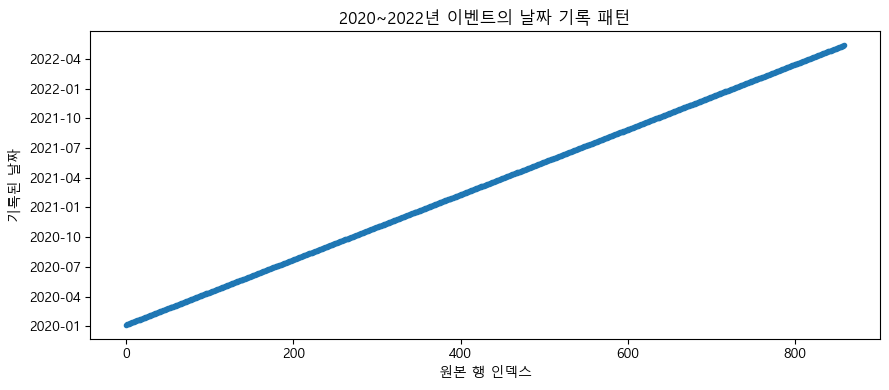

In [22]:
# 원본 행 순서별 날짜 변화
plt.figure(figsize=(9, 4))
plt.plot(date_anomaly.index, date_only, marker='.', linewidth=1)

plt.title('2020~2022년 이벤트의 날짜 기록 패턴')
plt.xlabel('원본 행 인덱스')
plt.ylabel('기록된 날짜')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 전체 13,262개 이벤트 중 1970년 기록이 12,383건으로 대부분을 차지하며 1905년 6건과 2020~2022년 860건도 확인됨
- 날짜 결측은 13건
- 2020~2022년 이벤트 860건은 원본 데이터의 0~859번 인덱스에 연속적으로 위치하며 날짜가 하루씩 증가하는 모습을 보임
- 동일한 케이스 내에서 서로 다른 연도가 기록된 사례가 595건 확인됨
- 특정 행 구간에서 규칙적인 날짜 증가가 확인되어 데이터 생성 또는 변환 과정에서 날짜가 변경되었을 가능성이 있음


#### 9-2. 동일 케이스 내 시간 정합성 점검
동일 케이스 내 업무의 시작,완료 시각을 비교하여 날짜 기록의 정합성을 검증
- 가설: 데이터 기록 또는 변환 과정에서 일부 이벤트의 날짜가 잘못 변경되어 동일 케이스 내 업무의 시작과 완료 시각에 비정상적인 차이가 발생했을 것이다.

In [23]:
# 시작·완료 이벤트만 선택
events = df[df['eventtype'].isin(['start', 'complete'])].copy()

# 케이스와 업무별 시작·완료 기록 수 확인
pair_counts = (
    events.groupby(['caseID', 'taskID', 'eventtype'])
    .size()
    .unstack(fill_value=0)
)

# 시작과 완료가 각각 1번씩 기록된 업무 선택
valid_keys = pair_counts[
    (pair_counts['start'] == 1) &
    (pair_counts['complete'] == 1)
].index

# 시작·완료 시각을 하나의 행으로 정리
paired_events = events.set_index(['caseID', 'taskID']).loc[valid_keys].reset_index()

pairs = paired_events.pivot(
    index=['caseID', 'taskID'],
    columns='eventtype',
    values='timestamp'
).reset_index()

# 시작·완료 시간 차이 계산
pairs['duration_hours'] = (
    pairs['complete'] - pairs['start']
).dt.total_seconds() / 3600

# 연도 불일치 여부
pairs['year_mismatch'] = (
    pairs['start'].notna() &
    pairs['complete'].notna() &
    (pairs['start'].dt.year != pairs['complete'].dt.year)
)

In [24]:
# 시간 정합성 요약
summary = pd.DataFrame({
    '건수': [
        len(pairs),
        pairs['duration_hours'].notna().sum(),
        (pairs['duration_hours'] < 0).sum(),
        pairs['year_mismatch'].sum()
    ]
}, index=[
    '시작·완료 1:1 업무',
    '시간 비교 가능',
    '완료가 시작보다 빠른 업무',
    '시작·완료 연도 불일치'
])

display(summary)

# 시간이 역전된 업무 사례
display(
    pairs[pairs['duration_hours'] < 0]
    .sort_values('duration_hours')
    .head(10)
)

,건수
시작·완료 1:1 업무,3631
시간 비교 가능,3627
완료가 시작보다 빠른 업무,226
시작·완료 연도 불일치,474


eventtype,caseID,taskID,complete,start,duration_hours,year_mismatch
940,260,ArrangeSurvey,1970-01-04 04:37:00,2022-05-01 04:34:00,-458639.950000,True
293,84,ArrangeSurvey,1970-01-07 12:50:00,2022-04-28 12:46:00,-458495.933333,True
2616,716,InternRepair,1970-01-12 05:44:00,2022-05-02 01:20:00,-458467.600000,True
1944,532,Survey,1970-01-03 05:34:00,2022-04-18 04:51:00,-458351.283333,True
2855,787,ArrangeSurvey,1970-01-03 14:16:00,2022-04-13 14:14:00,-458231.966667,True
1111,306,ArrangeSurvey,1970-01-02 15:11:00,2022-04-10 15:08:00,-458183.950000,True
3141,870,ArrangeSurvey,1970-01-07 14:50:00,2022-04-07 09:14:00,-457986.400000,True
345,97,InternRepair,1970-01-03 01:56:00,2022-03-31 22:16:00,-457940.333333,True
3260,902,ArrangeSurvey,1970-01-07 14:07:00,2022-04-02 12:24:00,-457870.283333,True
3516,971,MakeTicket,1970-01-03 17:25:00,2022-03-23 17:17:00,-457727.866667,True


In [25]:
# 시작 연도와 완료 연도 교차표
year_comparison = pd.crosstab(
    pairs['start'].dt.year,
    pairs['complete'].dt.year
)

display(year_comparison)

complete,1970.0,2020.0,2021.0,2022.0
start,,,,
1905.0,2,0,0,0
1970.0,3151,97,107,36
2020.0,93,0,3,2
2021.0,96,2,2,1
2022.0,32,3,0,0


**분석 결과 기록**

- 시작과 완료가 각각 1회 기록된 업무 3,631건 중 3,627건에서 시간 비교
- 226건(6.2%)에서 완료 시각이 시작 시각보다 빠른 시간 역전 현상이 확인됨
- 시작과 완료 연도가 다른 업무는 474건으로 확인됐으며 시간 역전 226건 모두 연도 불일치 사례에 해당
- 시간 역전 226건 중 221건은 2020~2022년에 시작되어 1970년에 완료된 것으로 기록됨


#### 9-3. 날짜 복원 가능성 검토
2020~2022년으로 기록된 이벤트에서 날짜만 변경되고 시각은 유지되었는지 확인

In [26]:
# 비교할 이벤트 추출
anomaly = df.loc[
    df['timestamp'].dt.year.between(2020, 2022),
    ['caseID', 'taskID', 'timestamp']
].copy()
anomaly['row_id'] = anomaly.index

normal = df.loc[
    df['timestamp'].dt.year.eq(1970),
    ['caseID', 'taskID', 'timestamp']
].copy()

# 시각(HH:MM)만 추출
anomaly['clock'] = anomaly['timestamp'].dt.strftime('%H:%M')
normal['clock'] = normal['timestamp'].dt.strftime('%H:%M')

# 1970년 비교 데이터의 컬럼명 변경
normal = normal.rename(columns={
    'taskID': 'ref_task',
    'timestamp': 'ref_timestamp'
})

# 동일 케이스에서 시각이 일치하는 이벤트 연결
matches = anomaly.merge(
    normal[['caseID', 'clock', 'ref_task', 'ref_timestamp']],
    on=['caseID', 'clock'],
    how='left'
)

# 이상 이벤트별 서로 다른 날짜 후보 개수
candidate_counts = matches.groupby('row_id')['ref_timestamp'].nunique()

summary = pd.DataFrame({
    '구분': ['일치 없음', '후보 1개', '후보 2개 이상'],
    '이벤트 수': [
        (candidate_counts == 0).sum(),
        (candidate_counts == 1).sum(),
        (candidate_counts > 1).sum()
    ]
})

display(summary)

# 날짜 복원 후보 사례 확인
display(matches.loc[
    matches['ref_timestamp'].notna(),
    ['row_id', 'caseID', 'taskID', 'timestamp', 'ref_task', 'ref_timestamp']
].head(10))

,구분,이벤트 수
0,일치 없음,224
1,후보 1개,634
2,후보 2개 이상,2


,row_id,caseID,taskID,timestamp,ref_task,ref_timestamp
0,0,419,InformClientSurvey,2020-01-06 11:51:00,ArrangeSurvey,1970-01-06 11:51:00
1,1,561,ArrangeSurvey,2020-01-07 13:48:00,InformClientSurvey,1970-01-04 13:48:00
5,5,450,TicketReady,2020-01-11 21:48:00,ReadyInformClient,1970-01-03 21:48:00
6,6,521,MakeTicket,2020-01-12 20:30:00,ArrangeSurvey,1970-01-02 20:30:00
8,8,604,MakeTicket,2020-01-14 18:37:00,FirstContact,1970-01-04 18:37:00
10,10,460,ArrangeSurvey,2020-01-16 08:37:00,InformClientSurvey,1970-01-03 08:37:00
11,11,870,TicketReady,2020-01-17 15:49:00,ReadyInformClient,1970-01-14 15:49:00
12,12,340,ArrangeSurvey,2020-01-18 23:18:00,MakeTicket,1970-01-07 23:18:00
14,14,325,RepairReady,2020-01-20 20:00:00,InternRepair,1970-01-06 20:00:00
17,17,447,FirstContact,2020-01-23 22:19:00,MakeTicket,1970-01-04 22:19:00


In [27]:
# 1905년 이벤트의 시간 확인
old_events = df[df['timestamp'].dt.year.eq(1905)]

display(old_events[
    ['caseID', 'taskID', 'eventtype', 'timestamp']
])

,caseID,taskID,eventtype,timestamp
1378,265,FirstContact,complete,1905-05-23
1880,180,MakeTicket,start,1905-05-23
5903,1,FirstContact,complete,1905-05-23
6333,318,MakeTicket,start,1905-05-23
8203,959,TicketReady,complete,1905-05-23
11301,992,SendTicketToFinAdmin,complete,1905-05-23


**분석 결과 기록**

- 2020~2022년 이벤트 860건 중 636건(74.0%)에서 동일 케이스의 1970년 이벤트와 시각이 일치하는 기록이 확인됨
- 이 중 634건은 일치하는 1970년 날짜,시각 후보가 1개였으며 2건은 후보가 2개 이상으로 나타남. 나머지 224건은 일치하는 기록이 없었음
- 일부 이벤트에서 날짜는 차이가 나지만 시각은 동일하게 기록되어 있어 날짜만 변경되고 시각은 유지되었을 가능성이 확인됨
- 1905년 이벤트 6건은 모두 1905-05-23 00:00으로 기록되어 있어 별도의 오류 의심


#### 9-4. 날짜 보정 규칙의 타당성 검증 및 처리 방향 결정
이상 패턴을 바탕으로 객관적인 규칙을 설정할 수 있는지 검토하고 이후 시간 분석에 사용할 데이터 처리 방향을 결정


##### 9-4-1. 날짜 보정 가능성 검토
2020~2022년의 날짜는 원본 행 순서에 따라 인위적으로 기록된 것일까?


In [28]:
# 2020~2022년 이벤트 추출
suspect = df[
    df['timestamp'].dt.year.between(2020, 2022)
].sort_index().copy()

# 첫 날짜를 기준으로 행 번호만큼 하루씩 증가한 날짜 생성
expected_dates = (
    suspect['timestamp'].dt.normalize().iloc[0]
    + pd.to_timedelta(suspect.index - suspect.index.min(), unit='D')
)

# 실제 날짜와 행 번호 기반 날짜 비교
matches_order = suspect['timestamp'].dt.normalize().eq(expected_dates)

print('검증 대상:', len(suspect))
print('행 번호 기반 날짜 규칙 일치:', matches_order.sum())
print('규칙 불일치:', (~matches_order).sum())

검증 대상: 860
행 번호 기반 날짜 규칙 일치: 860
규칙 불일치: 0


**분석 결과 기록**

- 하루씩 증가하는 날짜가 행 번호와 정확히 일치함을 확인
- 2020~2022년 날짜가 실제 업무 발생일보다 행 순서에 따라 생성된 값일 가능성이 높다


##### 9-4-2. 동일 시각을 활용한 보정 규칙 검증
동일한 시각의 이벤트가 발견됐을 때 서로 같은 업무인지 다른 업무인지 확인


In [29]:
# 동일 케이스·시각으로 연결된 이벤트
matched = matches[matches['ref_timestamp'].notna()].copy()

# 동일 시각 이벤트의 업무 일치 여부
matched['same_task'] = matched['taskID'].eq(matched['ref_task'])

summary = pd.DataFrame({
    '구분': ['시각 일치 이벤트', '동일 업무', '서로 다른 업무'],
    '이벤트 수': [
        matched['row_id'].nunique(),
        matched.loc[matched['same_task'], 'row_id'].nunique(),
        matched.loc[~matched['same_task'], 'row_id'].nunique()
    ]
})

display(summary)

# 실제 시각 일치 사례
display(matched[
    ['caseID', 'taskID', 'timestamp', 'ref_task', 'ref_timestamp']
].head(10))

,구분,이벤트 수
0,시각 일치 이벤트,636
1,동일 업무,0
2,서로 다른 업무,636


,caseID,taskID,timestamp,ref_task,ref_timestamp
0,419,InformClientSurvey,2020-01-06 11:51:00,ArrangeSurvey,1970-01-06 11:51:00
1,561,ArrangeSurvey,2020-01-07 13:48:00,InformClientSurvey,1970-01-04 13:48:00
5,450,TicketReady,2020-01-11 21:48:00,ReadyInformClient,1970-01-03 21:48:00
6,521,MakeTicket,2020-01-12 20:30:00,ArrangeSurvey,1970-01-02 20:30:00
8,604,MakeTicket,2020-01-14 18:37:00,FirstContact,1970-01-04 18:37:00
10,460,ArrangeSurvey,2020-01-16 08:37:00,InformClientSurvey,1970-01-03 08:37:00
11,870,TicketReady,2020-01-17 15:49:00,ReadyInformClient,1970-01-14 15:49:00
12,340,ArrangeSurvey,2020-01-18 23:18:00,MakeTicket,1970-01-07 23:18:00
14,325,RepairReady,2020-01-20 20:00:00,InternRepair,1970-01-06 20:00:00
17,447,FirstContact,2020-01-23 22:19:00,MakeTicket,1970-01-04 22:19:00


**분석 결과 기록**

- 동일 시각으로 연결된 636건 모두 서로 다른 업무의 기록으로 확인됨
- 업무 간 전환 시각은 유지되었지만 날짜가 잘못 기록되었을 가능성이 있음
- 즉 임의로 날짜를 수정하는 것은 위험함


##### 9-4-3. 날짜 처리 방향 결정


In [30]:
# 날짜 처리 방향: 원본 보존, 임의 보정 제외
df['date_status'] = '검증 필요'

df.loc[df['timestamp'].dt.year.eq(1970), 'date_status'] = '1970년 기록'
df.loc[df['timestamp'].dt.year.between(2020, 2022), 'date_status'] = '날짜 이상 의심'
df.loc[df['timestamp'].dt.year.eq(1905), 'date_status'] = '날짜 이상 의심'
df.loc[df['timestamp'].isna(), 'date_status'] = '날짜 결측'

display(df['date_status'].value_counts().to_frame('이벤트 수'))

,이벤트 수
date_status,
1970년 기록,12383
날짜 이상 의심,866
날짜 결측,13


**분석 결과 기록**
- 날짜 원본은 유지하고 시간 분석에 사용할 수 있는 이벤트와 케이스의 범위를 별도로 결정


#### 9-5. 시간 분석 대상 확정
날짜 이상이 있는 상황에서 전체 프로세스 분석과 처리 시간 분석에 각각 어떤 데이터를 사용할 수 있을까?
- 1970년 기록을 정상 날짜로 확정한 것은 아니다. 단지 다른 연도가 섞이지 않은 상대적으로 일관된 기록을 우선 분석 대상으로 사용하는 보수적인 기준

In [31]:
# 업무별 시간 분석 대상
pair_time_ok = (
    pairs['start'].dt.year.eq(1970) &
    pairs['complete'].dt.year.eq(1970) &
    (pairs['complete'] >= pairs['start'])
)

time_pairs = pairs[pair_time_ok].copy()

# 케이스별 시간 분석 대상
case_time_ok = df.groupby('caseID')['timestamp'].agg(
    lambda x: x.notna().all() and x.dt.year.eq(1970).all()
)

time_case_ids = case_time_ok[case_time_ok].index
time_cases = df[df['caseID'].isin(time_case_ids)].copy()

# 분석 대상 규모 비교
summary = pd.DataFrame({
    '분석 대상': ['프로세스 경로', '업무 처리 시간', '케이스 관찰 시간'],
    '전체': [df['caseID'].nunique(), len(pairs), df['caseID'].nunique()],
    '사용 가능': [df['caseID'].nunique(), len(time_pairs), len(time_case_ids)]
})

summary['사용 비율(%)'] = (
    summary['사용 가능'] / summary['전체'] * 100
).round(1)

display(summary)

,분석 대상,전체,사용 가능,사용 비율(%)
0,프로세스 경로,1000,1000,100.0
1,업무 처리 시간,3631,3151,86.8
2,케이스 관찰 시간,1000,402,40.2


In [32]:
# 프로세스 유형별 시간 분석 대상 비교
time_coverage = pd.crosstab(
    case_paths,
    case_time_ok
).rename(columns={
    False: '분석 제외',
    True: '분석 가능'
})

time_coverage['분석 가능 비율(%)'] = (
    time_coverage['분석 가능'] /
    time_coverage[['분석 제외', '분석 가능']].sum(axis=1) * 100
).round(1)

display(time_coverage)

timestamp,분석 제외,분석 가능,분석 가능 비율(%)
프로세스 유형,,,
예외 처리 경로,10,63,86.3
일반 프로세스,588,339,36.6


**분석 결과 기록**

- 프로세스 경로 및 업무 구성 분석에는 전체 1,000개 케이스를 활용할 수 있음
- 업무 처리 시간은 시작·완료가 1:1로 연결된 3,631건 중 3,151건(86.8%)이 1970년 기록과 시간 역전이 없는 조건을 충족함
- 케이스 전체 관찰 시간은 모든 이벤트에 시각이 존재하고 연도가 1970년으로 일치하는 402개 케이스(40.2%)에서 계산 가능함
- 시간 분석 기준을 충족한 비율은 일반 프로세스 36.6%(339건), 예외 처리 경로 86.3%(63건)로 차이가 나타남

업무 구성 및 유형 분석에는 전체 1,000개 케이스를 활용하되 시간순 분석은 날짜 정합성이 검증된 데이터로 제한한다. 개별 업무 3,151건과 전체 이벤트의 연도가 일치하는 케이스 402건을 시간 분석의 1차 후보로 선정했으며 실제 사용 여부는 추가 검증을 통해 결정한다.


----

## 10. 프로세스 흐름 및 분기 분석

실제 시간순 이벤트를 통해 수리 요청의 진행 과정과 주요 분기점을 확인

#### 10-1. 대표 케이스의 업무 진행 순서 확인
- 일반적인 업무 조합의 케이스 확인
- 이벤트 수가 적은 케이스와 많은 케이스 비교

In [33]:
# 케이스별 이벤트 수
case_counts = time_cases.groupby('caseID').size()

# 이벤트 수에 따른 대표 케이스 선정
sample_cases = {
    '일반 케이스': case_counts[case_counts == 14].index[0],
    '예외 케이스': case_counts[case_counts == 2].index[0],
    '복합 케이스': case_counts[case_counts == 17].index[0]
}

# 대표 케이스별 시간순 이벤트 확인
for name, case_id in sample_cases.items():
    case_events = time_cases[
        time_cases['caseID'] == case_id
    ][['taskID', 'eventtype', 'timestamp']].copy()

    case_events = case_events.sort_values('timestamp', kind='stable')

    # 동일 시각에 기록된 이벤트 확인
    case_events['동일 시각'] = case_events['timestamp'].duplicated(keep=False)

    print(f'{name} | caseID: {case_id}')
    display(case_events.reset_index(drop=True))

일반 케이스 | caseID: 3


,taskID,eventtype,timestamp,동일 시각
0,FirstContact,complete,1970-01-03 01:03:00,True
1,MakeTicket,start,1970-01-03 01:03:00,True
2,MakeTicket,complete,1970-01-03 01:10:00,True
3,ArrangeSurvey,start,1970-01-03 01:10:00,True
4,InformClientSurvey,complete,1970-01-03 01:14:00,True
5,ArrangeSurvey,complete,1970-01-03 01:14:00,True
6,Survey,start,1970-01-06 06:31:00,False
7,Survey,complete,1970-01-06 06:47:00,False
8,InternRepair,start,1970-01-06 19:50:00,False
9,InternRepair,complete,1970-01-06 23:30:00,True


예외 케이스 | caseID: 6


,taskID,eventtype,timestamp,동일 시각
0,InformClientWrongPlace,complete,1970-01-03 02:29:00,True
1,FirstContact,complete,1970-01-03 02:29:00,True


복합 케이스 | caseID: 41


,taskID,eventtype,timestamp,동일 시각
0,FirstContact,complete,1970-01-01 15:15:00,True
1,MakeTicket,start,1970-01-01 15:15:00,True
2,MakeTicket,complete,1970-01-01 15:21:00,True
3,ArrangeSurvey,start,1970-01-01 15:21:00,True
4,InformClientSurvey,complete,1970-01-01 15:25:00,True
5,ArrangeSurvey,complete,1970-01-01 15:25:00,True
6,Survey,start,1970-01-01 16:45:00,False
7,ImmediateRepair,start,1970-01-01 17:35:00,True
8,Survey,complete,1970-01-01 17:35:00,True
9,ImmediateRepair,complete,1970-01-01 19:35:00,False


In [34]:
# Plotly가 없는 환경에서는 별도로 실행
# %pip install plotly
import plotly

In [35]:
import plotly.express as px

def plot_case_timeline(case_id):
    case = time_cases[time_cases['caseID'] == case_id].copy()
    case = case.dropna(subset=['timestamp'])
    case = case.sort_values('timestamp', kind='stable')

    # 업무를 처음 기록된 시각 순서로 정렬
    task_order = case['taskID'].dropna().unique().tolist()

    fig = px.scatter(
        case,
        x='timestamp',
        y='taskID',
        color='eventtype',
        symbol='eventtype',
        category_orders={'taskID': task_order},
        color_discrete_map={
            'start': '#E59A35',
            'complete': '#3183C9'
        },
        hover_data=['caseID'],
        title=f'Case {case_id} | 이벤트 타임라인',
        height=max(400, len(task_order) * 42 + 130)
    )

    fig.update_traces(marker_size=11)
    fig.update_layout(
        template='plotly_white',
        xaxis_title='이벤트 발생 시각',
        yaxis_title='업무',
        legend_title='이벤트 유형',
        margin=dict(l=30, r=30, t=70, b=40)
    )
    fig.update_yaxes(autorange='reversed')

    fig.show()

# 일반 / 예외 / 복합 케이스 확인
for name, case_id in sample_cases.items():
    print(name)
    plot_case_timeline(case_id)

일반 케이스


예외 케이스


복합 케이스


**분석 결과 기록**

- 일반 케이스에서는 접수부터 티켓 생성, 조사, 수리, 처리 완료에 이르는 주요 업무 흐름이 관찰됨
- 복합 케이스에서는 ImmediateRepair, InternRepair, ExternRepair 등 여러 수리 업무가 함께 나타나 단일 수리 경로로 구성되지 않을 가능성이 있음

#### 10-2. 업무 시작, 완료 이벤트 연결 검증
- start와 complete가 모두 존재하는 업무 확인
- 특정 업무에서 반복 실행이나 기록 누락이 발생하는가

In [36]:
# 시작·완료 기록 횟수에 따른 업무 분류
pair_status = pair_counts.copy()
pair_status['기록 유형'] = '기타'

pair_status.loc[
    (pair_status['start'] == 1) &
    (pair_status['complete'] == 1), '기록 유형'
] = '시작·완료 1:1'

pair_status.loc[
    (pair_status['start'] == 0), '기록 유형'
] = '완료만 기록'

pair_status.loc[
    (pair_status['complete'] == 0), '기록 유형'
] = '시작만 기록'

pair_status.loc[
    (pair_status['start'] > 1) |
    (pair_status['complete'] > 1), '기록 유형'
] = '반복 기록'

# 업무별 기록 유형 비교
task_status = pd.crosstab(
    pair_status.index.get_level_values('taskID'),
    pair_status['기록 유형']
)

display(task_status)

# 반복 기록 사례 확인
display(pair_status[pair_status['기록 유형'] == '반복 기록'].head(10))

기록 유형,반복 기록,시작·완료 1:1,시작만 기록,완료만 기록
row_0,,,,
ArrangeSurvey,0,926,0,1
ExternRepair,0,0,132,0
FirstContact,0,0,0,999
ImmediateRepair,0,382,0,1
InformClientSurvey,0,0,0,925
InformClientWrongPlace,0,0,0,73
InternRepair,38,470,0,0
MakeTicket,0,927,0,0
ReadyInformClient,0,0,0,927


,eventtype,complete,start,기록 유형
caseID,taskID,,,
12,InternRepair,2,2,반복 기록
39,InternRepair,2,2,반복 기록
52,InternRepair,2,2,반복 기록
62,InternRepair,2,2,반복 기록
73,InternRepair,2,2,반복 기록
84,InternRepair,2,2,반복 기록
111,InternRepair,2,2,반복 기록
124,InternRepair,2,2,반복 기록
143,InternRepair,2,2,반복 기록


In [37]:
# 시간 분석 후보 케이스에서 1:1 업무 추출
candidate_pairs = pairs[
    pairs['caseID'].isin(time_case_ids)
].copy()

# 시작·완료 시간 정합성 확인
time_check = pd.DataFrame({
    '건수': [
        len(candidate_pairs),
        (candidate_pairs['complete'] < candidate_pairs['start']).sum(),
        (candidate_pairs['complete'] == candidate_pairs['start']).sum(),
        (candidate_pairs['complete'] > candidate_pairs['start']).sum()
    ]
}, index=[
    '시작·완료 1:1 업무',
    '완료가 시작보다 빠름',
    '시작과 완료 시각 동일',
    '완료가 시작보다 늦음'
])

display(time_check)

,건수
시작·완료 1:1 업무,1326
완료가 시작보다 빠름,0
시작과 완료 시각 동일,0
완료가 시작보다 늦음,1326


**분석 결과 기록**

- FirstContact, TicketReady 등 일부 업무는 완료 이벤트만 기록되었으며 ExternRepair는 132개 케이스 모두 시작 이벤트만 기록됨
- InternRepair는 38개 케이스에서 시작 또는 완료 이벤트가 중복 기록되어 반복 수행 가능성이 있음
- 완료 시각이 시작 시각보다 빠른 사례는 확인되지 않음


#### 10-3. 주요 업무 경로 및 반복 수행 분석

##### 10-3-1. 일반·복합 케이스의 업무 구성 비교

**분석 질문:** 일반적인 케이스와 이벤트가 많은 케이스는 업무 구성이 어떻게 다를까?

- 대표 사례인 14개·17개 이벤트 케이스의 공통 업무와 추가 업무를 비교
- 이벤트 증가가 새로운 업무 추가 때문인지 기존 업무 반복 때문인지 구분하고 전체 케이스에서도 확인
- 결과는 업무 구성 비교표와 추가·반복 업무 목록으로 정리

In [38]:
# 비교할 대표 케이스
regular_id = sample_cases['일반 케이스']
complex_id = sample_cases['복합 케이스']

selected = df[df['caseID'].isin([regular_id, complex_id])]

# 케이스별 업무 기록 횟수 비교
task_compare = pd.crosstab(
    selected['taskID'],
    selected['caseID']
).rename(columns={
    regular_id: '일반 케이스',
    complex_id: '복합 케이스'
})

task_compare['차이'] = (
    task_compare['복합 케이스'] - task_compare['일반 케이스']
)

display(task_compare)

# 이벤트 수와 업무 종류 수 비교
case_compare = selected.groupby('caseID').agg(
    이벤트_수=('taskID', 'size'),
    업무_종류_수=('taskID', 'nunique')
)

display(case_compare)

caseID,일반 케이스,복합 케이스,차이
taskID,,,
ArrangeSurvey,2,2,0
ExternRepair,0,1,1
FirstContact,1,1,0
ImmediateRepair,0,2,2
InformClientSurvey,1,1,0
InternRepair,2,2,0
MakeTicket,2,2,0
ReadyInformClient,1,1,0
RepairReady,1,1,0


,이벤트_수,업무_종류_수
caseID,,
3,14,10
41,17,12


**분석 결과 기록**

- 복합 케이스의 이벤트가 3개 더 많은 이유가 기존 업무의 반복이 아니라 새로운  업무 2종류의 추가 때문이라는 사실이 확인됨
    - ImmediateRepair: 시작·완료 이벤트 2건 추가
    - ExternRepair: 시작 이벤트 1건 추가

##### 10-3-2. 반복 수행 케이스의 업무 조합 분석
InternRepair 반복 기록은 어떤 업무 조합에서 발생하며 조합별 반복 발생률에는 차이가 있을까?

- InternRepair 반복 기록이 확인된 38개 케이스를 7-6의 10가지 업무 조합과 연결
- 조합별 전체 케이스 수, 반복 발생 케이스 수, 반복 발생률을 비교. 발생률은 해당 조합의 전체 케이스 수를 분모로 계산
- ImmediateRepair·ExternRepair 포함 여부와의 관계를 확인

In [39]:
# 업무 조합에 번호 부여
pattern_counts = case_patterns.value_counts()

pattern_lookup = {
    pattern: f'조합{i}'
    for i, pattern in enumerate(pattern_counts.index, 1)
}

# InternRepair 시작·완료 기록 횟수
intern_counts = (
    df[df['taskID'] == 'InternRepair']
    .groupby(['caseID', 'eventtype'])
    .size()
    .unstack(fill_value=0)
)

# 시작 또는 완료가 2회 이상 기록된 케이스
repeat_ids = intern_counts.index[
    (intern_counts['start'] > 1) |
    (intern_counts['complete'] > 1)
]

# 케이스별 업무 조합과 반복 기록 여부 결합
case_repeat = pd.DataFrame({
    '업무 조합': [pattern_lookup[p] for p in case_patterns],
    '반복 기록': case_patterns.index.isin(repeat_ids)
}, index=case_patterns.index)

# 업무 조합별 반복 발생률
pattern_summary = (
    case_repeat.groupby('업무 조합')['반복 기록']
    .agg(전체_케이스='size', 반복_케이스='sum')
    .reindex([f'조합{i}' for i in range(1, len(pattern_counts) + 1)])
)

pattern_summary['반복률(%)'] = (
    pattern_summary['반복_케이스'] /
    pattern_summary['전체_케이스'] * 100
).round(1)

display(pattern_summary)

,전체_케이스,반복_케이스,반복률(%)
업무 조합,,,
조합1,454,36,7.9
조합2,322,0,0.0
조합3,73,0,0.0
조합4,59,0,0.0
조합5,37,0,0.0
조합6,30,1,3.3
조합7,18,1,5.6
조합8,5,0,0.0
조합9,1,0,0.0


**분석 결과 기록**

- 여러 수리 업무가 결합된 경로보다 InternRepair만 포함된 업무 조합에서 반복 기록이 더 많이 발견
- InternRepair가 반복 기록된 케이스에서는 내부 수리 업무가 여러 차례 수행되었을 가능성이 있다.


##### 10-3-3. 반복 업무의 실제 진행 순서 확인

- 같은 업무가 연속으로 수행될까, 다른 업무를 거친 뒤 다시 수행될까?
- InternRepair가 반복된 케이스에서는 첫 번째 수리가 완료된 후 두 번째 수리가 시작되는가? 반복 사이에 시간 간격이 존재하는가?

In [40]:
# InternRepair 이벤트 추출
intern = df[df['taskID'] == 'InternRepair'].copy()

# 시작 또는 완료가 2회 이상인 케이스
intern_counts = pd.crosstab(intern['caseID'], intern['eventtype'])

repeat_ids = intern_counts.index[
    (intern_counts['start'] > 1) |
    (intern_counts['complete'] > 1)
]

repeated = intern[intern['caseID'].isin(repeat_ids)].copy()

# InternRepair 이벤트의 날짜가 모두 1970년인 케이스 선택
valid_year = repeated.groupby('caseID')['timestamp'].agg(
    lambda x: x.notna().all() and x.dt.year.eq(1970).all()
)

valid_ids = valid_year[valid_year].index

# 검증 후보의 시간순 시작·완료 패턴
repeat_valid = repeated[
    repeated['caseID'].isin(valid_ids)
].sort_values(['caseID', 'timestamp'], kind='stable')

sequences = repeat_valid.groupby('caseID')['eventtype'].agg(
    lambda x: ' → '.join(x)
)

print('반복 기록 케이스:', len(repeat_ids))
print('InternRepair 날짜가 1970년인 케이스:', len(valid_ids))
print('전체 이벤트가 1970년인 케이스:',
      len(repeat_ids.intersection(time_case_ids)))

display(sequences.value_counts().to_frame('케이스 수'))

반복 기록 케이스: 38
InternRepair 날짜가 1970년인 케이스: 29
전체 이벤트가 1970년인 케이스: 12


,케이스 수
eventtype,
start → complete → start → complete,27
start → start → complete → complete,1
start → complete → start → complete → start → complete,1


In [41]:
# 반복 유형별 대표 사례
for case_id in [62, 124, 776]:
    print(f'\ncaseID: {case_id}')

    sample = intern[intern['caseID'] == case_id].sort_values(
        'timestamp', kind='stable'
    )

    display(sample[['eventtype', 'timestamp']])


caseID: 62


,eventtype,timestamp
1719,start,1970-01-07 18:44:00
3181,complete,1970-01-07 20:36:00
9596,start,1970-01-07 20:36:00
3733,complete,1970-01-07 23:00:00



caseID: 124


,eventtype,timestamp
9717,start,1970-01-18 11:41:00
1986,complete,1970-01-18 15:21:00
2028,start,1970-01-18 19:45:00
2127,complete,1970-01-18 23:03:00



caseID: 776


,eventtype,timestamp
7601,start,1970-01-03 14:06:00
7485,start,1970-01-03 16:54:00
8598,complete,1970-01-03 16:54:00
7706,complete,1970-01-03 19:42:00


**분석 결과 기록**

- 29건 중 28건에서는 한 번의 InternRepair가 완료된 뒤 다시 시작된 형태
- 단, 반복된 InternRepair가 반드시 같은 방식으로 발생하는 것은 아님


#### 10-4. 주요 분기 지점 도출

##### 10-4-1. 공통 업무 및 수리 경로별 분포 확인

- 같은 업무가 연속으로 수행될까, 다른 업무를 거친 뒤 다시 수행될까?
- InternRepair가 반복된 케이스에서는 첫 번째 수리가 완료된 후 두 번째 수리가 시작되는가? 반복 사이에 시간 간격이 존재하는가?
- 대부분의 수리 요청에 공통으로 나타나는 업무는 무엇이고 수리 방식은 몇 가지 조합으로 나뉘는가?
- 단, 공통 업무라는 사실이 업무의 진행 순서를 알려주지는 않는다

① 공통 업무 확인

In [42]:
# 일반 프로세스 케이스만 선택
general_tasks = case_tasks.loc[
    case_paths[case_paths == '일반 프로세스'].index
]

# 모든 케이스에 기록된 공통 업무 확인
common_tasks = general_tasks.columns[general_tasks.all()]

display(pd.DataFrame({'공통 업무': common_tasks}))

,공통 업무
0,ArrangeSurvey
1,MakeTicket
2,ReadyInformClient
3,RepairReady
4,SendTicketToFinAdmin
5,Survey
6,TicketReady


② 수리 업무 조합별 케이스 수 확인

In [43]:
# 주요 수리 업무
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

# 케이스별 수리 업무 조합 생성
repair_combinations = general_tasks[repair_tasks].apply(
    lambda row: ' + '.join(row.index[row]),
    axis=1
)

# 조합별 케이스 수 및 비율
combination_summary = (
    repair_combinations.value_counts()
    .rename_axis('수리 업무 조합')
    .reset_index(name='케이스 수')
)

combination_summary['비율(%)'] = (
    combination_summary['케이스 수'] / len(general_tasks) * 100
).round(1)

display(combination_summary)

,수리 업무 조합,케이스 수,비율(%)
0,InternRepair,455,49.1
1,ImmediateRepair,322,34.7
2,ExternRepair,59,6.4
3,ImmediateRepair + ExternRepair,38,4.1
4,InternRepair + ExternRepair,30,3.2
5,InternRepair + ImmediateRepair,18,1.9
6,InternRepair + ImmediateRepair + ExternRepair,5,0.5


④ 시각화 — 수리 업무 조합별 케이스 수


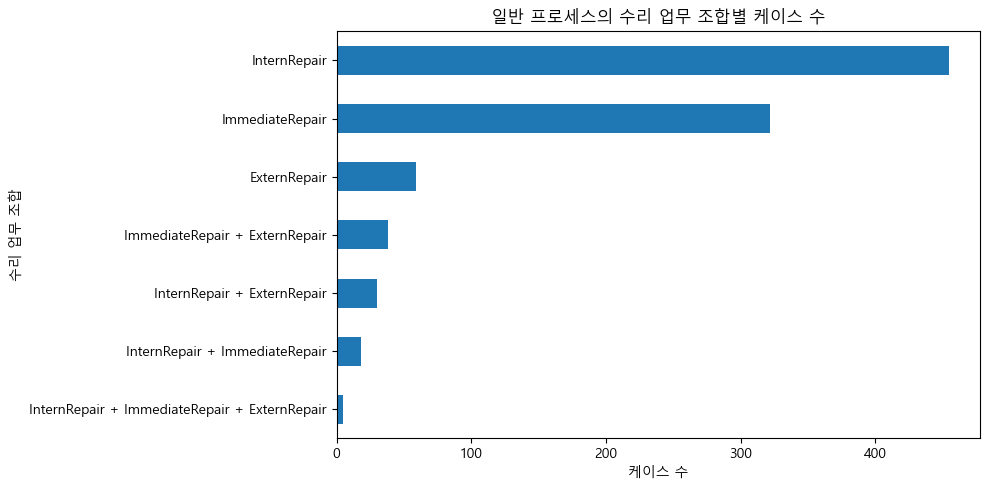

In [44]:
# 수리 업무 조합별 케이스 수 시각화
ax = combination_summary.plot.barh(
    x='수리 업무 조합',
    y='케이스 수',
    figsize=(10, 5),
    legend=False
)

ax.invert_yaxis()
ax.set_title('일반 프로세스의 수리 업무 조합별 케이스 수')
ax.set_xlabel('케이스 수')
ax.set_ylabel('수리 업무 조합')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 일반 프로세스 안에서도 수리 업무가 단독으로 나타나는 경로와 여러 수리 업무가 결합된 경로가 존재
- 수리 업무가 하나만 기록된 케이스는 836건(90.2%)이고 두 가지 이상 기록된 케이스는 91건(9.8%)
- 수리 업무가 여러 가지 존재한다는 사실과 실제로 어느 단계에서 분기한다는 것은 다르다.

##### 10-4-2. 실제 업무 순서를 바탕으로 주요 분기 지점 확인

- Survey 완료 이후 어떤 수리 업무가 시작되며 최초 수리 업무는 어떻게 구분될까?

① 첫 번째 수리 업무 확인

In [45]:
# 시간 분석 후보 중 일반 프로세스 선택
general_ids = case_paths[
    case_paths == '일반 프로세스'
].index

flow = time_cases[
    time_cases['caseID'].isin(general_ids)
].copy()

# 수리 업무의 시작 이벤트 추출
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

repair_starts = flow[
    flow['taskID'].isin(repair_tasks) &
    flow['eventtype'].eq('start')
]

# 케이스별 가장 이른 수리 시작 시각
first_time = repair_starts.groupby('caseID')['timestamp'].min().rename('첫_수리_시각')

# 최초 시각에 시작된 수리 업무 추출
first_rows = repair_starts.join(first_time, on='caseID')
first_rows = first_rows[
    first_rows['timestamp'] == first_rows['첫_수리_시각']
]

# 첫 수리 업무별 케이스 수
first_repair = first_rows.groupby('caseID')['taskID'].agg(
    lambda x: ' + '.join(sorted(x.unique()))
)

first_summary = first_repair.value_counts().to_frame('케이스 수')
first_summary['비율(%)'] = (
    first_summary['케이스 수'] / len(first_repair) * 100
).round(1)

display(first_summary)

,케이스 수,비율(%)
taskID,,
InternRepair,183,54.0
ImmediateRepair,132,38.9
ExternRepair,24,7.1


② Survey 완료와 첫 수리 시작 시점 비교

In [46]:
# 케이스별 Survey 완료 시각
survey_end = (
    flow[
        (flow['taskID'] == 'Survey') &
        (flow['eventtype'] == 'complete')
    ]
    .groupby('caseID')['timestamp']
    .min()
    .rename('Survey 완료')
)

# Survey 완료와 첫 수리 시작 시각 비교
time_check = pd.concat([survey_end, first_time], axis=1)

time_check['차이(분)'] = (
    time_check['첫_수리_시각'] - time_check['Survey 완료']
).dt.total_seconds() / 60

# 시각 관계 분류
time_check['시간 관계'] = '시각 확인 불가'
time_check.loc[time_check['차이(분)'] == 0, '시간 관계'] = '즉시 시작'
time_check.loc[time_check['차이(분)'] > 0, '시간 관계'] = ' 완료 후 수리 시작'
time_check.loc[time_check['차이(분)'] < 0, '시간 관계'] = '수리 시작이 더 빠름'

display(time_check['시간 관계'].value_counts().to_frame('케이스 수'))

,케이스 수
시간 관계,
즉시 시작,190
완료 후 수리 시작,148
시각 확인 불가,1


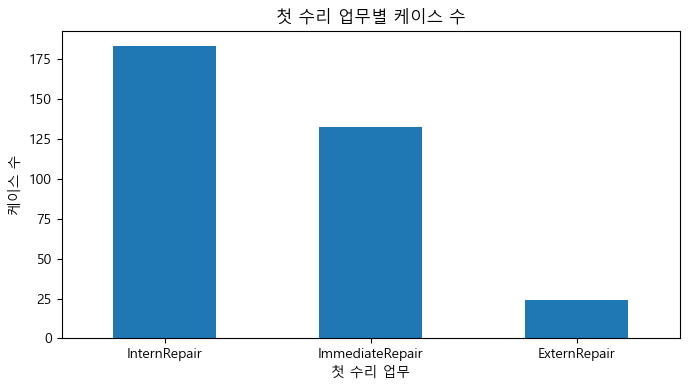

In [47]:
# 첫 수리 업무별 케이스 수
ax = first_summary['케이스 수'].plot.bar(
    figsize=(7, 4),
    rot=0
)

ax.set_title('첫 수리 업무별 케이스 수')
ax.set_xlabel('첫 수리 업무')
ax.set_ylabel('케이스 수')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 날짜 기준을 충족한 일반 프로세스 339개 케이스에서 최초 수리 업무는 InternRepair 183건(54.0%), ImmediateRepair 132건(38.9%), ExternRepair 24건(7.1%)으로 구분
- Survey 완료와 첫 수리 시작 시각을 비교한 결과 190건은 동일 시각이었으며 148건은 Survey 완료 이후 수리가 시작

-> 이러한 결과는 Survey 이후 수리 업무가 분기되는 프로세스 구조를 뒷받침

##### 10-4-3. 수리 업무 전환 패턴 분석
- 복합 수리 케이스에서는 첫 수리 이후 어떤 업무로 전환되며 업무 간 연결 관계는 일관적인가?

In [48]:
# 수리 업무 시작 이벤트 추출
start_events = flow.loc[
    flow['taskID'].isin(repair_tasks) &
    flow['eventtype'].eq('start'),
    ['caseID', 'taskID', 'timestamp']
]

# 케이스별 각 수리 업무의 최초 시작 시각
first_starts = (
    start_events.groupby(['caseID', 'taskID'], as_index=False)['timestamp']
    .min()
)

# 두 종류 이상의 수리 업무가 기록된 케이스
multi = first_starts.groupby('caseID').filter(
    lambda x: x['taskID'].nunique() >= 2
).copy()

# 동일 시각에 서로 다른 수리 업무가 시작된 케이스 확인
tie_count = (
    multi.groupby(['caseID', 'timestamp'])['taskID']
    .nunique().gt(1).sum()
)

# 첫 시작 시각을 기준으로 수리 업무 순서 정리
multi = multi.sort_values(['caseID', 'timestamp'], kind='stable')

sequences = multi.groupby('caseID')['taskID'].agg(' → '.join)

print('복합 수리 케이스:', len(sequences))
print('동일 시각으로 순서가 불명확한 경우:', tie_count)

display(sequences.value_counts().to_frame('케이스 수'))

복합 수리 케이스: 30
동일 시각으로 순서가 불명확한 경우: 0


,케이스 수
taskID,
ImmediateRepair → ExternRepair,12
InternRepair → ExternRepair,11
ImmediateRepair → InternRepair,5
ImmediateRepair → InternRepair → ExternRepair,2


- ExternRepair가 포함된 복합 경로에서는 항상 다른 수리 업무가 먼저 시작된 것으로 확인
- ImmediateRepair 이후 InternRepair로 전환된 경로도 존재
- InternRepair → ImmediateRepair처럼 반대 순서로 진행된 경로는 이번 30개 케이스에서 관찰되지 않음

① 업무 전환 시점의 정합성 확인

In [49]:
# 케이스별 다음 수리 업무 확인
transitions = multi.copy()

transitions['다음_업무'] = transitions.groupby('caseID')['taskID'].shift(-1)
transitions['다음_시작'] = transitions.groupby('caseID')['timestamp'].shift(-1)

transitions = transitions.dropna(subset=['다음_업무']).copy()

# 현재 수리 업무의 첫 완료 시각 연결
completion = (
    flow[
        flow['taskID'].isin(repair_tasks) &
        flow['eventtype'].eq('complete')
    ]
    .groupby(['caseID', 'taskID'])['timestamp']
    .min()
    .rename('현재_완료')
)

transitions = transitions.join(completion, on=['caseID', 'taskID'])

# 현재 업무 완료부터 다음 업무 시작까지의 간격
transitions['간격_분'] = (
    transitions['다음_시작'] - transitions['현재_완료']
).dt.total_seconds() / 60

# 업무 전환별 시간 관계 확인
transition_summary = transitions.groupby(
    ['taskID', '다음_업무']
)['간격_분'].agg(
    전이_건수='size',
    중앙값='median',
    최솟값='min',
    최댓값='max'
)

display(transition_summary)

전이_건수  중앙값  최솟값   최댓값
taskID          다음_업무                              
ImmediateRepair ExternRepair     12  0.0  0.0   0.0
                InternRepair      7  4.0  0.0  79.0
InternRepair    ExternRepair     13  0.0  0.0   0.0

**분석 결과 기록**

- 시간 분석 후보인 일반 프로세스 339건 중 30건(8.8%)에서 서로 다른 수리 업무가 2종류 이상 기록됨
- 주요 업무 전환은 ImmediateRepair → ExternRepair 12건, InternRepair → ExternRepair 13건, ImmediateRepair → InternRepair 7건으로 확인
- ExternRepair로 전환되는 두 유형 모두 이전 업무 완료부터 외부 수리 시작까지의 시간 간격이 0분으로 나타남
- 전체 업무 전환 32건 중 28건에서 이전 업무의 완료와 다음 업무의 시작 시각이 동일하게 기록되었으며 시간 역전은 확인되지 않았음

> **주의사항**
- 외부 수리로의 시간 간격이 0분이 전체를 대변하지는 않음
- 외부 수리로의 전환이 정상적인 처리 절차인지 기존 수리의 실패로 인한 재작업인지는 확인되지 않음

#### 10-5. 프로세스 맵 작성
전체 수리 요청은 일반 프로세스와 예외 처리 경로로 어떻게 나뉘며 일반 프로세스에는 어떤 수리 업무 조합이 존재하는가?

##### 10-5-1. 전체 수리 요청의 경로 구조 시각화

In [50]:
import plotly.graph_objects as go

# 일반 프로세스의 수리 업무 조합
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

general = case_tasks.loc[case_paths == '일반 프로세스']

combinations = general[repair_tasks].apply(
    lambda row: ' + '.join(row.index[row]), axis=1
).value_counts()

# 단일 수리와 복합 수리 구분
single = [p for p in combinations.index if ' + ' not in p]
multi = [p for p in combinations.index if ' + ' in p]

single_n = combinations[single].sum()
multi_n = combinations[multi].sum()
exception_n = (case_paths == '예외 처리 경로').sum()

# 프로세스 노드
labels = [
    f'전체 요청<br>{len(case_paths)}건',
    f'일반 프로세스<br>{len(general)}건',
    f'예외 처리<br>{exception_n}건',
    f'단일 수리<br>{single_n}건',
    f'복합 수리<br>{multi_n}건'
] + single + multi

# 노드 간 연결 및 케이스 수
sources = [0, 0, 1, 1]
targets = [1, 2, 3, 4]
values = [len(general), exception_n, single_n, multi_n]

for i, pattern in enumerate(single):
    sources.append(3)
    targets.append(5 + i)
    values.append(int(combinations[pattern]))

for i, pattern in enumerate(multi):
    sources.append(4)
    targets.append(5 + len(single) + i)
    values.append(int(combinations[pattern]))

# Sankey Diagram
fig = go.Figure(go.Sankey(
    node=dict(
        label=labels,
        pad=22,
        thickness=18,
        color=['#64748B', '#2563EB', '#F59E0B',
               '#60A5FA', '#8B5CF6']
              + ['#93C5FD'] * len(single)
              + ['#C4B5FD'] * len(multi)
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color='rgba(100,116,139,0.2)'
    )
))

fig.update_layout(
    title='수리 요청의 프로세스 유형 및 업무 조합',
    font_size=12,
    height=650,
    width=1100,
    paper_bgcolor='white',
    margin=dict(l=20, r=30, t=70, b=20)
)

fig.show()

##### 10-5-2. 실제 수리 업무의 진행 순서 시각화

In [51]:
from collections import Counter

# 10-4-3에서 확인한 수리 업무 순서
routes = sequences.str.split(' → ')

# 각 단계의 업무 전환 건수 집계
edges = Counter()

for route in routes:
    previous = '수리 업무 시작'

    for i, task in enumerate(route, 1):
        current = f'{i}차 {task}'
        edges[(previous, current)] += 1
        previous = current

    edges[(previous, '마지막 수리 업무')] += 1

# Sankey용 데이터 구성
nodes = list(dict.fromkeys(
    name for edge in edges for name in edge
))
node_index = {name: i for i, name in enumerate(nodes)}

fig = go.Figure(go.Sankey(
    node=dict(
        label=nodes,
        pad=25,
        thickness=20,
        color='#3B82F6'
    ),
    link=dict(
        source=[node_index[a] for a, b in edges],
        target=[node_index[b] for a, b in edges],
        value=list(edges.values()),
        color='rgba(59,130,246,0.25)'
    )
))

fig.update_layout(
    title=f'수리 업무의 시간순 진행 경로 ({len(routes)}개 케이스)',
    font_size=12,
    width=1100,
    height=550,
    paper_bgcolor='white'
)

fig.show()

**분석 결과 기록**

1. 수리 요청의 주요 처리 경로 확인
- 전체 1,000개 케이스는 일반 프로세스 927건(92.7%)과 예외 처리 경로 73건(7.3%)으로 구분됨.
- 일반 프로세스에서는 티켓 생성, 조사, 수리, 처리 완료와 관련된 공통 업무가 확인됨.
- 예외 처리 경로는 FirstContact와 InformClientWrongPlace로 구성되며 두 업무의 논리적 순서를 접수 후 별도 안내로 해석함.
2. 일반 프로세스의 수리 업무 분기 확인
- 일반 프로세스 927건 중 단일 수리 업무가 기록된 케이스는 836건(90.2%), 복합 수리 업무가 기록된 케이스는 91건(9.8%)임.
- 시간 분석 후보 339건에서 첫 수리 업무는 InternRepair 183건(54.0%), ImmediateRepair 132건(38.9%), ExternRepair 24건(7.1%)으로 구분됨.
- 339건 중 338건에서 Survey 완료 시각과 첫 수리 시작 시각이 같거나 수리가 이후에 시작되는 것으로 확인됨.
3. 내부 수리 업무의 반복 기록 확인
- InternRepair가 반복 기록된 케이스는 38건이며 이 중 36건이 InternRepair만 포함된 수리 업무 조합에서 발생함.
- 반복 케이스 중 수리 업무의 모든 기록이 1970년인 29건을 확인한 결과 28건에서 완료 후 다시 시작하는 형태가 관찰됨.
- 반복 기록은 특정 업무 조합에 집중되어 있으나 정상적인 복수 수행인지 재작업인지는 확인되지 않음.
4. 복합 수리 업무의 전환 패턴 확인
- 시간 분석 후보 339건 중 30건에서 서로 다른 수리 업무가 2종류 이상 기록됨.
- 주요 전환은 ImmediateRepair → ExternRepair 12건, InternRepair → ExternRepair 13건, ImmediateRepair → InternRepair 7건으로 확인됨.
- 전체 업무 전환 32건 중 28건에서 이전 업무 완료와 다음 업무 시작이 동일 시각으로 기록됨.
- 외부 수리로 전환되는 두 유형 모두 전환 간격의 중앙값이 0분으로 나타남.

----

## 11. 단계별 도달률 및 중단 후보 분석
어느 단계에서 다음 업무로 진행하지 않는지 즉 이탈하는 확인
- 주요 경로별 퍼널 및 단계별 도달률 확인

> **주의:** 단계별 도달률 감소가 곧 고객 이탈을 의미하지 않는다. 정상적인 업무 분기나 종료를 먼저 구분한다. 비율의 분모와 관측 범위를 함께 기록한다.


#### 11-1. 퍼널 분석 기준 정의
수리 요청의 주요 업무가 일정한 순서로 진행되는가? 이 데이터를 이용해 단계별 도달률과 중단 지점을 분석할 수 있을까?

- 주요 업무의 시간순 진행 관계가 검증되었는지 확인
- 단계별 진입 대상과 분모 설정
- 정상적인 업무 분기와 진행 중단의 구분 기준 정의
- 퍼널 분석이 가능한 범위와 한계 판단

In [52]:
# 퍼널 단계별 이벤트 유형 정의
funnel_steps = {
    'FirstContact': 'complete',
    'MakeTicket': 'start',
    'ArrangeSurvey': 'start',
    'Survey': 'complete',
    'RepairReady': 'complete',
    'TicketReady': 'complete'
}

# 시간 분석 후보 중 일반 프로세스 추출
general_ids = case_paths[case_paths == '일반 프로세스'].index
target_ids = general_ids.intersection(time_case_ids)

events = time_cases[time_cases['caseID'].isin(target_ids)].copy()

# 단계별 지정한 이벤트만 추출
events = events[
    events['taskID'].map(funnel_steps).eq(events['eventtype'])
]

# 케이스별 단계의 첫 기록 시각
stage_times = events.pivot_table(
    index='caseID',
    columns='taskID',
    values='timestamp',
    aggfunc='min'
).reindex(index=target_ids, columns=list(funnel_steps))

# 연속된 단계 사이의 시간 관계 검증
results = []

for before, after in zip(list(funnel_steps)[:-1], list(funnel_steps)[1:]):
    pair = stage_times[[before, after]].dropna()

    results.append({
        '업무 흐름': f'{before} → {after}',
        '비교 가능': len(pair),
        '이전 단계가 먼저 발생했는가': (pair[before] < pair[after]).sum(),
        '동시 발생': (pair[before] == pair[after]).sum(),
        '순서 역전': (pair[before] > pair[after]).sum()
    })

display(pd.DataFrame(results))

,업무 흐름,비교 가능,이전 단계가 먼저 발생했는가,동시 발생,순서 역전
0,FirstContact → MakeTicket,339,0,339,0
1,MakeTicket → ArrangeSurvey,339,339,0,0
2,ArrangeSurvey → Survey,338,338,0,0
3,Survey → RepairReady,338,338,0,0
4,RepairReady → TicketReady,339,339,0,0


**분석 결과 기록**

- 일반 프로세스의 공통 업무와 수리 분기 구조를 고려하여 7개 퍼널 단계 후보를 정의
- ImmediateRepair, InternRepair, ExternRepair는 케이스에 따라 단독 또는 복합적으로 기록되므로 세 업무 중 하나라도 시작되면 '수리 단계 진입'으로 정의
- RepairReady는 수리 이후 공통 처리 단계의 도달 여부를 확인하는 지표로 설정

#### 11-2. 주요 업무별 기록률 및 누락 분석
일반 프로세스에서 특정 단계의 기록이 없는 케이스가 존재한다. 그렇다면 이것을 실제 진행 중단으로 볼 수 있을까?

- 일반 프로세스 927건의 주요 업무별 기록률 확인
- 특정 업무가 기록되지 않은 케이스 확인
- 단계별 기록률 감소가 실제 중단을 의미하는지 검토

In [53]:
# 단계별 업무와 이벤트 유형 정의
step_rules = {
    'FirstContact': 'complete',
    'MakeTicket': 'start',
    'ArrangeSurvey': 'start',
    'Survey': 'complete',
    'RepairReady': 'complete',
    'TicketReady': 'complete'
}

# 케이스별 단계 기록 여부
stage_presence = pd.DataFrame(index=case_tasks.index)

for task, event in step_rules.items():
    ids = df.loc[
        df['taskID'].eq(task) & df['eventtype'].eq(event),
        'caseID'
    ].unique()

    stage_presence[task] = stage_presence.index.isin(ids)

# 수리 업무 중 하나라도 시작했는지 확인
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

repair_ids = df.loc[
    df['taskID'].isin(repair_tasks) & df['eventtype'].eq('start'),
    'caseID'
].unique()

stage_presence.insert(
    4, '수리 단계 진입',
    stage_presence.index.isin(repair_ids)
)

# 일반 프로세스의 단계별 기록률
general_ids = case_paths.index[
    case_paths == '일반 프로세스'
]

summary = stage_presence.loc[general_ids].sum().to_frame('기록 케이스')
summary['미기록 케이스'] = len(general_ids) - summary['기록 케이스']
summary['기록률(%)'] = (
    summary['기록 케이스'] / len(general_ids) * 100
).round(1)

display(summary)

,기록 케이스,미기록 케이스,기록률(%)
FirstContact,926,1,99.9
MakeTicket,927,0,100.0
ArrangeSurvey,926,1,99.9
Survey,926,1,99.9
수리 단계 진입,926,1,99.9
RepairReady,927,0,100.0
TicketReady,926,1,99.9


> 기록 누락 케이스의 원인 확인

In [54]:
# 단계별 미기록 케이스 추출
missing_cases = pd.DataFrame(
    [
        (stage, case_id)
        for stage in stage_presence.columns
        for case_id in general_ids[
            ~stage_presence.loc[general_ids, stage]
        ]
    ],
    columns=['기록 누락 단계', 'caseID']
)

display(missing_cases)

# 해당 케이스의 taskID 또는 eventtype 결측 기록 확인
missing_events = df.loc[
    df['caseID'].isin(missing_cases['caseID']) &
    (df['taskID'].isna() | df['eventtype'].isna()),
    ['caseID', 'taskID', 'eventtype']
]

display(missing_events)

,기록 누락 단계,caseID
0,FirstContact,245
1,ArrangeSurvey,14
2,Survey,229
3,수리 단계 진입,128
4,TicketReady,132


,caseID,taskID,eventtype
6953,14,ArrangeSurvey,NaN
7124,245,NaN,complete
8217,229,Survey,NaN
9843,128,ImmediateRepair,NaN
13159,132,TicketReady,NaN


**분석 결과 기록**

- 일반 프로세스 927건을 대상으로 7개 단계의 기록 여부를 확인한 결과 모든 단계에서 99.9~100%의 기록률 확인
- FirstContact, ArrangeSurvey, Survey, 수리 단계 진입, TicketReady에서 각각 1건의 미기록 사례가 확인됨
- 미기록 사례가 발생한 5개 케이스에서 taskID 또는 eventtype 결측이 확인되었음

> 주요 단계의 미기록 사례를 조사한 결과 업무명 또는 이벤트 유형의 결측이 확인되었다. 일부 케이스에서는 후속 업무도 기록되어 있어 단계별 미기록을 실제 이탈로 판단하기 어렵다. 따라서 해당 사례는 이탈이 아닌 기록 불완전 사례로 구분하고 실제 중단 여부는 미확정으로 처리한다.

#### 11-3. 예외 처리 경로 및 중단 후보 검증
전체 수리 요청 중 일반적인 종료 업무와 예외 안내 업무가 모두 기록되지 않은 케이스가 존재할까?

- 일반 프로세스와 예외 처리 경로 구분
- 종료 후보 업무가 기록되지 않은 케이스 확인
- 정상 종료와 기록 누락 및 실제 중단 가능성 구분

In [55]:
# 케이스별 종료 후보 업무 기록 여부
end_tasks = case_tasks[
    ['TicketReady', 'InformClientWrongPlace']
]

# 종료 후보 업무 조합별 케이스 수
end_summary = pd.Series({
    '일반 종료 후보만 기록': (
        end_tasks['TicketReady'] &
        ~end_tasks['InformClientWrongPlace']
    ).sum(),

    '예외 안내 후보만 기록': (
        ~end_tasks['TicketReady'] &
        end_tasks['InformClientWrongPlace']
    ).sum(),

    '두 업무 모두 기록': end_tasks.all(axis=1).sum(),
    '두 업무 모두 미기록': (~end_tasks.any(axis=1)).sum()
}, name='케이스 수')

display(end_summary.to_frame())

# 종료 후보 업무의 이벤트 유형 확인
end_events = df[df['taskID'].isin(end_tasks.columns)]

display(pd.crosstab(
    end_events['taskID'],
    end_events['eventtype'],
    dropna=False
))

,케이스 수
일반 종료 후보만 기록,927
예외 안내 후보만 기록,73
두 업무 모두 기록,0
두 업무 모두 미기록,0


eventtype,complete,NaN
taskID,,
InformClientWrongPlace,73,0
TicketReady,926,1


**분석 결과 기록**

- 두 업무 경로의 종료 업무가 동시에 기록되거나 누락된 케이스는 확인되지 않음
- TicketReady는 926건에서 complete가 기록되었으며 1건은 eventtype이 결측으로 확인


#### 11-4. 퍼널 분석 결과 및 한계 정리

**주요 분석 결과**
- 일반 프로세스의 공통 업무와 수리 분기를 고려하여 7개 퍼널 단계 후보를 정의
- 시간 분석 후보 339건에서 기존 6개 공통 업무 단계의 기록 시각을 비교한 결과 순서 역전은 확인되지 않음
- 일반 프로세스 927건의 주요 단계별 기록률은 99.9~100%로 나타났으며 일부 미기록 사례에서는 업무명 또는 이벤트 유형의 결측이 확인됨
- 전체 1,000개 케이스에서 `TicketReady` 또는 `InformClientWrongPlace`가 기록되었으며 두 종료 후보 업무가 모두 누락된 사례는 없었음

**분석 결과에 따른 판단**
- 단계별 기록률 감소를 실제 이탈로 판단할 근거는 부족하기 때문에 이탈로 판단하지 않음
- 일반 프로세스는 `TicketReady` 기록 여부로 정의되어 최종 단계 도달률이 분류 기준의 영향을 받음
- 따라서 현재 데이터에서는 퍼널을 통한 실제 이탈률 산출보다 업무별 기록 누락 여부를 확인하는 수준으로 분석 범위를 제한하는 것이 적절함

**한계**
- 날짜 오류로 인해 전체 케이스의 시간순 업무 진행을 검증하기 어려움
- 업무 기록 여부만으로 실제 단계별 전환율과 중단 원인을 확인할 수 없음
- 모든 종료 후보 업무가 기록되어 있다는 사실이 실제 정상 완료를 보장하지는 않음

**결론**
- 현재 데이터에서는 실제 이탈 구간을 신뢰성 있게 특정하기 어려워 퍼널 분석을 추가로 진행하지 않음
- 이후에는 반복 수리와 복합 수리의 처리 시간 및 업무 간 대기 시간을 분석하여 병목 발생 가능성을 확인함

----

## 12. 소요 시간 및 병목 분석

**분석 목적:** 업무 수행 시간과 업무 사이 대기 시간을 구분해 지연이 발생하는 구간을 확인한다.

**앞 단계와의 연결·다음 작업:** 10단계에서 연결한 업무와 11단계에서 구분한 경로를 바탕으로 시간을 계산한다. 지연 구간을 찾은 뒤 담당 업무 배분과 요청 특성이 관련되는지 살펴본다.

**산출물:** 처리 시간 분포 그래프 및 주요 병목 구간

> **주의:** 최초~최종 기록 간격이 실제 접수~수리 완료 시간과 같은지 확인한다. 병렬 업무의 겹침이나 음수 간격을 대기 시간으로 단정하지 않는다. 표본 수와 중앙값을 함께 제시한다.


#### 12-1. 업무별 처리 시간 계산 및 분포 비교

##### 12-1-1. 업무별 처리 시간 비교
어떤 업무의 처리 시간이 길며 특정 업무에서 유독 긴 시간이 발생하는가?
- 9-5에서 선정한 시간 분석 1차 후보 3,151건을 사용

In [56]:
# 업무별 처리 시간 계산 (분)
time_pairs['duration_min'] = (
    time_pairs['complete'] - time_pairs['start']
).dt.total_seconds() / 60

# 업무별 처리 시간 요약
duration_summary = (
    time_pairs.groupby('taskID')['duration_min']
    .agg(
        건수='count',
        중앙값='median',
        평균='mean',
        최솟값='min',
        최댓값='max'
    )
)

# 상위 10%에 해당하는 시간 기준
duration_summary['90백분위'] = (
    time_pairs.groupby('taskID')['duration_min'].quantile(0.9)
)

duration_summary = duration_summary.sort_values(
    '중앙값', ascending=False
).round(1)

display(duration_summary)

,건수,중앙값,평균,최솟값,최댓값,90백분위
taskID,,,,,,
InternRepair,403,240.0,224.3,108.0,288.0,264.0
ImmediateRepair,334,120.0,117.0,42.0,132.0,132.0
Survey,808,41.0,40.3,15.0,60.0,57.0
ArrangeSurvey,809,4.0,118.7,2.0,2189.0,404.8
MakeTicket,797,4.0,4.4,2.0,10.0,7.0


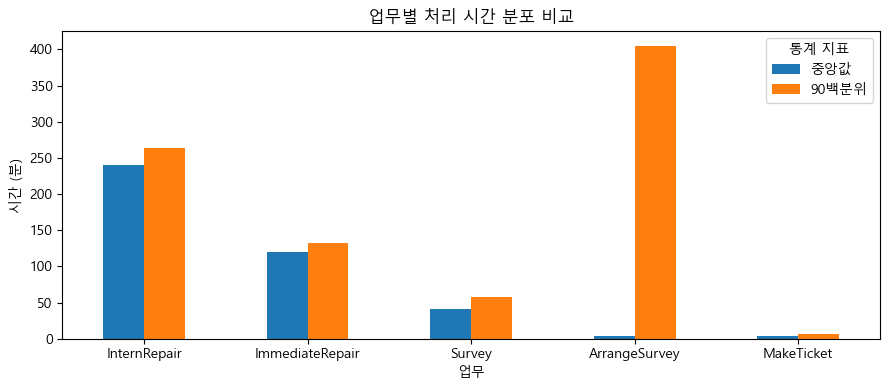

In [57]:
# 업무별 처리 시간 중앙값과 90백분위 비교
ax = duration_summary[['중앙값', '90백분위']].plot.bar(
    figsize=(9, 4),
    rot=0
)

ax.set_title('업무별 처리 시간 분포 비교')
ax.set_xlabel('업무')
ax.set_ylabel('시간 (분)')
ax.legend(title='통계 지표')

plt.tight_layout()
plt.show()

> - ArrangeSurvey에서 긴 처리 시간이 발생하는 현상이 극단적인 이상치 몇 건 때문인지, 일정한 비중의 케이스에서 반복되는 현상인지 확인할 필요가 있음
> - 90백분위가 400분을 초과하는 것을 확인하였으나 이것만으로 해당 업무에서 병목이 발생한다고 단정할 수 없다.

##### 12-1-2. ArrangeSurvey 처리 시간 구간별 분포
긴 처리 시간이 소수의 이상치 때문인지 일정한 비중에서 반복되는 현상인지 확인

In [58]:
# ArrangeSurvey 처리 시간 추출
arrange = time_pairs.loc[
    time_pairs['taskID'] == 'ArrangeSurvey',
    'duration_min'
]

# 처리 시간 구간 설정
bins = [-1, 10, 60, 240, 480, 1440, float('inf')]
labels = [
    '10분 이하', '10~60분', '1~4시간',
    '4~8시간', '8~24시간', '24시간 초과'
]

groups = pd.cut(arrange, bins=bins, labels=labels)

# 구간별 건수 및 비율
time_distribution = groups.value_counts(sort=False).to_frame('건수')
time_distribution['비율(%)'] = (
    time_distribution['건수'] / len(arrange) * 100
).round(1)

display(time_distribution)

,건수,비율(%)
duration_min,,
10분 이하,615,76.0
10~60분,0,0.0
1~4시간,52,6.4
4~8시간,69,8.5
8~24시간,67,8.3
24시간 초과,6,0.7


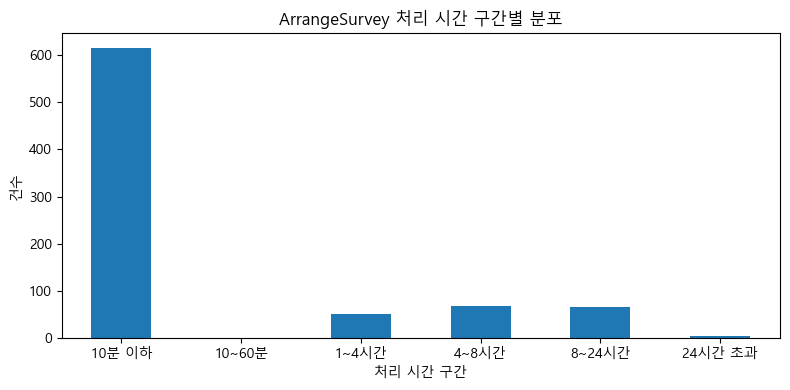

In [59]:
ax = time_distribution['건수'].plot.bar(
    figsize=(8, 4), rot=0
)

ax.set_title('ArrangeSurvey 처리 시간 구간별 분포')
ax.set_xlabel('처리 시간 구간')
ax.set_ylabel('건수')

plt.tight_layout()
plt.show()

> - 1시간 초과 기록이 194건으로 나타나 극단적인 이상치 몇 건만의 문제는 아닌 것으로 확인
> - 다만 24시간을 초과하는 6건도 존재하므로 해당 기록의 시간 정합성과 특징을 별도로 확인할 필요가 있음


##### 12-1-3. 24시간 초과 사례 확인
처리 시간이 지나치게 긴 사례는 어떻게 기록되어 있으며 데이터 오류를 의심할 만한 특징이 있는가?

In [60]:
# ArrangeSurvey에서 24시간을 초과한 기록
long_arrange = time_pairs[
    (time_pairs['taskID'] == 'ArrangeSurvey') &
    (time_pairs['duration_min'] > 1440)
].sort_values('duration_min', ascending=False)

display(long_arrange[
    ['caseID', 'start', 'complete', 'duration_min']
])

eventtype,caseID,start,complete,duration_min
84,26,1970-01-01 14:38:00,1970-01-03 03:07:00,2189.0
803,224,1970-01-04 16:45:00,1970-01-06 03:17:00,2072.0
1008,277,1970-01-07 03:34:00,1970-01-08 12:10:00,1956.0
1131,311,1970-01-04 09:03:00,1970-01-05 13:58:00,1735.0
2405,656,1970-01-06 09:48:00,1970-01-07 11:46:00,1558.0
2480,677,1970-01-07 22:47:00,1970-01-09 00:30:00,1543.0


##### 12-1-4. 접수 채널별 처리 시간 비교
ArrangeSurvey의 접수 채널에 따라 차이가 있는가?

In [61]:
# ArrangeSurvey 기록에 케이스별 접수 채널 연결
arrange_df = time_pairs[
    time_pairs['taskID'] == 'ArrangeSurvey'
].copy()

case_contact = df.groupby('caseID')['contact'].first()
arrange_df['contact'] = arrange_df['caseID'].map(case_contact)

# 접수 채널별 1시간 초과 여부
channel_summary = pd.crosstab(
    arrange_df['contact'],
    arrange_df['duration_min'] > 60
).rename(columns={
    False: '1시간 이하',
    True: '1시간 초과'
})

# 채널별 초과율 계산
channel_summary['1시간 초과율(%)'] = (
    channel_summary['1시간 초과'] /
    channel_summary[['1시간 이하', '1시간 초과']].sum(axis=1) * 100
).round(1)

display(channel_summary)

duration_min,1시간 이하,1시간 초과,1시간 초과율(%)
contact,,,
Letter,90,85,48.6
Personal,203,0,0.0
Phone,224,0,0.0
Web,98,109,52.7


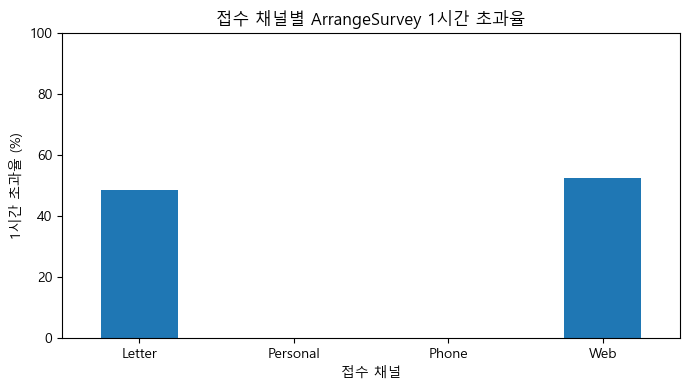

In [62]:
ax = channel_summary['1시간 초과율(%)'].plot.bar(
    figsize=(7, 4), rot=0
)

ax.set_title('접수 채널별 ArrangeSurvey 1시간 초과율')
ax.set_xlabel('접수 채널')
ax.set_ylabel('1시간 초과율 (%)')
ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()

> - 1시간을 초과한 194건 모두 Web 또는 Letter 를 통해 접수된 케이스에서 확인됨
> - 접수 채널에 따라 다른 업무 처리 방식이나 기록 구조와 관련되어 있을 가능성이 있음

##### 12-1-5. 분석 결과 종합 및 다음 분석 방향
**① 업무별 처리 시간 비교**
- 업무별 중앙값과 P90을 비교한 결과 `ArrangeSurvey`의 중앙값은 4분이지만 P90(90백분위)은 404.8분으로 큰 차이가 확인됨
- 이러한 차이가 극단적인 이상치 때문인지 확인하기 위해 처리 시간 구간별 분포를 추가 분석

**② ArrangeSurvey 처리 시간 분포 확인**
- 전체 809건 중 615건(76.0%)은 10분 이하였으며 194건(24.0%)은 1시간을 초과
- 10~60분 구간에는 기록이 없었으며 짧은 처리 시간과 긴 처리 시간으로 구분되는 패턴이 나타남
- 24시간 초과 기록은 6건에 불과해 긴 처리 시간의 발생을 소수의 극단적인 사례만으로 설명하기 어렵다고 판단

**③ 접수 채널별 처리 시간 비교**
- 1시간을 초과한 194건은 모두 Web 또는 Letter 접수 케이스에서 발생
- Web의 1시간 초과율은 52.7%, Letter는 48.6%였으며 Phone과 Personal에서는 초과 사례가 확인되지 않음
- 접수 채널에 따라 처리 시간이 달라지는 패턴이 확인되어 채널별 업무 방식이나 요청 특성과의 관계를 추가 검증할 필요가 있음

> **중요**
- `ArrangeSurvey`는 처리 시간이 짧은 집단과 수 시간 이상 소요되는 집단으로 구분되는 특징을 보임
- 긴 처리 시간은 Web과 Letter 접수 케이스에 집중되어 있어 접수 채널이 주요 관련 요인 후보로 확인됨

> **한계**
- 분석 대상은 날짜와 시작·완료 기록 조건을 충족한 일부 업무이므로 전체 케이스에 일반화하기 어려움
- 처리 시간은 시작부터 완료까지의 경과 시간이며 실제 작업 시간과 대기 시간을 구분할 수 없음
- 1970년 날짜의 정확성은 완전히 검증되지 않았으며 접수 채널과 처리 시간의 관계를 인과관계로 해석할 수 없음
- 처리 시간이 길다는 사실만으로 실제 병목이 발생했다고 확정할 수 없음

#### 12-2. 케이스별 전체 처리 시간 분석


##### 12-2-1. 케이스별 전체 관찰 시간 분석
수리 요청의 최초 기록부터 마지막 기록까지 얼마나 시간이 소요되는지 확인하고 처리 시간의 분포를 파악

> 전체 처리 시간 정의: 케이스의 최초 기록 시각부터 최종 기록 시각까지의 경과 시간으로 실제 작업 시간과 업무 간 대기 시간을 포함함. 날짜 정합성이 완전히 검증되지 않았으므로 기록상 처리 시간으로 해석함.

In [63]:
# 케이스별 최초·최종 이벤트 시각
case_duration = time_cases.groupby('caseID')['timestamp'].agg(
    최초_기록='min',
    최종_기록='max'
)

# 케이스별 전체 처리 시간 계산 (단위: 시간)
case_duration['관찰_시간'] = (
    case_duration['최종_기록'] - case_duration['최초_기록']
).dt.total_seconds() / 3600

# 프로세스 유형 연결
case_duration['프로세스 유형'] = case_paths

# 일반 프로세스만 선택
general_duration = case_duration[
    case_duration['프로세스 유형'] == '일반 프로세스'
].copy()

# 관찰 시간 분포 확인
display(
    general_duration['관찰_시간']
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(1)
    .to_frame('시간')
)

,시간
count,339.0
mean,110.2
std,101.2
min,4.7
25%,22.9
50%,77.3
75%,186.4
90%,254.8
max,398.5


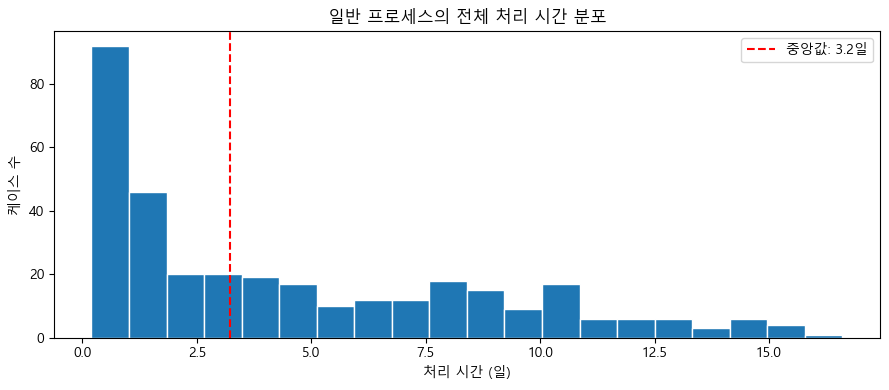

In [64]:
# 케이스별 전체 처리 시간 분포 (일 단위)
duration_days = general_duration['관찰_시간'] / 24
median_days = duration_days.median()

plt.figure(figsize=(9, 4))
plt.hist(duration_days, bins=20, edgecolor='white')

# 중앙값 표시
plt.axvline(
    median_days,
    color='red',
    linestyle='--',
    label=f'중앙값: {median_days:.1f}일'
)

plt.title('일반 프로세스의 전체 처리 시간 분포')
plt.xlabel('처리 시간 (일)')
plt.ylabel('케이스 수')
plt.legend()

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 시간 분석의 1차 후보 중 일반 프로세스 339개 케이스를 대상으로 최초 이벤트부터 최종 이벤트까지의 케이스별 전체 처리 시간을 계산
- 전체 처리 시간의 중앙값은 77.3시간(약 3.2일), 평균은 110.2시간(약 4.6일)
- 75백분위는 186.4시간(약 7.8일), 90백분위는 254.8시간(약 10.6일)
- 중앙값과 상위 백분위 사이에 큰 차이가 나타나 케이스별 관찰 시간의 편차가 존재

##### 12-2-2. ArrangeSurvey 처리 시간에 따른 전체 처리 시간 비교
ArrangeSurvey 처리 시간이 1시간을 초과한 케이스는 1시간 이하인 케이스보다 전체 처리 시간이 긴가?

In [65]:
# 전체 처리 시간 컬럼명 통일
general_duration = general_duration.rename(
    columns={'관찰_시간': '전체_처리_시간'}
)

# 조사 일정 조율 업무의 처리 시간 추출
arrange_times = time_pairs.loc[
    time_pairs['taskID'] == 'ArrangeSurvey',
    ['caseID', 'duration_min']
].rename(columns={
    'duration_min': '조사 일정 조율 시간(분)'
})

# 케이스별 전체 처리 시간과 결합
compare = general_duration[['전체_처리_시간']].join(
    arrange_times.set_index('caseID')
)

# 조사 일정 조율 시간이 확인된 케이스만 분석
compare = compare.dropna(subset=['조사 일정 조율 시간(분)'])

# 조사 일정 조율 시간에 따라 집단 구분
compare['조사 일정 조율 1시간 초과 여부'] = (
    compare['조사 일정 조율 시간(분)'] > 60
).map({
    False: '1시간 이하',
    True: '1시간 초과'
})

# 전체 처리 시간에서 조사 일정 조율 시간 제외
compare['조사 일정 조율 제외 시간(시간)'] = (
    compare['전체_처리_시간']
    - compare['조사 일정 조율 시간(분)'] / 60
)

# 집단별 전체 처리 시간 비교
comparison_summary = (
    compare.groupby('조사 일정 조율 1시간 초과 여부')
    .agg(
        케이스수=('전체_처리_시간', 'size'),
        전체_처리_시간_중앙값=('전체_처리_시간', 'median'),
        전체_처리_시간_P90=('전체_처리_시간', lambda x: x.quantile(0.9)),
        조사_일정_조율_제외_시간_중앙값=(
            '조사 일정 조율 제외 시간(시간)', 'median'
        )
    )
    .round(1)
)

display(comparison_summary)

,케이스수,전체_처리_시간_중앙값,전체_처리_시간_P90,조사_일정_조율_제외_시간_중앙값
조사 일정 조율 1시간 초과 여부,,,,
1시간 이하,264,77.2,253.1,77.2
1시간 초과,75,78.2,253.7,67.2


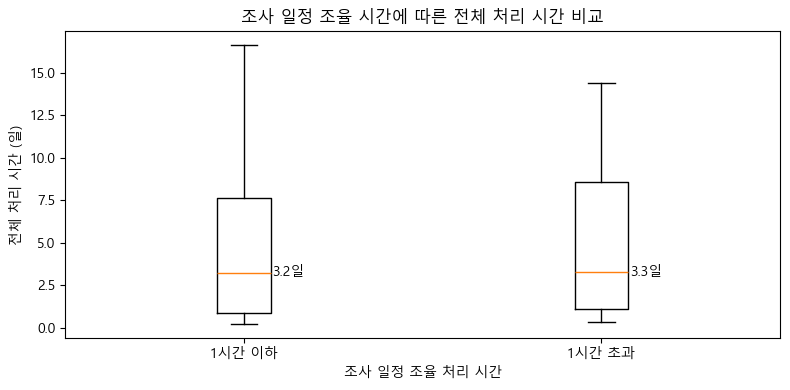

In [66]:
groups = ['1시간 이하', '1시간 초과']

plot_data = [
    compare.loc[
        compare['조사 일정 조율 1시간 초과 여부'] == group,
        '전체_처리_시간'
    ] / 24
    for group in groups
]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(plot_data, tick_labels=groups)

# 중앙값 표시
for i, values in enumerate(plot_data, start=1):
    median_value = values.median()
    ax.text(i + 0.08, median_value, f'{median_value:.1f}일', va='center')

ax.set_title('조사 일정 조율 시간에 따른 전체 처리 시간 비교')
ax.set_xlabel('조사 일정 조율 처리 시간')
ax.set_ylabel('전체 처리 시간 (일)')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 조사 일정 조율 시간이 1시간을 초과한 집단에서 전체 처리 시간이 크게 증가하는 현상은 확인되지 않음
- 따라서 조사 일정 조율 업무의 긴 처리 시간이 전체 프로세스의 주요 병목이라는 근거는 부족하다고 판단
- 전체 처리 시간에는 다른 업무의 수행 시간과 업무 간 대기 시간도 포함되므로 다른 구간에서 긴 시간이 발생하는지 추가 확인할 필요가 있음


#### 12-3. 업무 간 대기 시간 분석
조사 일정 조율 시간이 1시간을 초과하는 케이스라고 해서 전체 처리 시간도 크게 길어지는 것은 아니라는 결과를 확인함

> 업무 자체에 걸리는 시간보다 업무가 끝난 후 다음 업무가 시작되기까지 얼마나 기다리는지 확인 필요

##### 12-3-1. 업무 간 대기 시간 비교
전체 수리 프로세스에서 어떤 업무 사이의 대기 시간이 가장 긴가?
> 업무 간 대기 시간= 다음 업무 시작 시각 - 이전 업무 완료 시각

In [67]:
# 12-2에서 확정한 시간 분석 대상 339개 일반 프로세스 케이스를 사용
# 이전 셀의 임시 변수에 의존하지 않도록 필요한 이벤트 시각을 여기에서 정의
target_ids = general_duration.index
selected = df[df['caseID'].isin(target_ids)].copy()

def event_time(task, eventtype):
    return (
        selected.loc[
            (selected['taskID'] == task) &
            (selected['eventtype'] == eventtype)
        ]
        .groupby('caseID')['timestamp']
        .min()
    )

first_contact_end = event_time('FirstContact', 'complete')
make_ticket_start = event_time('MakeTicket', 'start')
make_ticket_end = event_time('MakeTicket', 'complete')
arrange_start = event_time('ArrangeSurvey', 'start')
arrange_end = event_time('ArrangeSurvey', 'complete')
survey_start = event_time('Survey', 'start')
survey_end = event_time('Survey', 'complete')

repair_start = (
    selected.loc[
        selected['taskID'].isin([
            'InternRepair', 'ImmediateRepair', 'ExternRepair'
        ]) &
        selected['eventtype'].eq('start')
    ]
    .groupby('caseID')['timestamp']
    .min()
)

# 업무 간 대기 시간 계산 (시간)
wait_times = pd.DataFrame(index=target_ids)

wait_times['FirstContact → MakeTicket'] = (
    make_ticket_start - first_contact_end
).dt.total_seconds() / 3600

wait_times['MakeTicket → ArrangeSurvey'] = (
    arrange_start - make_ticket_end
).dt.total_seconds() / 3600

wait_times['ArrangeSurvey → Survey'] = (
    survey_start - arrange_end
).dt.total_seconds() / 3600

wait_times['Survey → Repair start'] = (
    repair_start - survey_end
).dt.total_seconds() / 3600

# 음수 시간 여부 확인
print('음수 대기 시간:', (wait_times < 0).sum().sum())

# 업무 간 대기 시간 요약
wait_summary = pd.DataFrame({
    '분석 건수': wait_times.count(),
    '중앙값(시간)': wait_times.median(),
    'P90(시간)': wait_times.quantile(0.9),
    '대기 발생 건수': (wait_times > 0).sum()
}).round(1)

display(wait_summary)


음수 대기 시간: 0


,분석 건수,중앙값(시간),P90(시간),대기 발생 건수
FirstContact → MakeTicket,339,0.0,0.0,0
MakeTicket → ArrangeSurvey,339,0.0,0.0,0
ArrangeSurvey → Survey,339,54.5,195.7,300
Survey → Repair start,338,0.0,64.6,148


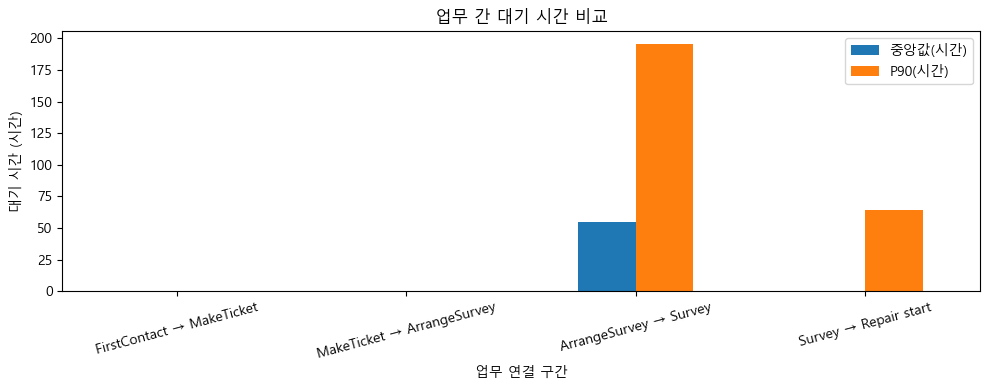

In [68]:
ax = wait_summary[['중앙값(시간)', 'P90(시간)']].plot.bar(
    figsize=(10, 4),
    rot=15
)

ax.set_title('업무 간 대기 시간 비교')
ax.set_xlabel('업무 연결 구간')
ax.set_ylabel('대기 시간 (시간)')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- ArrangeSurvey후 Survey가 시작되기까지의 시간이 가장 길다.
- Survey에서 Repair까지의 구간도 일부 케이스에서 상당한 시간이 발생
- P90은 64.6시간으로 나타났기 때문에 일부 케이스에서는 상단한 시간 차이가 발생함을 알 수 있음

##### 12-3-2. ArrangeSurvey → Survey 대기 시간 상세 분석
긴 대기 시간이 일부 케이스에만 나타나는가, 여러 케이스에서 반복되는가?

In [69]:
# ArrangeSurvey → Survey 대기 시간 추출
survey_wait = wait_times['ArrangeSurvey → Survey'].dropna()

# 대기 시간 구간 설정 (시간)
bins = [-0.001, 0, 24, 72, 168, float('inf')]
labels = ['0시간', '24시간 이하', '1~3일', '3~7일', '7일 초과']

wait_groups = pd.cut(survey_wait, bins=bins, labels=labels)

# 구간별 건수와 비율
wait_distribution = wait_groups.value_counts(sort=False).to_frame('건수')

wait_distribution['비율(%)'] = (
    wait_distribution['건수'] / len(survey_wait) * 100
).round(1)

display(wait_distribution)

,건수,비율(%)
ArrangeSurvey → Survey,,
0시간,39,11.5
24시간 이하,89,26.3
1~3일,63,18.6
3~7일,90,26.5
7일 초과,58,17.1


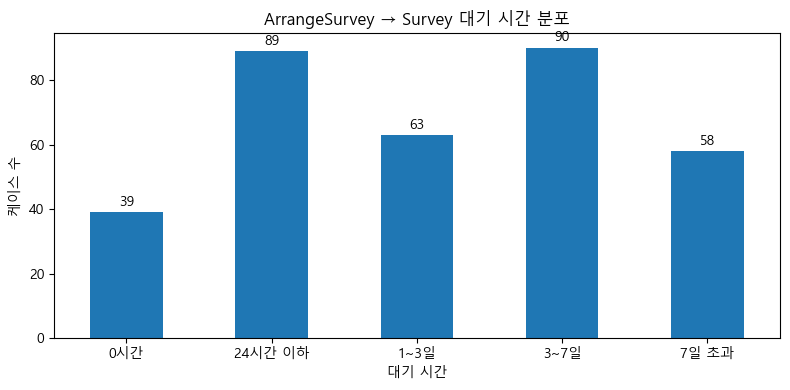

In [70]:
ax = wait_distribution['건수'].plot.bar(
    figsize=(8, 4),
    rot=0
)

# 막대 위에 건수 표시
for i, count in enumerate(wait_distribution['건수']):
    ax.text(i, count + 2, str(count), ha='center')

ax.set_title('ArrangeSurvey → Survey 대기 시간 분포')
ax.set_xlabel('대기 시간')
ax.set_ylabel('케이스 수')

plt.tight_layout()
plt.show()

**분석 결과 기록**
- 339건 중 211건(62.2%)에서 24시간을 초과하는 대기 시간이 기록

> 전체 처리 시간에서 대기 시간이 차지하는 비중
- ArrangeSurvey → Survey 대기 시간은 케이스의 전체 처리 시간에서 얼마나 큰 비중을 차지하는가?

In [71]:
# 케이스별 대기 시간과 전체 처리 시간 결합
wait_detail = wait_times[['ArrangeSurvey → Survey']].rename(
    columns={'ArrangeSurvey → Survey': '대기 시간(시간)'}
)

wait_detail = wait_detail.join(
    general_duration[['전체_처리_시간']]
)

wait_detail = wait_detail.dropna()

# 전체 처리 시간 중 대기 시간이 차지하는 비율
wait_detail['대기 시간 비중(%)'] = (
    wait_detail['대기 시간(시간)'] /
    wait_detail['전체_처리_시간'] * 100
)

# 비중 요약
display(
    wait_detail['대기 시간 비중(%)']
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(1)
)

# 전체 처리 시간의 절반 이상을 차지하는 케이스
over_half = (wait_detail['대기 시간 비중(%)'] >= 50).sum()

print('분석 건수:', len(wait_detail))
print('대기 시간 비중 중앙값:',
      round(wait_detail['대기 시간 비중(%)'].median(), 1), '%')
print('전체 처리 시간의 50% 이상을 차지하는 케이스:', over_half)
print('해당 케이스 비율:',
      round(over_half / len(wait_detail) * 100, 1), '%')

count    339.0
mean      55.4
std       33.4
min        0.0
25%       25.4
50%       66.3
75%       84.7
90%       93.2
max       98.1
Name: 대기 시간 비중(%), dtype: float64

분석 건수: 339
대기 시간 비중 중앙값: 66.3 %
전체 처리 시간의 50% 이상을 차지하는 케이스: 207
해당 케이스 비율: 61.1 %


**분석 결과 기록**
- 분석 대상 케이스의 절반 이상에서 해당 구간이 전체 처리 시간의 약 66.3% 이상을 차지한다
- 단순히 대기 시간이 길다는 것을 넘어 전체 처리 기간에서 큰 비중을 차지하는 즉 영향을 미치는 구간이라고 판단

##### 12-3-3. 접수 채널 및 수리 유형별 대기 시간 비교
앞서 확인된 '대기 시간'은 모든 케이스에서 비슷하게 나타나는가? 혹은 접수 채널이나 수리 유형에 따라 달라지는가?

① 접수 채널별 대기 시간 비교

In [72]:
# 케이스별 접수 채널과 수리 유형 추출
case_info = (
    df[['caseID', 'contact', 'RepairType']]
    .replace('', pd.NA)
    .groupby('caseID')
    .first()
)

# 업무 간 대기 시간과 결합
wait_compare = wait_times[['ArrangeSurvey → Survey']].rename(
    columns={'ArrangeSurvey → Survey': '대기 시간(시간)'}
).join(case_info)

# 24시간 초과 여부
wait_compare['24시간 초과 여부'] = (
    wait_compare['대기 시간(시간)'] > 24
)

# 접수 채널별 비교
contact_summary = (
    wait_compare.groupby('contact')
    .agg(
        케이스수=('대기 시간(시간)', 'count'),
        중앙값=('대기 시간(시간)', 'median'),
        P90=('대기 시간(시간)', lambda x: x.quantile(0.9)),
        초과건수=('24시간 초과 여부', 'sum')
    )
)

contact_summary['24시간 초과율(%)'] = (
    contact_summary['초과건수'] /
    contact_summary['케이스수'] * 100
)

display(contact_summary.round(1))

,케이스수,중앙값,P90,초과건수,24시간 초과율(%)
contact,,,,,
Letter,67,70.8,189.0,47,70.1
Personal,90,38.9,215.9,54,60.0
Phone,95,77.3,180.4,64,67.4
Web,87,26.0,184.0,46,52.9


**분석 결과 기록**
- 접수 채널별 중앙값에는 차이가 있지만 어느 한 채널에서만 긴 대기 시간이 발생하는 것은 아니다.
- Web의 ArrangeSurvey 업무 처리 시간은 길었지만 업무 완료 후 다음 업무 시작까지의 대기 시간이 가장 짧게 나타남

② 수리 유형별 대기 시간 비교

In [73]:
# 수리 유형별 대기 시간 비교
repair_summary = (
    wait_compare.groupby('RepairType')
    .agg(
        케이스수=('대기 시간(시간)', 'count'),
        중앙값=('대기 시간(시간)', 'median'),
        P90=('대기 시간(시간)', lambda x: x.quantile(0.9)),
        초과건수=('24시간 초과 여부', 'sum')
    )
)

repair_summary['24시간 초과율(%)'] = (
    repair_summary['초과건수'] /
    repair_summary['케이스수'] * 100
)

display(repair_summary.round(1))

,케이스수,중앙값,P90,초과건수,24시간 초과율(%)
RepairType,,,,,
B,46,0.0,0.8,0,0.0
E,143,88.4,219.5,109,76.2
P,150,52.4,183.7,102,68.0


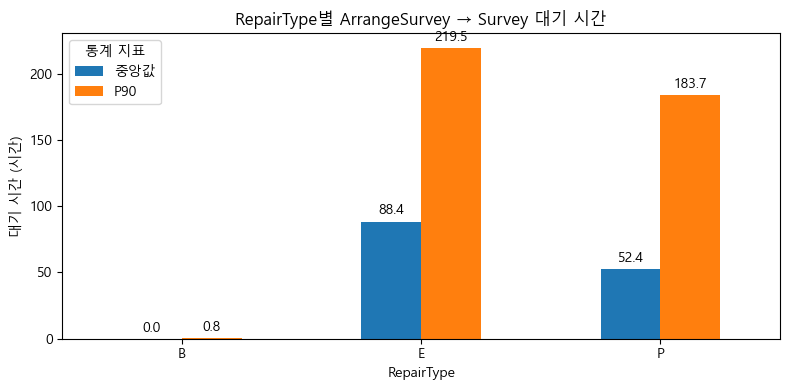

In [74]:
ax = repair_summary[['중앙값', 'P90']].plot.bar(
    figsize=(8, 4),
    rot=0
)

# 막대 위에 수치 표시
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

ax.set_title('RepairType별 ArrangeSurvey → Survey 대기 시간')
ax.set_xlabel('RepairType')
ax.set_ylabel('대기 시간 (시간)')
ax.legend(title='통계 지표')

plt.tight_layout()
plt.show()

**분석 결과 기록**
- ArrangeSurvey → Survey의 긴 대기 시간이 수리 유형에 따라 다르게 나타난다
- RepairType의 B, E, P가 구체적으로 어떤 수리 특성을 의미하는지는 현재 확인하지 않았음

> 현재 가장 주목할 결과는 RepairType별 대기 시간 차이

##### 12-3-4. RepairType별 수리 업무 구성과 대기 시간 비교
B 유형의 대기 시간이 짧은 이유가 수리 업무 구성의 차이 때문인가?

① RepairType별 수리 업무 구성 확인
- B·E·P 유형은 각각 어떤 수리 업무를 수행하는가?

In [75]:
# 분석 대상 케이스의 수리 업무 기록 확인
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

repair_events = df.loc[
    df['caseID'].isin(wait_compare.index) &
    df['taskID'].isin(repair_tasks),
    ['caseID', 'taskID']
]

# 케이스별 수리 업무 존재 여부
repair_task_flags = pd.crosstab(
    repair_events['caseID'],
    repair_events['taskID']
).reindex(
    index=wait_compare.index,
    columns=repair_tasks,
    fill_value=0
).gt(0)

# RepairType별 업무 수행 케이스 수
repair_task_summary = (
    repair_task_flags
    .groupby(wait_compare['RepairType'])
    .sum()
)

display(repair_task_summary)

taskID,InternRepair,ImmediateRepair,ExternRepair
RepairType,,,
B,30,8,11
E,143,0,6
P,17,124,32


② 동일한 수리 업무를 수행한 케이스 비교
- B와 P 모두 ImmediateRepair를 수행했는데 왜 B만 대기 시간이 짧을까

In [76]:
# 케이스별 수리 업무 조합 생성
repair_combinations = repair_task_flags.apply(
    lambda row: ' + '.join(row.index[row]),
    axis=1
)

# 대기 시간 데이터에 수리 업무 구성 연결
repair_detail = wait_compare[
    ['RepairType', '대기 시간(시간)']
].copy()

repair_detail['수리 업무 구성'] = repair_combinations

# 수리 업무 조합별 케이스 수
combination_summary = pd.crosstab(
    repair_detail['수리 업무 구성'],
    repair_detail['RepairType']
)

display(combination_summary)

# InternRepair만 수행한 케이스 비교
intern_only = repair_detail[
    repair_detail['수리 업무 구성'] == 'InternRepair'
]

intern_summary = (
    intern_only.groupby('RepairType')['대기 시간(시간)']
    .agg(
        케이스수='count',
        중앙값='median',
        P90=lambda x: x.quantile(0.9),
        최대값='max'
    )
    .round(1)
)

display(intern_summary)

RepairType,B,E,P
수리 업무 구성,,,
ExternRepair,8,0,16
ImmediateRepair,8,0,105
ImmediateRepair + ExternRepair,0,0,12
InternRepair,27,137,8
InternRepair + ExternRepair,3,6,2
InternRepair + ImmediateRepair,0,0,5
InternRepair + ImmediateRepair + ExternRepair,0,0,2


,케이스수,중앙값,P90,최대값
RepairType,,,,
B,27,0.0,1.6,3.2
E,137,87.8,218.6,310.0
P,8,85.3,127.8,167.0


**분석 결과 기록**
- 동일하게 InternRepair만 기록된 케이스에서도 B와 E 유형의 대기 시간에는 큰 차이가 나타남
- 따라서 대기 시간이 짧은 현상을 단순히 수리 업무 구성이 다르기 때문이라고 설명하기는 어려움

#### 12-4. 주요 지연 구간 종합 및 개선 대상 선정
전체 처리 시간에서 가장 많은 시간을 차지하는 구간을 확인하고 개선 우선순위를 선정


##### 12-4-1. 전체 처리 시간을 구간별로 나누어 비교
전체 케이스 처리 시간 중 각 구간이 차지하는 비중을 계산

In [77]:
# 주요 업무의 이벤트 시각
first_contact_end = event_time('FirstContact', 'complete')
arrange_end = event_time('ArrangeSurvey', 'complete')
survey_start = event_time('Survey', 'start')
repair_ready_end = event_time('RepairReady', 'complete')
ticket_ready_end = event_time('TicketReady', 'complete')

# 전체 처리 시간을 중복되지 않는 4개 구간으로 분리
process_times = pd.DataFrame(index=target_ids)

process_times['FirstContact → ArrangeSurvey'] = (
    arrange_end - first_contact_end
).dt.total_seconds() / 3600

process_times['ArrangeSurvey → Survey'] = (
    survey_start - arrange_end
).dt.total_seconds() / 3600

process_times['Survey → RepairReady'] = (
    repair_ready_end - survey_start
).dt.total_seconds() / 3600

process_times['RepairReady → TicketReady'] = (
    ticket_ready_end - repair_ready_end
).dt.total_seconds() / 3600

# 케이스별 전체 처리 시간
total_hours = (
    ticket_ready_end - first_contact_end
).dt.total_seconds() / 3600

# 네 구간을 합산한 시간과 전체 처리 시간이 일치하는지 검증
difference = (process_times.sum(axis=1) - total_hours).abs()

print('분석 케이스 수:', len(process_times))
print('시간 합계 최대 오차:', difference.max())
print('음수 시간 건수:', (process_times < 0).sum().sum())

# 구간별 요약
process_summary = pd.DataFrame({
    '중앙값(시간)': process_times.median(),
    'P90(시간)': process_times.quantile(0.9),
    '전체 대비 비중(%)': (
        process_times.sum() / total_hours.sum() * 100
    )
}).round(1)

display(process_summary)

분석 케이스 수: 339
시간 합계 최대 오차: 5.684341886080802e-14
음수 시간 건수: 0


,중앙값(시간),P90(시간),전체 대비 비중(%)
FirstContact → ArrangeSurvey,0.2,6.7,1.9
ArrangeSurvey → Survey,54.5,195.7,70.8
Survey → RepairReady,5.6,72.1,22.5
RepairReady → TicketReady,5.7,7.5,4.9


> ArrangeSurvey → Survey 구간이 전체 처리 시간 합계의 70.8%를 차지

##### 12-4-2. RepairType별 개선 검토 우선순위 확인
어떤 수리 유형에서 전체 처리 시간 중 해당 대기 구간의 비중이 특히 높은지 확인

In [78]:
# 케이스별 수리 유형 연결
case_repair_type = (
    df[['caseID', 'RepairType']]
    .replace('', pd.NA)
    .groupby('caseID')
    .first()
)

# 대기 시간과 전체 처리 시간 결합
priority_compare = pd.DataFrame({
    '대기 시간(시간)': process_times['ArrangeSurvey → Survey'],
    '전체 처리 시간(시간)': total_hours
}).join(case_repair_type)

# RepairType별 시간 합계 및 중앙값 비교
priority_summary = (
    priority_compare.groupby('RepairType')
    .agg(
        케이스수=('대기 시간(시간)', 'count'),
        대기_시간_중앙값=('대기 시간(시간)', 'median'),
        대기_시간_합계=('대기 시간(시간)', 'sum'),
        전체_처리_시간_합계=('전체 처리 시간(시간)', 'sum')
    )
)

# 유형별 전체 처리 시간 중 대기 시간 비중
priority_summary['대기 시간 비중(%)'] = (
    priority_summary['대기_시간_합계'] /
    priority_summary['전체_처리_시간_합계'] * 100
)

display(priority_summary.round(1))

,케이스수,대기_시간_중앙값,대기_시간_합계,전체_처리_시간_합계,대기 시간 비중(%)
RepairType,,,,,
B,46,0.0,11.1,577.5,1.9
E,143,88.4,14927.7,23527.7,63.4
P,150,52.4,11501.4,13254.6,86.8


**분석 결과 기록**

- E는 긴 대기 시간 자체가 문제 후보이고 P는 전체 처리 시간에서 해당 구간의 비중이 특히 크다


### 주요 지연 구간 종합 및 개선 대상 선정
**결과 정리**
- 일반 프로세스 339건의 전체 처리 시간을 4개 구간으로 나누어 분석한 결과 `ArrangeSurvey → Survey` 구간이 전체 처리 시간 합계의 70.8%를 차지함
- 해당 구간의 대기 시간 중앙값은 54.5시간, P90은 195.7시간으로 나타나 다른 구간에 비해 긴 시간이 소요되는 것으로 확인됨
- `Survey → RepairReady` 구간은 전체 처리 시간의 22.5%를 차지해 두 번째로 큰 비중을 보임
- `ArrangeSurvey → Survey` 구간을 RepairType별로 비교한 결과 B 유형의 대기 시간 중앙값은 0시간, E 유형은 88.4시간, P 유형은 52.4시간으로 나타남
- 유형별 전체 처리 시간 합계에서 해당 대기 구간이 차지하는 비중은 B 1.9%, E 63.4%, P 86.8%로 확인됨

**분석 결과 및 판단**
- `ArrangeSurvey → Survey`는 대기 시간의 길이와 전체 처리 시간에서 차지하는 비중을 고려할 때 **가장 우선적으로 검토할 구간**으로 판단
- E 유형은 대기 시간 자체가 길고 P 유형은 전체 처리 시간 중 대기 시간의 비중이 높게 나타나 두 유형을 중심으로 추가 검토할 필요가 있음
- B 유형은 상대적으로 대기 시간이 짧지만 수리 유형별 업무 특성이 다를 수 있으므로 B 유형의 처리 방식이 더 효율적이라고 단정할 수 없음.

**해석의 한계**
- 시간 분석이 가능한 일반 프로세스 339건만 대상으로 하므로 전체 수리 요청에 결과를 일반화하기 어려움
- 1970년 날짜의 정확성이 검증되지 않아 계산된 시간은 기록상 경과 시간으로 해석해야 함
- 긴 대기 시간이 실제 운영상의 비효율인지 정상적인 조사 일정 확보에 필요한 시간인지 구분할 수 없음
- RepairType별 대기 시간 차이는 확인됐지만 수리 난이도와 운영 방식 등의 영향을 검증하지 못했음

#### 12-5. 반복 수리 및 복합 수리에 따른 전체 처리 시간 비교

##### 12-5-1. 단일 수리와 복합 수리 비교
여러 종류의 수리 업무가 기록된 케이스는 단일 수리 케이스보다 전체 처리 시간이 긴가?

In [79]:
# 수리 업무 종류 정의
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

# 케이스별 수리 업무 종류 수
repair_kind_count = (
    df[df['taskID'].isin(repair_tasks)]
    .groupby('caseID')['taskID']
    .nunique()
)

# 일반 프로세스 339건의 전체 처리 시간
repair_analysis = general_duration[['전체_처리_시간']].copy()

repair_analysis['수리 업무 종류 수'] = (
    repair_kind_count.reindex(repair_analysis.index)
    .fillna(0)
    .astype(int)
)

# 수리 업무가 2종류 이상이면 복합 수리
repair_analysis['수리 구성'] = (
    repair_analysis['수리 업무 종류 수'] >= 2
).map({
    False: '단일 수리',
    True: '복합 수리'
})

# 전체 처리 시간 비교 (단위: 시간)
repair_summary = (
    repair_analysis.groupby('수리 구성')['전체_처리_시간']
    .agg(
        케이스수='count',
        중앙값='median',
        평균='mean',
        P90=lambda x: x.quantile(0.9)
    )
    .round(1)
)

display(repair_summary)

,케이스수,중앙값,평균,P90
수리 구성,,,,
단일 수리,309,78.2,112.9,266.1
복합 수리,30,65.3,82.5,197.5


> 단일과 복합 수리 여부 만으로는 큰 차이가 확인되지 않음

##### 12-5-2. InternRepair 반복 여부에 따른 비교
같은 InternRepair 업무가 반복해서 기록된 케이스는 전체 처리 시간이 길까?

In [80]:
# InternRepair의 start·complete 반복 여부 확인
intern_counts = (
    df[
        (df['taskID'] == 'InternRepair') &
        (df['eventtype'].isin(['start', 'complete']))
    ]
    .groupby(['caseID', 'eventtype'])
    .size()
    .unstack(fill_value=0)
)

intern_repeat = intern_counts.gt(1).any(axis=1)

# 케이스별 반복 여부 연결
repair_analysis['InternRepair 반복 여부'] = (
    intern_repeat.reindex(repair_analysis.index, fill_value=False)
)

# 케이스별 수리 업무 구성 확인
repair_combinations = (
    df[df['taskID'].isin(repair_tasks)]
    .groupby('caseID')['taskID']
    .agg(lambda x: ', '.join(sorted(x.unique())))
)

repair_analysis['수리 업무 구성'] = (
    repair_combinations.reindex(repair_analysis.index)
)

# InternRepair만 수행한 케이스 비교
intern_only = repair_analysis[
    repair_analysis['수리 업무 구성'] == 'InternRepair'
]

repeat_summary = (
    intern_only.groupby('InternRepair 반복 여부')['전체_처리_시간']
    .agg(
        케이스수='count',
        중앙값='median',
        평균='mean',
        P90=lambda x: x.quantile(0.9)
    )
    .round(1)
)

display(repeat_summary)

,케이스수,중앙값,평균,P90
InternRepair 반복 여부,,,,
False,160,99.5,131.1,304.5
True,12,269.2,214.3,348.9


> **결론**
- InternRepair만 수행한 케이스에서 반복 기록이 있는 집단의 전체 처리 시간 중앙값은 269.2시간으로 반복 기록이 없는 집단의 99.5시간보다 길게 나타났다. 다만 수리 유형과 난이도 등 다른 요인을 통제하지 않았기 때문에 업무의 반복 기록이 전체 처리 시간 증가의 원인이라고 판단하기는 어렵다.

----

## 13. 담당자별 업무 분석
- 앞선 단계에서는 ArrangeSurvey → Survey 구간이 전체 처리 시간에서 가장 큰 비중을 차지한다는 사실을 확인
- 담당자별로 업무량과 동일한 업무 처리 시간에 차이가 있는지 확인한다.

#### 13-1. 담당자별 업무 분포
특정 담당자에게 업무 기록이 집중되어 있는가? 담당자별로 수행하는 업무의 종류에도 차이가 있는가?
- 담당자별 처리 이벤트 수와 케이스 수 확인

In [81]:
# 담당자 분석에 사용할 데이터
worker_df = df[
    ['caseID', 'taskID', 'originator', 'eventtype']
].copy()

# 빈 문자열을 결측값으로 처리
worker_df = worker_df.replace('', pd.NA)

# 담당자별 업무 기록 요약
worker_summary = (
    worker_df.dropna(subset=['originator'])
    .groupby('originator')
    .agg(
        이벤트수=('caseID', 'size'),
        관련_케이스수=('caseID', 'nunique'),
        업무_종류수=('taskID', 'nunique'),
        시작_기록수=('eventtype', lambda x: (x == 'start').sum()),
        완료_기록수=('eventtype', lambda x: (x == 'complete').sum())
    )
    .sort_values('이벤트수', ascending=False)
)

# 전체 이벤트 대비 비중
worker_summary['이벤트 비중(%)'] = (
    worker_summary['이벤트수'] / len(df) * 100
).round(1)

print('담당자수:', len(worker_summary))
print('담당자 미기록 이벤트:', worker_df['originator'].isna().sum())

display(worker_summary)

담당자수: 16
담당자 미기록 이벤트: 2


,이벤트수,관련_케이스수,업무_종류수,시작_기록수,완료_기록수,이벤트 비중(%)
originator,,,,,,
System,4635,927,5,0,4633,34.9
Monica,2535,594,4,979,1555,19.1
Dian,2246,529,4,874,1372,16.9
Anne,865,231,3,433,432,6.5
Jacky,438,119,3,218,219,3.3
Barbara,428,121,3,214,214,3.2
John,396,166,2,198,198,3.0
Cindy,388,165,2,194,194,2.9
Paul,387,164,2,194,193,2.9


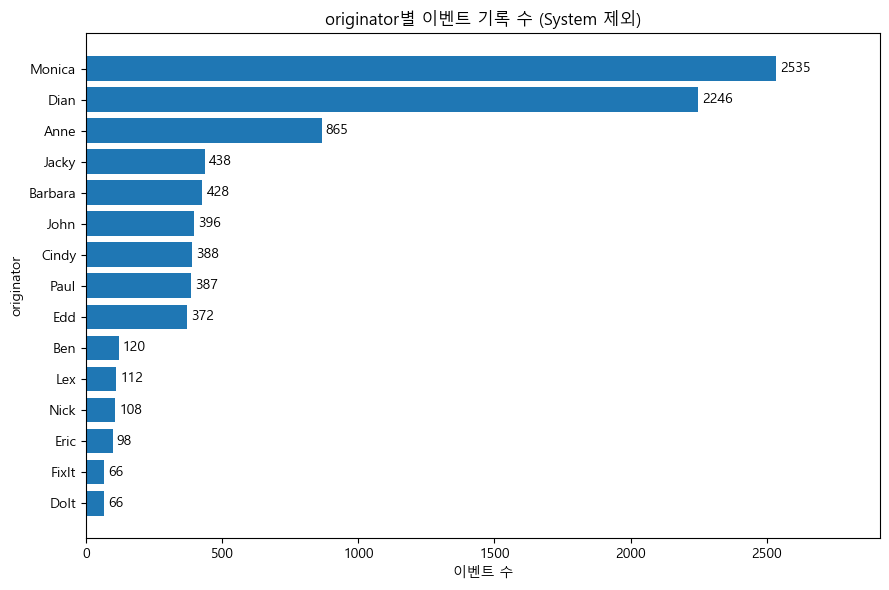

In [82]:
import matplotlib.pyplot as plt

# System 제외 (DoIt, FixIt은 원본 명칭 그대로 유지)
worker_plot = worker_summary.drop(
    index='System'
)['이벤트수'].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.barh(worker_plot.index, worker_plot.values)
ax.bar_label(bars, padding=3)

ax.set_title('originator별 이벤트 기록 수 (System 제외)')
ax.set_xlabel('이벤트 수')
ax.set_ylabel('originator')

ax.set_xlim(0, worker_plot.max() * 1.15)

plt.tight_layout()
plt.show()

In [83]:
# 케이스별 담당자 수 (System 제외)
case_worker_count = (
    worker_df[
        worker_df['originator'].notna() &
        (worker_df['originator'] != 'System')
    ]
    .groupby('caseID')['originator']
    .nunique()
)

print('담당자가 2명 이상인 케이스:',
      (case_worker_count >= 2).sum())

print('케이스별 담당자 수 분포:')
display(case_worker_count.value_counts().sort_index())

담당자가 2명 이상인 케이스: 927
케이스별 담당자 수 분포:


originator
1     73
2    402
3    449
4     73
5      3
Name: count, dtype: int64

In [84]:
# originator가 1개인 케이스
single_worker_ids = case_worker_count[
    case_worker_count == 1
].index

# 예외 처리 경로의 케이스
exception_ids = df.loc[
    df['taskID'] == 'InformClientWrongPlace',
    'caseID'
].unique()

print('originator 1개 & 예외 경로:',
      single_worker_ids.isin(exception_ids).sum())

originator 1개 & 예외 경로: 73


**분석 결과 기록**

- Monica와 Dian가 가장 많은 케이스, 업무, 이벤트를 가지고 있다. 다만 해당 결과만으로 이들의 업무 부담이 높다고 해석할 수 없다.
- 각 담당자 마다 맡고 있는 업무의 수가 다르다. 즉 하나의 케이스와 요청에 대해 한명이 처리하는 구조가 아니라 전체 과정을 분담해서 처리할 가능성이 있음
    - originator가 1개인 케이스 73건은 모두 예외 처리 경로와 일치함
    - 따라서 일반 프로세스 927건에서는 모두 2개 이상의 originator가 기록되었음
    - 단 두명의 담당자가 서로 업무를 인계하면서 진행했는지는 확인 필요


#### 13-2. 업무별 담당자 분포 분석
담당자별로 특정 업무를 주로 맡는 구조인가?


① 업무별 담당자 분포 확인

In [85]:
# 담당자와 업무가 기록된 이벤트만 선택
task_workers = worker_df.dropna(
    subset=['taskID', 'originator']
).copy()

# 동일 케이스·업무·originator의 중복 이벤트 제거
task_workers = task_workers.drop_duplicates(
    subset=['caseID', 'taskID', 'originator']
)

# 업무별 담당자 관여 케이스 수
task_worker_counts = (
    task_workers.groupby(['taskID', 'originator'])
    .size()
    .reset_index(name='관여_케이스수')
)

# 담당자가 많은 주요 업무 확인
focus_tasks = [
    'FirstContact', 'MakeTicket', 'ArrangeSurvey',
    'Survey', 'InternRepair', 'ImmediateRepair',
    'ExternRepair'
]

task_worker_summary = (
    task_worker_counts[
        task_worker_counts['taskID'].isin(focus_tasks)
    ]
    .sort_values(
        ['taskID', '관여_케이스수'],
        ascending=[True, False]
    )
)

display(task_worker_summary)

,taskID,originator,관여_케이스수
1,ArrangeSurvey,Monica,550
0,ArrangeSurvey,Dian,500
2,ExternRepair,DoIt,66
3,ExternRepair,FixIt,66
5,FirstContact,Monica,534
4,FirstContact,Dian,465
6,ImmediateRepair,Anne,185
10,ImmediateRepair,Jacky,92
7,ImmediateRepair,Barbara,88
11,ImmediateRepair,Lex,7


- FirstContact, MakeTicket, ArrangeSurvey는 Monica와 Dian이 담당
- Survey, InternRepair는 여러 담당자에게 분산되어 있음
- ImmediateRepair는 Anne, Jacky, Barbara가 주로 담당
- 시스템 관련 후속 업무인 RepairReady, TicketReady 등은 System으로 확인


② ArrangeSurvey → Survey 담당자 변경 여부 확인
- ArrangeSurvey 완료 담당자와 Survey 시작 담당자가 다른가?

In [86]:
# ArrangeSurvey 완료 시점의 originator
arrange_worker = (
    worker_df[
        (worker_df['taskID'] == 'ArrangeSurvey') &
        (worker_df['eventtype'] == 'complete')
    ]
    .dropna(subset=['originator'])
    .set_index('caseID')['originator']
)

# Survey 시작 시점의 originator
survey_worker = (
    worker_df[
        (worker_df['taskID'] == 'Survey') &
        (worker_df['eventtype'] == 'start')
    ]
    .dropna(subset=['originator'])
    .set_index('caseID')['originator']
)

# 케이스별 두 업무의 담당자 비교
worker_change = pd.DataFrame({
    'ArrangeSurvey 완료 담당자': arrange_worker,
    'Survey 시작 담당자': survey_worker
}).dropna()

worker_change['담당자 변경 여부'] = (
    worker_change['ArrangeSurvey 완료 담당자']
    != worker_change['Survey 시작 담당자']
)

print('비교 가능한 케이스:', len(worker_change))
display(worker_change['담당자 변경 여부'].value_counts())

비교 가능한 케이스: 927


담당자 변경 여부
True    927
Name: count, dtype: int64

 일반 프로세스 927건 모두 ArrangeSurvey 완료 담당자와 Survey 시작 담당자가 다른것으로 확인됨
> ArrangeSurvey → Survey의 대기 시간이 길다는 사실과 담당자가 변경된다는 사실은 확인됐지만 담당자 변경이 지연의 원인이라고 판단할 수는 없다.

#### 13-3. 업무 집중도 및 병목 연관성 확인


① 시작·완료 이벤트 연결 및 담당자 확인: 업무의 시작·완료 기록을 연결했을 때 담당자가 일치하는가?
- 담당자 개인의 처리 시간을 비교할 때는 시작·완료 담당자가 동일한 기록만 사용하기 위해서 start와 complete의 originator가 동일한지 먼저 확인

In [87]:
# 시작·완료 기록만 선택
pair_events = df.loc[
    df['eventtype'].isin(['start', 'complete']) &
    df['taskID'].notna(),
    ['caseID', 'taskID', 'eventtype', 'originator', 'timestamp']
].copy()

# 시작과 완료가 각각 1개인 업무만 선택
counts = (
    pair_events.groupby(['caseID', 'taskID', 'eventtype'])
    .size()
    .unstack(fill_value=0)
)

valid_keys = counts.index[
    (counts['start'] == 1) &
    (counts['complete'] == 1)
]

pair_events = (
    pair_events.set_index(['caseID', 'taskID'])
    .loc[valid_keys]
    .reset_index()
)

# 시작·완료 데이터 연결
starts = pair_events[pair_events['eventtype'] == 'start'][
    ['caseID', 'taskID', 'originator', 'timestamp']
].rename(columns={
    'originator': '시작 담당자',
    'timestamp': '시작 시각'
})

ends = pair_events[pair_events['eventtype'] == 'complete'][
    ['caseID', 'taskID', 'originator', 'timestamp']
].rename(columns={
    'originator': '완료 담당자',
    'timestamp': '완료 시각'
})

worker_pairs = starts.merge(ends, on=['caseID', 'taskID'])

worker_pairs['처리 시간(분)'] = (
    worker_pairs['완료 시각'] - worker_pairs['시작 시각']
).dt.total_seconds() / 60

# 시간 분석 후보만 선택
worker_pairs = worker_pairs[
    worker_pairs['시작 시각'].dt.year.eq(1970) &
    worker_pairs['완료 시각'].dt.year.eq(1970) &
    worker_pairs['처리 시간(분)'].ge(0)
].copy()

# 담당자 동일 여부
worker_pairs['담당자 동일 여부'] = (
    worker_pairs['시작 담당자'] ==
    worker_pairs['완료 담당자']
)

display(worker_pairs['담당자 동일 여부'].value_counts(dropna=False))

담당자 동일 여부
True     3045
False     106
Name: count, dtype: int64

② 일 업무 내 담당자별 처리 시간 비교
- 동일한 업무를 수행한 담당자끼리 비교하면 처리 시간에 차이가 나타나는가?

In [88]:
# 시작·완료 담당자가 동일한 기록만 선택
same_worker = worker_pairs[
    worker_pairs['담당자 동일 여부'] == True
].copy()

# 케이스별 RepairType 연결
case_repair_type = df.groupby('caseID')['RepairType'].first()

same_worker['RepairType'] = (
    same_worker['caseID'].map(case_repair_type)
)

# Survey 담당자별 처리 시간 비교
survey_summary = (
    same_worker[same_worker['taskID'] == 'Survey']
    .groupby(['RepairType', '시작 담당자'])['처리 시간(분)']
    .agg(
        건수='count',
        중앙값='median',
        P90=lambda x: x.quantile(0.9)
    )
    .round(1)
)

display(survey_summary)

건수   중앙값   P90
RepairType 시작 담당자                  
B          Ben       32  26.5  41.0
           Eric      20  28.5  41.4
           Lex       25  33.0  44.0
           Nick      27  26.0  37.0
E          Cindy     82  38.5  55.9
           Edd       68  32.5  54.3
           John      90  37.5  58.0
           Paul      83  39.0  55.8
P          Anne     183  45.0  57.8
           Barbara   98  46.5  58.0
           Jacky    100  44.5  57.1

③ ArrangeSurvey의 담당자 변경과 처리 시간
- 담당자별 업무 처리 시간에서는 차이가 발견되었다.
- 그렇다면 시작과 완료를 서로 다른 담당자가 기록한 케이스와 동일한 담당자가 기록한 케이스의 처리 시간은 차이가 있을까?

In [89]:
# ArrangeSurvey만 선택
arrange_worker = worker_pairs[
    worker_pairs['taskID'] == 'ArrangeSurvey'
]

# 시작·완료 담당자 동일 여부에 따른 처리 시간
arrange_worker_summary = (
    arrange_worker.groupby('담당자 동일 여부')['처리 시간(분)']
    .agg(
        건수='count',
        중앙값='median',
        P90=lambda x: x.quantile(0.9)
    )
    .round(1)
)

display(arrange_worker_summary)

,건수,중앙값,P90
담당자 동일 여부,,,
False,105,332.0,1049.6
True,704,4.0,231.5


**분석 결과 기록**

- 시간 분석이 가능한 업무 3,151건 중 시작·완료 담당자가 동일한 기록은 3,045건, 서로 다른 기록은 105건이며 담당자 정보 누락은 1건
    - 시작·완료 담당자가 다른 105건은 모두 ArrangeSurvey에서 발생함.
- Survey 업무는 RepairType에 따라 담당자 집단이 구분되어 있으며 동일한 RepairType 내에서는 담당자별 처리 시간 중앙값에 시간 차이가 존재했지만 상대적으로 작은 차이가 나타남
- 반면 ArrangeSurvey의 시작·완료 담당자가 동일한 건은 처리 시간 중앙값이 4분, 담당자가 다른 105건은 332분으로 큰 차이를 보였음
    - 90백분위 역시 담당자가 동일한 집단은 231.5분, 다른 집단은 1,049.6분으로 큰 차이를 보였음


#### 13-4. 접수 채널별 ArrangeSurvey 담당자 변경과 처리 시간 비교
- 앞선 분석으로 Web과 Letter에서 그리고 담당자가 변경되었을 때 처리 시간이 길어지는 것을 확인했다.
- 그렇다면 이 둘의 관계는 어떨까?

① 접수 채널별 담당자 변경 비율
- ArrangeSurvey의 시작·완료 담당자가 달라지는 사례는 특정 접수 채널에 집중되는가?

In [90]:
# ArrangeSurvey 업무만 선택
arrange_worker = worker_pairs[
    worker_pairs['taskID'] == 'ArrangeSurvey'
].copy()

# 케이스별 접수 채널 연결
case_contact = (
    df[['caseID', 'contact']]
    .replace('', pd.NA)
    .groupby('caseID')['contact']
    .first()
)

arrange_worker['contact'] = arrange_worker['caseID'].map(case_contact)

# 시작·완료 담당자 변경 여부
arrange_worker['담당자 변경 여부'] = (
    arrange_worker['시작 담당자'] != arrange_worker['완료 담당자']
)

# 접수 채널별 비교
change_summary = pd.crosstab(
    arrange_worker['contact'],
    arrange_worker['담당자 변경 여부']
).rename(columns={
    False: '담당자 동일',
    True: '담당자 변경'
})

change_summary['담당자 변경 비율(%)'] = (
    change_summary['담당자 변경'] /
    change_summary[['담당자 동일', '담당자 변경']].sum(axis=1) * 100
).round(1)

display(change_summary)

담당자 변경 여부,담당자 동일,담당자 변경,담당자 변경 비율(%)
contact,,,
Letter,127,48,27.4
Personal,203,0,0.0
Phone,224,0,0.0
Web,150,57,27.5


> 담당자 변경 105건은 모두 Web과 Letter 접수에서 나타났다.

② 동일 접수 채널 내 담당자 변경 여부 비교
- Web과 Letter 안에서도 담당자가 변경된 케이스의 처리 시간이 긴가?

In [91]:
# 1시간 초과 여부
arrange_worker['1시간 초과 여부'] = (
    arrange_worker['처리 시간(분)'] > 60
)

# 접수 채널과 담당자 변경 여부별 비교
worker_contact_summary = (
    arrange_worker
    .groupby(['contact', '담당자 변경 여부'])
    .agg(
        건수=('caseID', 'count'),
        중앙값_분=('처리 시간(분)', 'median'),
        P90_분=('처리 시간(분)', lambda x: x.quantile(0.9)),
        초과건수=('1시간 초과 여부', 'sum')
    )
)

worker_contact_summary['1시간 초과율(%)'] = (
    worker_contact_summary['초과건수'] /
    worker_contact_summary['건수'] * 100
)

display(worker_contact_summary.round(1))

건수  중앙값_분   P90_분  초과건수  1시간 초과율(%)
contact  담당자 변경 여부                                      
Letter   False      127    4.0   495.2    37        29.1
         True        48  317.5  1030.7    48       100.0
Personal False      203    4.0     5.0     0         0.0
Phone    False      224    3.0     5.0     0         0.0
Web      False      150    5.0   653.4    52        34.7
         True        57  374.0  1045.4    57       100.0

> 같은 접수 채널 안에서도 담당자가 변경된 집단의 처리 시간이 훨씬 긴것으로 확인

③ 같은 접수 채널 내 처리 시간 비교

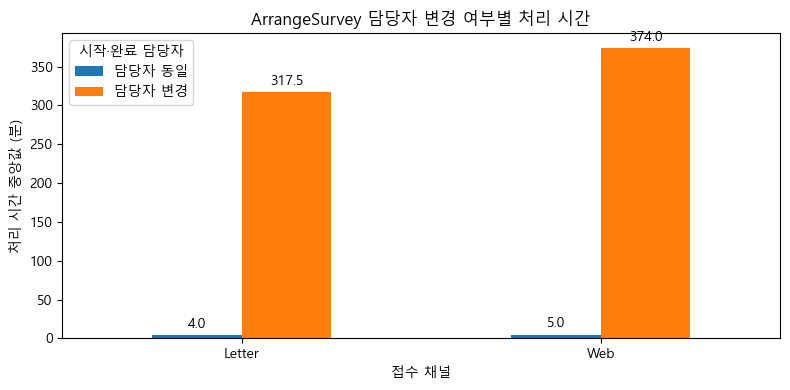

In [92]:
# Web, Letter만 선택해 중앙값 비교
plot_summary = (
    arrange_worker[
        arrange_worker['contact'].isin(['Web', 'Letter'])
    ]
    .groupby(['contact', '담당자 변경 여부'])['처리 시간(분)']
    .median()
    .unstack()
    .rename(columns={
        False: '담당자 동일',
        True: '담당자 변경'
    })
)

ax = plot_summary.plot.bar(figsize=(8, 4), rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', padding=3)

ax.set_title('ArrangeSurvey 담당자 변경 여부별 처리 시간')
ax.set_xlabel('접수 채널')
ax.set_ylabel('처리 시간 중앙값 (분)')
ax.legend(title='시작·완료 담당자')

plt.tight_layout()
plt.show()

**분석 결과 요약**
- ArrangeSurvey 담당자가 변경된 사례(전체의 13%)는 모두 Web과 Letter 채널에서 발생했으며, 이때 처리 시간 중앙값이 담당자 유지 시(4~5분)보다 크게 증가(317~374분)
    - 하지만 담당자가 유지된 경우에도 1시간 초과 사례(89건)가 존재하므로, 담당자 변경이 지연의 유일한 원인은 아님
- 기록상 담당자가 다르다는 것만으로 실제 인수인계 여부나 지연과의 인과관계를 확정할 수 없음
- 이번 결과는 단일 업무에 한정되므로 ArrangeSurvey → Survey 구간의 대기 시간 지연 원인으로 확대 해석할 수 없음
    - 산출된 시간은 데이터 한계상 '기록상 경과 시간'으로만 해석

#### 13-5. Survey 담당자별 업무량과 대기 시간 비교
Survey 업무를 많이 수행하는 담당자일수록 해당 업무가 시작되기까지의 대기 시간이 긴가?
- ArrangeSurvey 업무 내부에서 시작·완료 담당자가 다른 경우 처리 시간이 길게 나타났음
- 이번에는 ArrangeSurvey → Survey의 대기 시간이 Survey 담당자에 따라 다른지 확인

① 전체 데이터에서 담당자별 Survey 수행 건수 확인

In [93]:
# Survey 시작 이벤트 추출
survey_events = df.loc[
    (df['taskID'] == 'Survey') &
    (df['eventtype'] == 'start'),
    ['caseID', 'originator', 'timestamp']
].copy()

survey_events['originator'] = (
    survey_events['originator'].replace('', pd.NA)
)

# 전체 일반 프로세스의 담당자별 수행 케이스 수
survey_worker_counts = (
    survey_events.dropna(subset=['originator'])
    .groupby('originator')['caseID']
    .nunique()
    .rename('전체 Survey 수행 건수')
)

display(survey_worker_counts.sort_values(ascending=False))

originator
Anne       218
Barbara    111
Jacky      110
John       101
Paul        94
Cindy       94
Edd         81
Ben         35
Nick        33
Lex         27
Eric        23
Name: 전체 Survey 수행 건수, dtype: int64

② 담당자별 대기 시간 계산

In [94]:
# 시간 분석 대상: 일반 프로세스 339건
target_ids = general_duration.index

# ArrangeSurvey 완료 시각
arrange_end = (
    df.loc[
        df['caseID'].isin(target_ids) &
        (df['taskID'] == 'ArrangeSurvey') &
        (df['eventtype'] == 'complete')
    ]
    .groupby('caseID')['timestamp']
    .min()
)

# Survey 시작 시각 및 담당자
survey_target = survey_events[
    survey_events['caseID'].isin(target_ids)
].copy()

# 시작 이벤트 중복 검증
print('Survey 시작 이벤트 중복 케이스:',
      survey_target['caseID'].duplicated().sum())

# 케이스별 수리 유형
case_repair_type = (
    df[['caseID', 'RepairType']]
    .replace('', pd.NA)
    .groupby('caseID')['RepairType']
    .first()
)

# 분석 데이터 결합
worker_wait = (
    survey_target.set_index('caseID')
    .rename(columns={
        'originator': 'Survey 담당자',
        'timestamp': 'Survey 시작 시각'
    })
    .join(arrange_end.rename('ArrangeSurvey 완료 시각'))
    .join(case_repair_type)
)

# 대기 시간 계산
worker_wait['대기 시간(시간)'] = (
    worker_wait['Survey 시작 시각']
    - worker_wait['ArrangeSurvey 완료 시각']
).dt.total_seconds() / 3600

worker_wait = worker_wait.dropna(
    subset=['대기 시간(시간)', 'Survey 담당자', 'RepairType']
)

print('분석 케이스 수:', len(worker_wait))
print('음수 대기 시간:', (worker_wait['대기 시간(시간)'] < 0).sum())

Survey 시작 이벤트 중복 케이스: 0
분석 케이스 수: 339
음수 대기 시간: 0


③ 전체 수행 건수와 대기 시간 비교

In [95]:
# 수리 유형별 담당자 대기 시간
worker_wait_summary = (
    worker_wait.groupby(['RepairType', 'Survey 담당자'])
    .agg(
        분석_케이스수=('대기 시간(시간)', 'count'),
        대기_시간_중앙값=('대기 시간(시간)', 'median'),
        P90=('대기 시간(시간)', lambda x: x.quantile(0.9))
    )
    .reset_index()
)

# 전체 데이터의 Survey 수행 건수 연결
worker_wait_summary['전체 Survey 수행 건수'] = (
    worker_wait_summary['Survey 담당자'].map(survey_worker_counts)
)

display(worker_wait_summary.round(1))

,RepairType,Survey 담당자,분석_케이스수,대기_시간_중앙값,P90,전체 Survey 수행 건수
0,B,Ben,16,0.0,0.0,35
1,B,Eric,8,0.0,1.2,23
2,B,Lex,10,0.0,0.8,27
3,B,Nick,12,0.0,0.0,33
4,E,Cindy,34,114.5,236.1,94
5,E,Edd,32,65.1,215.2,81
6,E,John,37,82.6,168.2,101
7,E,Paul,40,113.8,227.5,94
8,P,Anne,71,54.5,202.4,218
9,P,Barbara,41,80.8,183.4,111


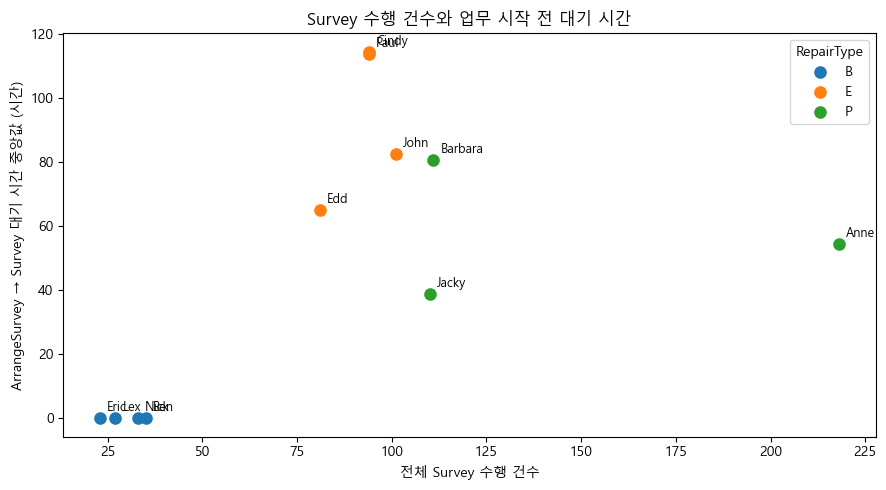

In [96]:
fig, ax = plt.subplots(figsize=(9, 5))

for repair_type, group in worker_wait_summary.groupby('RepairType'):
    ax.scatter(
        group['전체 Survey 수행 건수'],
        group['대기_시간_중앙값'],
        label=repair_type,
        s=65
    )

    for _, row in group.iterrows():
        ax.annotate(
            row['Survey 담당자'],
            (row['전체 Survey 수행 건수'],
             row['대기_시간_중앙값']),
            xytext=(5, 5),
            textcoords='offset points',
            fontsize=9
        )

ax.set_title('Survey 수행 건수와 업무 시작 전 대기 시간')
ax.set_xlabel('전체 Survey 수행 건수')
ax.set_ylabel('ArrangeSurvey → Survey 대기 시간 중앙값 (시간)')
ax.legend(title='RepairType')

plt.tight_layout()
plt.show()

> 담당자의 많은 업무 부담 즉 전체 수행 건수가 반드시 긴 대기 시간으로 연결되지는 않는다

#### 담당자별 업무 분석 종합
**요약**
- 전체 1,000건 중 일반 프로세스 927건에서는 2명 이상의 담당자가 기록되었으며 예외 처리 경로 73건에서는 1개만 기록됨
- ArrangeSurvey와 Survey는 서로 다른 담당자가 수행하는 것으로 확인됨
- **ArrangeSurvey의 시작·완료 담당자가 다른 105건은 모두 Web·Letter 접수에서 발생했으며 담당자가 동일한 경우보다 처리 시간이 길게 나타남**
- Survey 담당자별 수행 건수와 ArrangeSurvey → Survey 대기 시간 사이에서는 일관된 증가 관계가 확인되지 않음

> 따라서 특정 담당자의 업무 부담보다 업무 배정 및 전달 과정의 개선 가능성을 검토할 필요가 있음

**한계**
- 실제 업무 배정 시각과 담당자별 미처리 업무량이 없어 업무 과부하 여부를 확인할 수 없음
- 1970년 날짜의 정확성이 검증되지 않아 시간 분석 결과는 탐색적으로 해석해야 함

----

## 14. 수리 속성과 소요 시간의 관계 분석
- 앞선 단계에서는 담당자별 업무 분담과 처리 시간의 차이를 분석
- 해당 단계에서는 수리 요청의 특성에 따라 실제 소요 시간이 달라지는지 확인

#### 14-1. RepairType별 전체 처리 시간 비교
- RepairType에 따라 전체 처리 시간과 조사 이후 처리 시간에 차이가 있는가?
- 앞에서는 E·P 유형의 ArrangeSurvey → Survey 대기 시간이 길다는 사실을 확인했다. 그렇다면 실제 조사가 끝난 이후에도 수리 유형에 따라 시간이 다르게 소요될까?

In [97]:
# 분석 대상: 시간 분석이 가능한 일반 프로세스 339건
target_df = df[
    df['caseID'].isin(general_duration.index)
].copy()

# 업무별 이벤트 시각 추출
def get_event_time(task, event):
    return (
        target_df[
            (target_df['taskID'] == task) &
            (target_df['eventtype'] == event)
        ]
        .groupby('caseID')['timestamp']
        .min()
    )

# 주요 업무 시각
first_contact_end = get_event_time('FirstContact', 'complete')
survey_end = get_event_time('Survey', 'complete')
repair_ready_end = get_event_time('RepairReady', 'complete')
ticket_ready_end = get_event_time('TicketReady', 'complete')

# 케이스별 수리 유형
case_repair_type = (
    target_df[['caseID', 'RepairType']]
    .replace('', pd.NA)
    .groupby('caseID')['RepairType']
    .first()
)

# 케이스별 처리 시간 계산
repair_time_compare = pd.DataFrame(
    index=general_duration.index
)

repair_time_compare['RepairType'] = case_repair_type

repair_time_compare['전체 처리 시간(시간)'] = (
    ticket_ready_end - first_contact_end
).dt.total_seconds() / 3600

repair_time_compare['조사 완료 후 처리 시간(시간)'] = (
    repair_ready_end - survey_end
).dt.total_seconds() / 3600

# 수리 유형별 요약
repair_type_summary = (
    repair_time_compare.groupby('RepairType')
    .agg(
        케이스수=('전체 처리 시간(시간)', 'count'),
        전체_처리_시간_중앙값=('전체 처리 시간(시간)', 'median'),
        전체_처리_시간_P90=(
            '전체 처리 시간(시간)', lambda x: x.quantile(0.9)
        ),
        조사_완료_후_분석건수=('조사 완료 후 처리 시간(시간)', 'count'),
        조사_완료_후_처리_시간_중앙값=(
            '조사 완료 후 처리 시간(시간)', 'median'
        )
    )
    .round(1)
)

display(repair_type_summary)

,케이스수,전체_처리_시간_중앙값,전체_처리_시간_P90,조사_완료_후_분석건수,조사_완료_후_처리_시간_중앙값
RepairType,,,,,
B,46,11.6,20.3,46,3.2
E,143,160.4,313.5,143,33.0
P,150,71.4,196.1,149,2.2


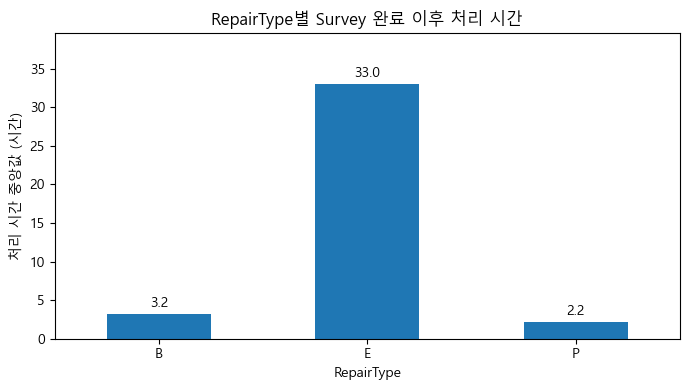

In [98]:
plot_data = repair_type_summary[
    '조사_완료_후_처리_시간_중앙값'
]

ax = plot_data.plot.bar(figsize=(7, 4), rot=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

ax.set_title('RepairType별 Survey 완료 이후 처리 시간')
ax.set_xlabel('RepairType')
ax.set_ylabel('처리 시간 중앙값 (시간)')
ax.set_ylim(0, plot_data.max() * 1.2)

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 앞선 조사 단계에서의 대기시간도 E유형이 가장 길게 나타났는데 조사 완료 이후의 단계에서도 길게 나타났다.
- 따라서 대기 시간이 긴 것이 전체 수리 시간을 길게 한다고 하기 어렵다.

> 그렇다면 E 유형에서 조사 완료 이후 시간이 오래 걸리는 이유는 실제 수리 업무의 처리 시간이 길기 때문일까 아니면 수리 업무 사이에 추가적인 대기 시간이 발생하기 때문일까?


#### 14-2. RepairInternally·RepairCode별 수리 시간 비교
내부 수리 여부와 수리 코드에 따라 실제 수리 업무의 처리 시간이 달라지는가?
- RepairType별 처리 시간 비교
- RepairInternally별 처리 시간 비교
- RepairCode별 처리 시간 비교

> 시간 분석 대상 339건 중 24건의 경우 완료 이벤트가 기록되어 있지 않아 소요 시간 분석이 불가

In [99]:
# 원본 데이터에서 수리 속성 추출
repair_raw = pd.read_csv(
    'repair2.csv',
    dtype='string',
    keep_default_na=False,
    encoding='utf-8-sig'
)

# 기존 분석 데이터와 caseID 타입 통일
repair_raw['caseID'] = pd.to_numeric(
    repair_raw['caseID'],
    errors='raise'
).astype('int64')

# 케이스별 수리 속성 정리
repair_attributes = (
    repair_raw[
        ['caseID', 'RepairInternally', 'RepairCode', 'RepairType']
    ]
    .replace('', pd.NA)
    .groupby('caseID')
    .first()
)

# 시간 분석 대상 339건의 수리 속성 확인
target_attributes = repair_attributes.loc[general_duration.index]

print('분석 케이스 수:', len(target_attributes))

display(pd.crosstab(
    target_attributes['RepairInternally'],
    target_attributes['RepairCode']
))

분석 케이스 수: 339


RepairCode,1,2,3,4
RepairInternally,,,,
FALSE,0,0,0,24
TRUE,208,76,31,0


> 내부·외부 수리 간 직접 비교가 불가능하므로, 처리 시간을 계산할 수 있는 내부 수리 업무에서 RepairCode별 차이를 확인

In [100]:
# 실제 수리 업무의 시작·완료 시간이 연결된 기록
repair_times = time_pairs.loc[
    time_pairs['caseID'].isin(general_duration.index) &
    time_pairs['taskID'].isin(['InternRepair', 'ImmediateRepair']),
    ['caseID', 'taskID', 'duration_min']
].copy()

# 수리 속성 연결
repair_times = repair_times.join(
    repair_attributes,
    on='caseID'
)

print('분석 업무 기록:', len(repair_times))
print('분석 케이스:', repair_times['caseID'].nunique())

# 업무별·RepairCode별 처리 시간 비교
repair_code_summary = (
    repair_times
    .groupby(['taskID', 'RepairCode'])['duration_min']
    .agg(
        건수='count',
        중앙값='median',
        P90=lambda x: x.quantile(0.9)
    )
    .round(1)
)

display(repair_code_summary)

분석 업무 기록: 310
분석 케이스: 303


건수    중앙값    P90
taskID          RepairCode                   
ImmediateRepair 1           111  120.0  132.0
                3            21  120.0  132.0
InternRepair    1            96  240.0  264.0
                2            71  220.0  264.0
                3            11  160.0  176.0

**분석 결과 기록**

- RepairCode와 수리 업무 종류에 따라 처리 시간에 차이가 있다는 것을 확인
- 다만 내외부 수리에 대한 직접적인 비교는 불가
- 앞서 확인한 E 유형의 Survey 완료 이후 처리 시간 중앙값은 33시간이었고 이번에 확인한 InternRepair 자체의 처리 시간은 약 4시간이다. 즉 그 사이에 29시간이라는 차이가 존재한다. 다만 이것만 보고 추가 대기시간이 발생했다라고 단정지을 수 없다.


#### 14-3. 예상 수리 시간과 실제 처리 시간 비교
예상 수리 시간과 실제 처리 시간 사이에 차이가 있는가? 차이가 있다면 특정 업무에서 크게 나타나는가?
- EstimatedRepairTime의 의미와 단위 확인
- 비교 가능한 실제 수리 시간과 차이 분석

① 예상 시간과 실제 작업 시간 비교

In [101]:
# 케이스별 예상 수리 시간 추출
case_estimated = pd.to_numeric(
    df[['caseID', 'EstimatedRepairTime']]
    .replace('', pd.NA)
    .groupby('caseID')['EstimatedRepairTime']
    .first(),
    errors='coerce'
)

# 14-2의 수리 업무 처리 시간 활용
estimate_compare = repair_times[
    ['caseID', 'taskID', 'duration_min']
].copy()

# 예상 수리 시간 연결
estimate_compare['예상 수리 시간'] = (
    estimate_compare['caseID'].map(case_estimated)
)

estimate_compare = estimate_compare.dropna(
    subset=['duration_min', '예상 수리 시간']
)

# 실제 시간 - 예상 시간 (분 단위 가정)
estimate_compare['시간 차이(분)'] = (
    estimate_compare['duration_min']
    - estimate_compare['예상 수리 시간']
)

# 예상 시간 대비 차이율
estimate_compare['차이율(%)'] = (
    estimate_compare['시간 차이(분)']
    / estimate_compare['예상 수리 시간'] * 100
)

# 업무별 비교
estimate_summary = (
    estimate_compare.groupby('taskID')
    .agg(
        기록수=('caseID', 'count'),
        예상시간_중앙값=('예상 수리 시간', 'median'),
        실제시간_중앙값=('duration_min', 'median'),
        시간차이_중앙값=('시간 차이(분)', 'median'),
        절대차이율_중앙값=(
            '차이율(%)', lambda x: x.abs().median()
        )
    )
    .round(1)
)

print('비교 기록 수:', len(estimate_compare))
print('비교 케이스 수:', estimate_compare['caseID'].nunique())

display(estimate_summary)

비교 기록 수: 310
비교 케이스 수: 303


,기록수,예상시간_중앙값,실제시간_중앙값,시간차이_중앙값,절대차이율_중앙값
taskID,,,,,
ImmediateRepair,132,120.0,120.0,0.0,10.0
InternRepair,178,240.0,240.0,0.0,10.0


② 예상 시간과 실제 시간의 차이 확인
- 개별 수리 기록에서도 예상 시간과 실제 시간이 비슷하게 나타나는가?

In [102]:
# 차이율을 소수점 첫째 자리로 정리
estimate_compare['차이율(%)'] = (
    estimate_compare['차이율(%)'].round(1)
)

# 차이율별 기록 수
error_distribution = (
    estimate_compare['차이율(%)']
    .value_counts()
    .sort_index()
    .rename_axis('차이율(%)')
    .to_frame('기록 수')
)

error_distribution['비율(%)'] = (
    error_distribution['기록 수']
    / len(estimate_compare) * 100
).round(1)

display(error_distribution)

# 예상 시간과 실제 시간의 상관계수
correlation = estimate_compare[
    ['예상 수리 시간', 'duration_min']
].corr().iloc[0, 1]

print('상관계수:', round(correlation, 3))

,기록 수,비율(%)
차이율(%),,
-30.0,4,1.3
-20.0,9,2.9
-10.0,91,29.4
0.0,101,32.6
10.0,101,32.6
20.0,4,1.3


상관계수: 0.954


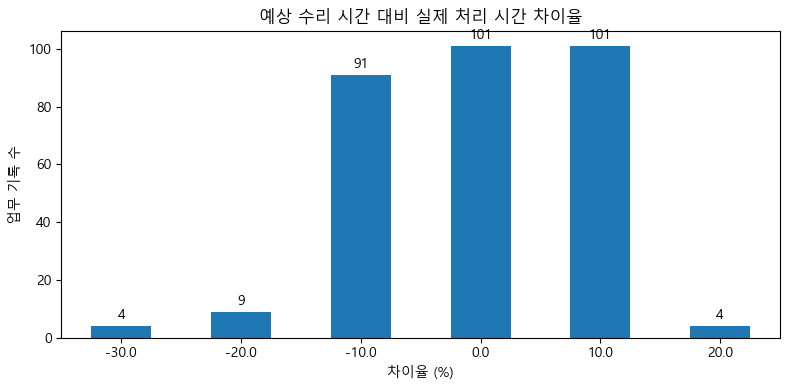

In [103]:
ax = error_distribution['기록 수'].plot.bar(
    figsize=(8, 4),
    rot=0
)

for bars in ax.containers:
    ax.bar_label(bars, padding=3)

ax.set_title('예상 수리 시간 대비 실제 처리 시간 차이율')
ax.set_xlabel('차이율 (%)')
ax.set_ylabel('업무 기록 수')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 중앙값은 예상과 실제가 일치했으며 차이율은 +-10%이내에 94.5%가 들어왔다.
- 따라서 예상 수리 시간이 실제 업무 시간을 잘 반영한다는 결과는 확인했다.

#### 14-4. 처리 시간 관련 요인 종합

##### 14-4-1. E 유형의 조사 완료 이후 처리 시간 분석
E 유형은 실제 수리 업무가 오래 걸리는 걸까? 아니면 조사가 끝나고 수리가 시작되기까지 오래 기다리는 걸까?

In [104]:
# 분석 대상: 일반 프로세스 339건
target_df = df[
    df['caseID'].isin(general_duration.index)
].copy()

# 주요 업무 시각 추출
survey_end = (
    target_df[
        (target_df['taskID'] == 'Survey') &
        (target_df['eventtype'] == 'complete')
    ]
    .groupby('caseID')['timestamp']
    .min()
)

repair_start = (
    target_df[
        target_df['taskID'].isin([
            'InternRepair', 'ImmediateRepair', 'ExternRepair'
        ]) &
        (target_df['eventtype'] == 'start')
    ]
    .groupby('caseID')['timestamp']
    .min()
)

repair_ready_end = (
    target_df[
        (target_df['taskID'] == 'RepairReady') &
        (target_df['eventtype'] == 'complete')
    ]
    .groupby('caseID')['timestamp']
    .min()
)

# RepairType 연결
repair_type = (
    target_df[['caseID', 'RepairType']]
    .replace('', pd.NA)
    .groupby('caseID')['RepairType']
    .first()
)

# 구간별 처리 시간 계산 (시간)
time_factors = pd.DataFrame(index=general_duration.index)

time_factors['RepairType'] = repair_type

time_factors['수리 시작 전 대기 시간'] = (
    repair_start - survey_end
).dt.total_seconds() / 3600

time_factors['수리 시작 이후 처리 시간'] = (
    repair_ready_end - repair_start
).dt.total_seconds() / 3600

time_factors['Survey → RepairReady 전체 시간'] = (
    repair_ready_end - survey_end
).dt.total_seconds() / 3600

# 세 구간을 모두 계산할 수 있는 케이스만 사용
time_factors = time_factors.dropna()

print('분석 케이스 수:', len(time_factors))
print('음수 시간:', (
    time_factors.iloc[:, 1:] < 0
).sum().sum())

# RepairType별 중앙값 비교
factor_summary = (
    time_factors.groupby('RepairType')
    .agg(
        케이스수=('RepairType', 'size'),
        수리_시작_전_대기_중앙값=('수리 시작 전 대기 시간', 'median'),
        수리_시작_이후_시간_중앙값=('수리 시작 이후 처리 시간', 'median'),
        전체_시간_중앙값=('Survey → RepairReady 전체 시간', 'median')
    )
    .round(1)
)

display(factor_summary)

분석 케이스 수: 338
음수 시간: 0


,케이스수,수리_시작_전_대기_중앙값,수리_시작_이후_시간_중앙값,전체_시간_중앙값
RepairType,,,,
B,46,0.0,3.2,3.2
E,143,25.2,4.0,33.0
P,149,0.0,2.2,2.2


> - E 유형에서 조사 완료 이후 시간이 긴 이유는 수리 시작 전 대기 시간이 길게 나타나는 현상과 관련있음
> - E 유형 143건 중 74건(51.7%)에서 수리 시작 전 대기 시간이 24시간을 초과

##### 14-4-2. RepairType별 수리 업무 구성과 대기·처리 시간 비교
E 유형의 긴 처리 시간은 수리 업무 자체보다 수리 시작 전 대기 시간과 관련되어 있는가?

**분석 순서**
- RepairType별 수리 업무 구성을 확인
- InternRepair 단독 케이스 중 시작·완료를 1:1로 연결할 수 있는 케이스를 선정 
- 동일한 케이스에서 수리 시작 전 대기 시간과 실제 수리 업무 처리 시간을 함께 비교

① 수리 유형별 업무 구성 확인

In [105]:
# 수리 업무 종류 정의
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

# 케이스별 수리 업무 구성
case_repair_tasks = (
    df.loc[
        df['caseID'].isin(time_factors.index) &
        df['taskID'].isin(repair_tasks),
        ['caseID', 'taskID']
    ]
    .groupby('caseID')['taskID']
    .agg(
        lambda tasks: ' + '.join(
            task for task in repair_tasks if task in set(tasks)
        )
    )
    .rename('수리 업무 구성')
)

# 수리 유형 및 대기 시간과 결합
repair_factor_compare = (
    time_factors[
        ['RepairType', '수리 시작 전 대기 시간']
    ]
    .join(case_repair_tasks)
)

# RepairType별 수리 업무 구성
repair_task_summary = pd.crosstab(
    repair_factor_compare['RepairType'],
    repair_factor_compare['수리 업무 구성']
)

display(repair_task_summary)

수리 업무 구성,ExternRepair,ImmediateRepair,ImmediateRepair + ExternRepair,InternRepair,InternRepair + ExternRepair,InternRepair + ImmediateRepair,InternRepair + ImmediateRepair + ExternRepair
RepairType,,,,,,,
B,8,8,0,27,3,0,0
E,0,0,0,137,6,0,0
P,16,105,11,8,2,5,2


> 같은 InternRepair 업무를 수행하는 케이스끼리 비교해도 E 유형의 대기 시간이 더 길게 나타날까?

② InternRepair만 수행한 케이스 비교

In [106]:
# InternRepair만 수행한 케이스
intern_only = repair_factor_compare[
    repair_factor_compare['수리 업무 구성'] == 'InternRepair'
].copy()

# InternRepair 시작·완료 이벤트 추출
intern_events = df.loc[
    df['caseID'].isin(intern_only.index) &
    (df['taskID'] == 'InternRepair') &
    df['eventtype'].isin(['start', 'complete']),
    ['caseID', 'eventtype', 'timestamp']
].copy()

# 케이스별 시작·완료 이벤트 수 확인
intern_counts = pd.crosstab(
    intern_events['caseID'],
    intern_events['eventtype']
)

# 시작과 완료가 각각 1개인 케이스만 선택
valid_ids = intern_counts.index[
    (intern_counts['start'] == 1) &
    (intern_counts['complete'] == 1)
]

# 시작·완료 시각
intern_start = (
    intern_events[intern_events['eventtype'] == 'start']
    .set_index('caseID')['timestamp']
)

intern_end = (
    intern_events[intern_events['eventtype'] == 'complete']
    .set_index('caseID')['timestamp']
)

# 대기 시간과 처리 시간 결합
intern_compare = intern_only.loc[
    valid_ids,
    ['RepairType', '수리 시작 전 대기 시간']
].copy()

intern_compare['InternRepair 처리 시간(시간)'] = (
    intern_end.loc[valid_ids] - intern_start.loc[valid_ids]
).dt.total_seconds() / 3600

# 결측 및 음수 시간 제외
intern_compare = intern_compare.dropna()

intern_compare = intern_compare[
    (intern_compare['수리 시작 전 대기 시간'] >= 0) &
    (intern_compare['InternRepair 처리 시간(시간)'] >= 0)
]

# RepairType별 시간 비교
intern_time_summary = (
    intern_compare.groupby('RepairType')
    .agg(
        케이스수=('RepairType', 'size'),
        대기_시간_중앙값=('수리 시작 전 대기 시간', 'median'),
        처리_시간_중앙값=('InternRepair 처리 시간(시간)', 'median')
    )
    .round(1)
)

print('분석 케이스 수:', len(intern_compare))
display(intern_time_summary)

분석 케이스 수: 160


,케이스수,대기_시간_중앙값,처리_시간_중앙값
RepairType,,,
B,25,0.0,3.2
E,127,25.9,4.0
P,8,0.9,4.0


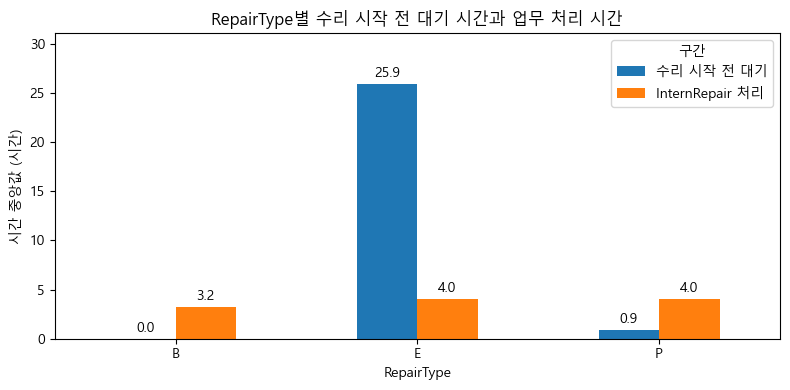

In [107]:
plot_data = intern_time_summary[
    ['대기_시간_중앙값', '처리_시간_중앙값']
].rename(columns={
    '대기_시간_중앙값': '수리 시작 전 대기',
    '처리_시간_중앙값': 'InternRepair 처리'
})

ax = plot_data.plot.bar(figsize=(8, 4), rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f', padding=3)

ax.set_title('RepairType별 수리 시작 전 대기 시간과 업무 처리 시간')
ax.set_xlabel('RepairType')
ax.set_ylabel('시간 중앙값 (시간)')
ax.legend(title='구간')
ax.set_ylim(0, plot_data.max().max() * 1.2)

plt.tight_layout()
plt.show()

> 수리 업무 구성을 동일하게 제한해도 E 유형의 긴 대기 시간이 유지된다

**분석 결과 기록**

- 동일하게 InternRepair만 수행한 케이스에서도 E 유형은 수리 시작 전 대기 시간이 25.9시간으로 B·P 유형보다 길게 나타남
- 반면 실제 InternRepair 업무 처리 시간은 E·P 유형 모두 4.0시간
- 따라서 E 유형의 긴 조사 이후 처리 시간은 수리 수행 시간보다 수리 시작 전 대기 시간과 더 밀접하게 관련되어 있다.


----

## 15. 분석 결과 종합 및 개선안 도출

**분석 목적:** 발견한 문제를 근거로 실행 가능한 개선 방안을 제안한다.

**앞 단계와의 연결·다음 작업:** 8~14단계에서 확인한 사실과 가설을 구분해 개선 우선순위를 정한다. 최종 제안이 정리되면 기존 PPT 구성 단계에서 메시지와 근거 자료를 연결한다.

**산출물:** 문제 → 근거 → 개선안 → 검증 지표로 연결된 최종 제안

> **주의:** 날짜 복원 불확실성과 이벤트 기록의 한계를 명시한다. 근거가 부족한 설명은 확정 결론 대신 추가 검증 과제로 남긴다.


#### 15-1. 주요 문제 및 개선 우선순위 선정

**주요 문제**
1. `ArrangeSurvey → Survey` 구간이 전체 처리 시간 합계의 70.8%를 차지하여 가장 우선적인 개선 검토 대상으로 선정됨
2. E 유형에서는 `Survey` 완료 이후 수리 시작 전 대기 시간이 상대적으로 길게 나타남
3. `ArrangeSurvey` 내부에서는 시작·완료 담당자가 다른 경우 처리 시간이 길게 나타나는 관련성이 확인됨

**분석 결과 및 우선순위**
1. 전체 처리 시간 단축을 위한 1순위 검토 구간으로 `ArrangeSurvey → Survey`를 선정
2. E 유형의 수리 시작 전 대기를 2순위 검토 대상으로 설정
3. 담당자 변경과 긴 처리 시간의 관계는 확인되었으나 실제 지연 원인은 확인되지 않아 추가 검증이 필요

**분석의 한계**
- 시간 분석은 1970년 기록을 활용한 탐색적 결과이며 실제 날짜의 정확성이 검증되지 않음
- 긴 대기 시간이 정상적인 업무 절차인지 운영상 비효율인지 구분할 수 없음
- 현재 데이터만으로 지연의 구체적인 원인을 확정하거나 개선 효과를 산출하기 어려움

### 15-2. (1순위) ArrangeSurvey → Survey 구간 개선 방안

**문제 정의**
| 지표 | 분석 결과 |
|---|---|
| 분석 대상 | 일반 프로세스 339건 |
| `ArrangeSurvey → Survey` 대기 시간 중앙값 | 54.5시간 |
| 대기 시간 P90 | 195.7시간 |
| 전체 처리 시간 합계에서 차지하는 비중 | 70.8% |
| 24시간 초과 대기 | 211건 (62.2%) |
- `ArrangeSurvey → Survey` 구간은 전체 처리 시간 합계의 70.8%를 차지하는 주요 지연 검토 구간임
- 다만 조사 예정일과 담당자 배정 정보가 없어 정상적인 예약 대기와 실제 착수 지연을 구분하기 어려움

**개선 방안**
1. `ArrangeSurvey` 완료 시 조사 예정일과 담당자 배정 정보를 기록하여 대기 원인을 구분함
2. 조사 예정일이 지났음에도 `Survey`가 시작되지 않은 케이스를 별도로 관리, 지연 사유에 따라 재배정 또는 일정 조정을 진행
3. E와P 유형을 중심으로 조사 가능 일정과 예약 대기 현황을 분석하고 일정 배정 방식의 개선 가능성을 검토
    - 특정 유형에서 예약 대기가 길어지고 반복된다면 담당자별 예약 현황을 공유하고 가능한 조사 일정을 더 빠르게 배정 

**효과 검증 지표**
| 지표 | 정의 | 계산식 | 활용 목적 |
|---|---|---|---|
| **조사 착수 지연 시간** | 조사 예정 시각부터 실제 `Survey` 시작까지 초과한 시간 | `max(0, 실제 Survey 시작 시각 − 조사 예정 시각)` | 예정된 조사 일정의 준수 여부 평가 |
| **예정일 초과 미착수율** | 조사 예정 시각이 지난 케이스 중 `Survey`가 아직 시작되지 않은 비율 | `(예정 시각 초과 미착수 케이스 수 / 예정 시각이 지난 전체 케이스 수) × 100` | 미착수 사례 조기 발견 및 대응 |
- 개선 전후의 조사 시작까지 소요 시간과 전체 처리 시간을 함께 비교하여 실제 처리 기간 단축 여부를 확인
- 수리 유형과 접수 채널별 차이를 고려하여 개선 효과를 평가

**기대 효과**
- 정상적인 예약 대기와 운영상 지연을 구분하여 관리 가능
- 일정 배정 및 조사 착수 과정의 지연 사례를 조기에 발견하고 대응할 수 있음
- 실제 지연을 줄일 수 있는 구간에 집중하여 전체 처리 시간 단축을 추진할 수 있음

### 15-3. (2순위) E 유형의 수리 시작 전 대기 시간 개선 방안
E 유형에서 Survey가 완료된 후 실제 수리 업무가 시작되기까지 시간이 오래 걸리는 문제에 집중

**문제 정의**

| 지표 | 분석 결과 |
|---|---|
| 분석 대상 | 시간 분석 기준을 충족한 E 유형 143건 |
| `Survey complete → 첫 수리 start` 대기 시간 중앙값 | 25.2시간 |
| `Survey complete → RepairReady complete` 전체 처리 시간 중앙값 | 33.0시간 |
| `첫 수리 start → RepairReady complete` 처리 시간 중앙값 | 4.0시간 |
| `InternRepair` 단독 및 시작·완료 1:1 연결 E 유형 | 127건 |
| 해당 집단의 수리 시작 전 대기 시간 중앙값 | 25.9시간 |
| 해당 집단의 `InternRepair` 처리 시간 중앙값 | 4.0시간 |

- E 유형은 `Survey` 완료 이후 실제 수리가 시작되기까지의 대기 시간이 상대적으로 길게 나타남
- 동일하게 `InternRepair`만 수행한 케이스에서도 E 유형은 B·P 유형보다 수리 시작 전 대기 시간이 길게 나타남
- 반면 실제 `InternRepair` 업무의 처리 시간 차이는 상대적으로 작아 E 유형의 긴 처리 시간은 수리 시작 전 대기 구간과 관련이 있는 것으로 판단됨
- 다만 현재 데이터에는 `Survey` 완료 이후 실제 수리 시작까지의 진행 과정이 기록되어 있지 않아 대기 원인을 확인하기 어려움

**개선 방안**

1. `Survey` 완료 이후 실제 수리 시작까지의 진행 상태와 지연 사유를 기록하여 대기 시간이 발생하는 원인을 확인
2. 수리 예정 시각과 담당자 배정 상태를 추가로 관리하고 예정 시각을 초과한 미착수 케이스를 별도로 확인하여 필요한 조치를 진행
3. E 유형을 중심으로 수리 시작 전 대기 현황을 분석하고 반복적으로 발생하는 지연 원인에 따라 업무 절차와 일정 관리 방식의 개선을 검토
   - 특정 단계에서 지연이 반복된다면 해당 단계의 처리 절차를 점검하고 실제 원인에 맞는 개선 방안을 적용

**효과 검증 지표**

| 지표 | 정의 | 계산식 | 활용 목적 |
|---|---|---|---|
| **수리 시작 전 대기 시간** | `Survey` 완료부터 첫 수리 업무 시작까지 소요된 시간 | `첫 수리 start − Survey complete` | 조사 완료 이후 수리 착수까지의 전체 대기 시간 확인 |
| **수리 착수 지연 시간** | 수리 예정 시각보다 실제 수리가 늦게 시작된 시간 | `max(0, 실제 수리 시작 시각 − 수리 예정 시각)` | 예정된 수리 일정의 준수 여부 평가 |
| **예정 시각 초과 미착수율** | 수리 예정 시각이 지난 케이스 중 아직 수리가 시작되지 않은 비율 | `(예정 시각 초과 미착수 케이스 수 / 예정 시각이 지난 전체 케이스 수) × 100` | 미착수 사례 조기 발견 및 대응 |

- 개선 전후의 수리 시작 전 대기 시간과 전체 처리 시간을 함께 비교하여 실제 처리 기간 단축 여부를 확인
- 수리 유형과 수리 업무 구성을 고려하여 개선 효과를 평가
- 수리 예정 시각과 지연 사유는 현재 데이터에 없으므로 신규 기록을 통해 기준값을 확보한 후 개선 효과를 검증

**기대 효과**

- `Survey` 완료 이후 실제 수리 시작까지 발생하는 대기 원인을 구체적으로 파악할 수 있음
- 예정된 수리 시각을 초과한 미착수 케이스를 조기에 발견하고 대응할 수 있음
- 반복적으로 발생하는 지연 원인을 바탕으로 업무 절차와 일정 관리 방식을 개선할 수 있음
- 불필요한 대기 시간을 줄여 E 유형의 전체 처리 시간 단축을 추진할 수 있음

**한계**

- 수리 시작 전 대기 시간이 모두 불필요한 지연이라는 근거는 없음
- 현재 데이터만으로 실제 지연 원인을 특정할 수 없음
- 1970년 날짜의 정확성이 검증되지 않아 기존 시간 분석 결과는 탐색적으로 해석해야 함
- 각 구간의 중앙값은 개별적으로 계산했으므로 합계가 전체 처리 시간 중앙값과 일치하지 않을 수 있음

### 15-4. 접수 채널 및 담당자 변경에 따른 ArrangeSurvey 처리 시간 개선 방안


**문제 정의**

| 지표 | 분석 결과 |
|---|---|
| 분석 대상 | `ArrangeSurvey` 809건 |
| 처리 시간 중앙값 | 4분 |
| 처리 시간 P90 | 404.8분 |
| 1시간 초과 처리 | 194건 (24.0%) |
| Web 접수 1시간 초과율 | 109건 / 207건 (52.7%) |
| Letter 접수 1시간 초과율 | 85건 / 175건 (48.6%) |
| Phone·Personal 접수 1시간 초과 | 0건 |
| 시작·완료 담당자가 다른 케이스 | 105건 (13.0%) |
| 담당자가 동일한 경우 처리 시간 중앙값 | 4분 |
| 담당자가 다른 경우 처리 시간 중앙값 | 332분 |
| 담당자가 동일한 Web·Letter 접수의 1시간 초과 사례 | 89건 |

- `ArrangeSurvey`는 처리 시간 중앙값이 4분이지만 P90은 404.8분으로 일부 케이스(10%)에서 긴 처리 시간이 발생함
- 1시간을 초과한 194건은 모두 Web·Letter 접수에서 나타나 접수 채널별 처리 시간에 뚜렷한 차이가 확인됨
- 시작·완료 담당자가 다른 105건도 모두 Web·Letter 접수에서 발생했으며 담당자가 동일한 경우보다 처리 시간이 길게 나타남
- 담당자가 동일한 Web·Letter 접수에서도 89건의 1시간 초과 사례가 존재해 담당자 차이만으로 긴 처리 시간을 설명하기 어려움
- 현재 데이터에는 채널별 상세 처리 과정과 담당자 변경 사유가 없어 처리 시간이 길어지는 직접적인 원인을 확인하기는 어려움

**개선 방안**

1. Web·Letter 접수에서 `ArrangeSurvey` 처리 시간이 길어지는 원인을 확인하기 위해 채널별 업무 진행 상태와 처리 지연 사유를 기록
2. `ArrangeSurvey` 시작·완료 담당자가 다른 케이스의 변경 사유와 업무 전달 시각을 기록하여 실제 인수인계 과정에서 지연이 발생하는지 확인
3. 담당자가 동일한 Web·Letter 접수에서도 긴 처리 시간이 발생하는 원인을 별도로 분석하여 담당자 변경 외의 관련 요인을 확인
4. 확인된 원인에 따라 접수 채널별 업무 처리 절차와 담당자 간 업무 전달 방식의 개선을 검토
   - 업무 전달 과정에서 지연이 확인된다면 전달 및 인수 절차를 개선
   - 특정 접수 채널의 업무 처리 단계에서 지연이 확인된다면 해당 단계의 처리 절차를 점검

**효과 검증 지표**

| 지표 | 정의 | 계산식 | 활용 목적 |
|---|---|---|---|
| **ArrangeSurvey 처리 시간** | 업무 시작부터 완료까지 소요된 시간 | `ArrangeSurvey complete − ArrangeSurvey start` | 업무 처리 시간의 변화 확인 |
| **접수 채널별 1시간 초과 처리율** | 채널별로 처리 시간이 1시간을 초과한 케이스의 비율 | `(채널별 1시간 초과 케이스 수 / 해당 채널 전체 분석 케이스 수) × 100` | Web·Letter의 장시간 처리 사례 감소 여부 확인 |
| **담당자 차이 여부별 처리 시간** | 시작·완료 담당자가 동일한 집단과 다른 집단의 처리 시간 | `각 집단의 ArrangeSurvey 처리 시간 중앙값 및 P90` | 담당자 차이 여부에 따른 처리 시간 변화 확인 |
| **업무 인수 대기 시간** | 실제 업무 전달부터 다음 담당자가 업무를 인수하기까지 소요된 시간 | `업무 인수 시각 − 업무 전달 시각` | 인수인계 과정의 실제 지연 여부 확인 |

- 개선 전후의 `ArrangeSurvey` 처리 시간 중앙값과 P90을 비교하여 장시간 처리 사례가 감소하는지 확인
- Web·Letter 접수를 구분하고 담당자 차이 여부에 따른 처리 시간 변화도 함께 비교
- 전체 처리 시간의 변화를 함께 확인하여 `ArrangeSurvey` 개선이 전체 프로세스에도 연결되는지 검증
- 업무 전달 및 인수 시각은 현재 데이터에 없으므로 신규 기록(담당자 변경 시 업무 인계 기록)을 확보한 후 해당 지표를 산출

**기대 효과**

- Web·Letter 접수에서 긴 처리 시간이 발생하는 원인을 구체적으로 파악할 수 있음
- 담당자 변경과 관계없이 발생하는 지연을 구분하여 관리할 수 있음
- 실제 인수인계 과정에서 지연이 확인되면 관련 절차를 개선할 수 있음
- 장시간 처리 사례를 줄이고 `ArrangeSurvey` 업무의 처리 시간을 단축 할 수 있음

**한계**

- 시작·완료 담당자가 다르다는 사실만으로 실제 업무 인수인계가 발생했다고 단정할 수 없음
- 접수 채널과 담당자 차이 여부는 처리 시간과 관련되어 있지만 실제 지연 원인으로 확인된 것은 아님
- `ArrangeSurvey` 내부 처리 시간과 `ArrangeSurvey → Survey` 대기 시간은 서로 다른 지표이므로 구분해서 해석해야 함
- 1시간 초과 기준은 처리 시간 분포를 분석하기 위해 설정한 탐색적 기준이며 실제 운영상의 지연 기준으로 검증된 것은 아님
- 1970년 날짜의 정확성이 검증되지 않아 기존 처리 시간 분석 결과는 탐색적으로 해석해야 함

### 15-5. 개선 과제 우선순위 및 최종 제안

**개선 과제 우선순위**

| 우선순위 | 개선 대상 | 주요 분석 결과 | 개선 방향 |
|---|---|---|---|
| **1순위** | `ArrangeSurvey → Survey` | 대기 시간 중앙값 54.5시간 / 전체 처리 시간 합계의 70.8% | 조사 일정 및 미착수 현황 관리 |
| **2순위** | E 유형 `Survey → 첫 수리 start` | 대기 시간 중앙값 25.2시간 / `InternRepair` 단독 케이스에서도 긴 대기 확인 | 수리 착수 전 대기 원인 파악 및 일정 관리 |
| **3순위** | `ArrangeSurvey` 내부 처리 | P90 404.8분 / Web·Letter에서 1시간 초과 사례 194건 | 채널별 장시간 처리 원인 및 담당자 변경 관련 요인 확인 |

**우선순위 선정 근거**

1. **1순위 — 조사 착수 전 대기 시간**
   - 전체 처리 시간 합계에서 가장 큰 비중을 차지하는 구간으로 개선 가능성을 우선 검토할 필요가 있음
   - 다만 정상적인 예약 대기가 포함될 수 있으므로 조사 예정 시각과 실제 착수 시각을 추가로 기록하여 지연 여부를 구분해야 함

2. **2순위 — E 유형 수리 시작 전 대기 시간**
   - E 유형은 `Survey` 완료 이후 실제 수리 시작까지의 대기 시간이 상대적으로 길게 나타남
   - 동일한 `InternRepair` 업무를 수행한 케이스에서도 대기 시간 차이가 확인되어 추가 분석이 필요함
   - 수리 착수 전 진행 상태와 지연 사유를 기록하고 확인된 원인에 따라 개선 방안을 마련해야 함

3. **3순위 — ArrangeSurvey 내부 처리 시간**
   - 전체 처리 시간에서 차지하는 비중은 1순위 구간보다 작지만 일부 케이스에서 긴 처리 시간이 확인됨
   - 특히 Web·Letter 접수에서 1시간 초과 사례가 집중되어 채널별 업무 처리 과정의 차이를 확인할 필요가 있음
   - 담당자 변경 여부도 관련 요인으로 검토하되 실제 지연 원인으로 단정하지 않음

**단계별 실행 방안**

| 단계 | 실행 내용 | 목적 |
|---|---|---|
| 1단계 | 조사 예정 시각과 수리 예정 시각 및 업무 진행 상태를 추가 기록 | 정상적인 대기와 실제 지연 구분 |
| 2단계 | 장시간 대기 사례의 지연 사유와 업무 처리 과정을 분석 | 반복적으로 발생하는 지연 원인 확인 |
| 3단계 | 확인된 원인을 바탕으로 우선순위가 높은 구간부터 개선안을 시범 적용 | 실제 개선 가능성 검증 |
| 4단계 | 개선 전후의 구간별 대기 시간과 전체 처리 시간을 비교 | 개선 효과와 부작용 확인 |

**핵심 효과 검증 지표**

| 구분 | 주요 지표 | 검증 목적 |
|---|---|---|
| 조사 착수 전 대기 | `ArrangeSurvey → Survey` 대기 시간 중앙값 및 P90 | 조사 시작까지의 대기 시간 변화 확인 |
| 조사 일정 준수 | 조사 착수 지연 시간 및 예정 시각 초과 미착수율 | 실제 일정 초과 사례 감소 여부 확인 |
| 수리 착수 전 대기 | `Survey → 첫 수리 start` 대기 시간 중앙값 및 P90 | E 유형의 수리 시작 전 대기 시간 변화 확인 |
| 내부 업무 처리 | `ArrangeSurvey` 처리 시간 P90 및 채널별 1시간 초과 처리율 | 장시간 처리 사례 감소 여부 확인 |
| 최종 성과 | 케이스별 전체 처리 시간 중앙값 및 P90 | 개별 업무 개선이 전체 처리 기간 단축으로 이어지는지 확인 |

- 개선 효과는 수리 유형과 접수 채널을 구분하여 비교
- 구간별 처리 시간이 줄어들더라도 전체 처리 시간이 단축되지 않았다면 다른 구간으로 지연이 이동했는지 확인
- 신규 지표는 추가 데이터를 확보한 후 기준값을 설정하여 개선 전후를 비교

**기대 효과**

- 조사 및 수리 착수 과정에서 정상적인 대기와 실제 지연을 구분하여 관리할 수 있음
- 장시간 처리 사례가 반복되는 구간을 확인하고 원인에 맞는 개선 방안을 마련할 수 있음
- 구간별 개선 효과를 전체 처리 시간과 함께 검증하여 실질적인 프로세스 효율화를 추진할 수 있음

**분석의 한계 및 추가 검증 사항**

- 현재 데이터만으로 장시간 대기의 원인을 특정하거나 해당 시간을 모두 단축 가능한 지연으로 판단할 수 없음
- 각 개선 과제의 분석 대상과 표본 수가 다르므로 수치를 직접 비교하여 개선 효과의 크기를 확정할 수 없음
- 시간 분석에 사용한 1970년 날짜의 정확성이 검증되지 않아 기존 결과는 탐색적 근거로 활용해야 함
- 실제 개선 효과는 신뢰할 수 있는 시간 데이터와 추가 업무 기록을 확보한 뒤 검증해야 함

----